### Imports

In [20]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import altair as alt
from altair import datum
alt.data_transformers.disable_max_rows()
from sklearn import manifold
from openTSNE import TSNE
from openTSNE import TSNE as OpenTSNE
from umap import UMAP
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.manifold import trustworthiness
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.feature_selection import f_classif

### Dataset description

**Which dataset are you using? What is it about?**  
We use the *Lifestyle, Fitness and Wellness* dataset, where each row corresponds to an individual workout session together with personal and contextual information. It contains demographics (age, gender), body composition (weight, height, BMI, lean mass, fat percentage), training variables (heart rate statistics, session duration, workout type, experience level, workout frequency) and nutrition / energy features (calories burned, macros, protein per kg, calorie balance, expected burn, etc.).

**Where did you get this dataset from? How was it generated?**  
The data comes from the public Kaggle dataset *“Life Style Data”* (https://www.kaggle.com/datasets/jockeroika/life-style-data). It was created as a synthetic but realistic-looking fitness-tracking dataset, combining plausibly generated workout and nutrition logs rather than real personal health records.

**What is the dataset size?**  
After basic cleaning (dropping rows with too many missing values), the dataset contains about **20,000 rows** and roughly **60 columns**. For the analysis, we work with around **45 features**: all numeric variables plus one-hot encoded versions of categorical attributes such as gender, workout type, and calorie-burn category.

**What do you want to analyze?**  
We want to understand whether these high-dimensional fitness and lifestyle measurements form meaningful groups when projected to 2D and clustered. Concretely, we look for typical “profiles”, such as heavy high-calorie lifters, lean high-protein athletes, or low-activity low-intake users, and how they differ in body composition, training load, and nutrition.

**What are you expecting to see?**  
We expect the main structure to be driven by body size and composition (weight, BMI, lean mass), energy intake and expenditure (calories, macros, calorie balance), and training behavior (exercise intensity, session duration, experience level). In the 2D projections and clusterings, we anticipate several reasonably separated clusters along these dimensions rather than a single homogeneous cloud of points.


### Data preprocessing and feature construction

The dataset is loaded and prepared for dimensionality reduction and clustering.  
Numeric attributes are selected, and key categorical attributes (such as gender, workout type, and calorie burn category) are transformed into numerical indicator columns. These are combined into a single feature table.

Rows with too many missing values are removed. Remaining missing entries are filled using median values, and all features are standardized to comparable scales. The result is a clean, scaled feature matrix and a processed data table that still contains the original information for interpretation.


In [21]:
file_main = "/content/Final_data.csv"

assert os.path.isfile(file_main), f"Main file not found: {file_main}"
df = pd.read_csv(file_main)

# --- 1) numeric base features (drop precomputed projections etc.) ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

drop_num = [
    "pca_x", "pca_y",
    "tsne_x", "tsne_y",
    "Burns Calories (per 30 min)_bc"  # huge magnitude, already represented elsewhere
]
num_cols = [c for c in num_cols if c not in drop_num]

# --- 2) categorical columns you want to include ---
cat_candidates = ["Gender", "Workout_Type", "Burns_Calories_Bin"]
cat_cols = [c for c in cat_candidates if c in df.columns]

if cat_cols:
    df_cat = pd.get_dummies(df[cat_cols], drop_first=True, prefix=cat_cols)
else:
    df_cat = pd.DataFrame(index=df.index)

# --- 3) full feature frame BEFORE filtering rows ---
feat_df_full = pd.concat([df[num_cols], df_cat], axis=1)

# --- 4) drop rows with > 50% missing in these features ---
row_nan_frac = feat_df_full.isna().mean(axis=1)
keep_mask = row_nan_frac <= 0.5

feat_df = feat_df_full.loc[keep_mask].copy()
df_proc = df.loc[keep_mask].reset_index(drop=True).copy()

FEATURES = feat_df.columns.tolist()
print("Using", len(FEATURES), "features (numeric + encoded categoricals)")

# --- 5) impute + scale on feat_df ---
imp = SimpleImputer(strategy="median")
X_raw = imp.fit_transform(feat_df)

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

# --- 6) make sure df_proc also has the encoded columns ---
encoded_cols = [c for c in feat_df.columns if c not in df_proc.columns]
for col in encoded_cols:
    df_proc[col] = feat_df[col].values

print("Prepared dataframe shape:", df_proc.shape)
print("Number of features used:", len(FEATURES))


Using 45 features (numeric + encoded categoricals)
Prepared dataframe shape: (20000, 61)
Number of features used: 45


#Data Snippet

In [22]:
feat_df.head()


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),...,cal_balance,lean_mass_kg,expected_burn,Gender_Male,Workout_Type_HIIT,Workout_Type_Strength,Workout_Type_Yoga,Burns_Calories_Bin_Low,Burns_Calories_Bin_Medium,Burns_Calories_Bin_Very High
0,34.91,65.27,1.62,188.58,157.65,69.05,1.00,1080.90,26.800377,1.50,...,725.10,47.777394,685.1600,True,False,True,False,False,True,False
1,23.37,56.41,1.55,179.43,131.75,73.18,1.37,1809.91,27.655021,1.90,...,-232.91,40.809803,978.6184,False,True,False,False,False,False,False
2,33.20,58.98,1.67,175.04,123.95,54.96,0.91,802.26,24.320821,1.88,...,805.74,44.635580,654.5266,False,False,False,False,False,False,False
3,38.69,93.78,1.70,191.21,155.10,50.07,1.10,1450.79,32.813572,2.50,...,1206.21,63.007432,773.6300,False,True,False,False,False,False,False
4,45.09,52.42,1.88,193.58,152.88,70.84,1.08,1166.40,17.307319,2.91,...,303.60,43.347504,711.4176,True,False,True,False,True,False,False


### Dimensionality reduction

We down-project the high-dimensional feature space to 2D using **PCA** (linear) and **t-SNE** (non-linear) and assess both with **trustworthiness** to ensure that local structure is reasonably preserved. We also tried **UMAP**, but it could not be used reliably in this environment, so the analysis focuses on PCA and t-SNE.


In [23]:
# --- PCA ---
pca_xy = PCA(
    n_components=2,
    random_state=42
).fit_transform(X)

# --- t-SNE (using openTSNE for potential GPU acceleration) ---
tsne_xy = OpenTSNE(
    n_components=2,
    perplexity=min(30, max(5, X.shape[0] // 100)),
    metric="euclidean",
    random_state=42,
    n_jobs=-1

).fit(X)

# --- attach projections to dataframe ---
df_proc["pca_x"], df_proc["pca_y"] = pca_xy[:, 0], pca_xy[:, 1]
df_proc["tsne_x"], df_proc["tsne_y"] = tsne_xy[:, 0], tsne_xy[:, 1]


n_samples = len(X)
sample_size = min(5000, max(1000, n_samples // 100))  # max 5000 points
if n_samples > sample_size:
    print(f"Dataset has {n_samples} samples. Computing trustworthiness on random sample of {sample_size} points...")
    sample_idx = np.random.RandomState(42).choice(n_samples, sample_size, replace=False)
    X_sample = X[sample_idx]
    pca_sample = pca_xy[sample_idx]
    tsne_sample = tsne_xy[sample_idx]
else:
    X_sample = X
    pca_sample = pca_xy
    tsne_sample = tsne_xy

tw_pca = trustworthiness(X_sample, pca_sample, n_neighbors=min(10, len(X_sample) // 2 - 1))
tw_tsne = trustworthiness(X_sample, tsne_sample, n_neighbors=min(10, len(X_sample) // 2 - 1))

print(f"Trustworthiness (n=10, computed on {len(X_sample)} sample points):")
print(f"  PCA={tw_pca:.4f}, t-SNE={tw_tsne:.4f}")

Dataset has 20000 samples. Computing trustworthiness on random sample of 1000 points...
Trustworthiness (n=10, computed on 1000 sample points):
  PCA=0.7948, t-SNE=0.8877


### Choice of number of clusters

We evaluated all clustering settings using three internal quality metrics:

- **Silhouette score** (higher is better): how well points fit into their own cluster vs. others.  
- **Davies–Bouldin index** (lower is better): how compact and well-separated clusters are.  
- **Calinski–Harabasz index** (higher is better): ratio of between-cluster to within-cluster variance.

Based on these metrics:

- In **PCA space**, both K-Means and Agglomerative work best with **6 clusters**, so we use `k = 6` as our main solution.  
- In **t-SNE space**, K-Means performs well for `k = 3` and `k = 7`; we keep **3 clusters** as the simpler, easier-to-interpret view.  
- Agglomerative on t-SNE is strongest around **6 clusters**, so we also analyze `k = 6` there.

We additionally tested **DBSCAN**, but typical parameter settings either merged most points into one cluster or produced many tiny, unstable clusters. For this reason, we do not use DBSCAN in the final analysis.


In [25]:
spaces = {
    "PCA":  pca_xy,
    "tSNE": tsne_xy,
}

k_values = range(3,8)

def eval_clustering_in_space(X_eval, algo="kmeans"):
    results = []
    for k in k_values:
        if algo == "kmeans":
            model = KMeans(n_clusters=k, random_state=42)
            labels = model.fit_predict(X_eval)
        elif algo == "agglo":
            model = AgglomerativeClustering(n_clusters=k, linkage="ward")
            labels = model.fit_predict(X_eval)
        else:
            raise ValueError("algo must be 'kmeans' or 'agglo'")

        sil = silhouette_score(X_eval, labels)
        db  = davies_bouldin_score(X_eval, labels)
        ch  = calinski_harabasz_score(X_eval, labels)
        results.append((k, sil, db, ch))
    return results

results = {}

for name, X_eval in spaces.items():
    results[(name, "kmeans")] = eval_clustering_in_space(X_eval, algo="kmeans")
    results[(name, "agglo")]  = eval_clustering_in_space(X_eval, algo="agglo")

for (space_name, algo), res in results.items():
    print(f"\n=== {algo.upper()} in {space_name} space ===")
    print("k  |  silhouette  |  davies-bouldin  |  calinski-harabasz")
    for k, sil, db, ch in res:
        print(f"{k:2d} |  {sil:10.4f} |  {db:16.4f} |  {ch:20.1f}")



=== KMEANS in PCA space ===
k  |  silhouette  |  davies-bouldin  |  calinski-harabasz
 3 |      0.3835 |            0.9133 |               14618.5
 4 |      0.3445 |            0.9202 |               14539.7
 5 |      0.3671 |            0.8350 |               15160.1
 6 |      0.3706 |            0.7930 |               15778.4
 7 |      0.3535 |            0.8421 |               14977.8

=== AGGLO in PCA space ===
k  |  silhouette  |  davies-bouldin  |  calinski-harabasz
 3 |      0.3083 |            0.9685 |                9477.8
 4 |      0.2874 |            1.0426 |               10824.5
 5 |      0.3058 |            0.8655 |               12038.9
 6 |      0.3095 |            0.8492 |               12996.8
 7 |      0.2938 |            0.9138 |               12416.8

=== KMEANS in tSNE space ===
k  |  silhouette  |  davies-bouldin  |  calinski-harabasz
 3 |      0.3548 |            0.8978 |               14026.2
 4 |      0.3646 |            0.8444 |               16489.0
 5 |   

In [26]:
# --- PCA space ---
best_k_pca_kmeans = 6
best_k_pca_agglo  = 6

kmeans_pca = KMeans(
    n_clusters=best_k_pca_kmeans,
    random_state=42
).fit(pca_xy)
df_proc["kmeans_pca"] = kmeans_pca.labels_

agg_pca = AgglomerativeClustering(
    n_clusters=best_k_pca_agglo,
    linkage="ward"
)
df_proc["agglo_pca"] = agg_pca.fit_predict(pca_xy)

# --- t-SNE space ---
best_k_tsne_kmeans = 3
best_k_tsne_agglo  = 6

kmeans_tsne = KMeans(
    n_clusters=best_k_tsne_kmeans,
    random_state=42
).fit(tsne_xy)
df_proc["kmeans_tsne"] = kmeans_tsne.labels_

agg_tsne = AgglomerativeClustering(
    n_clusters=best_k_tsne_agglo,
    linkage="ward"
)
df_proc["agglo_tsne"] = agg_tsne.fit_predict(tsne_xy)


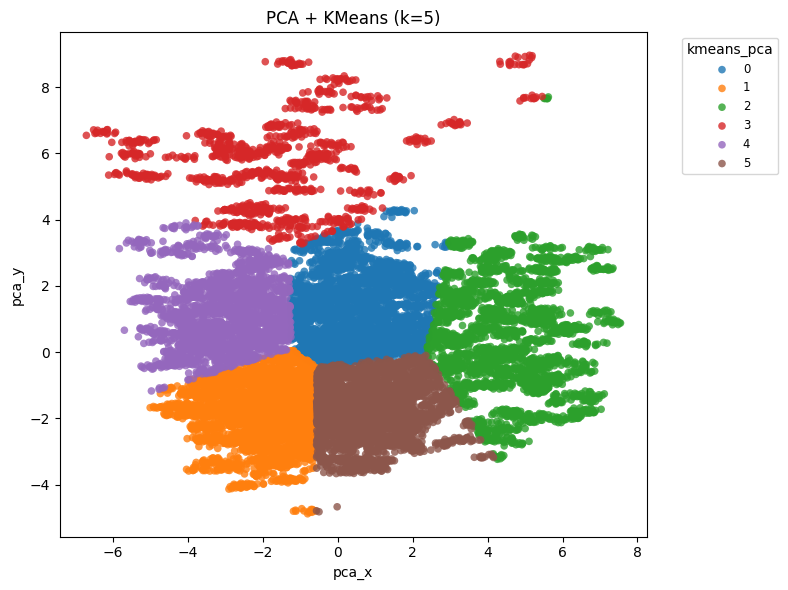

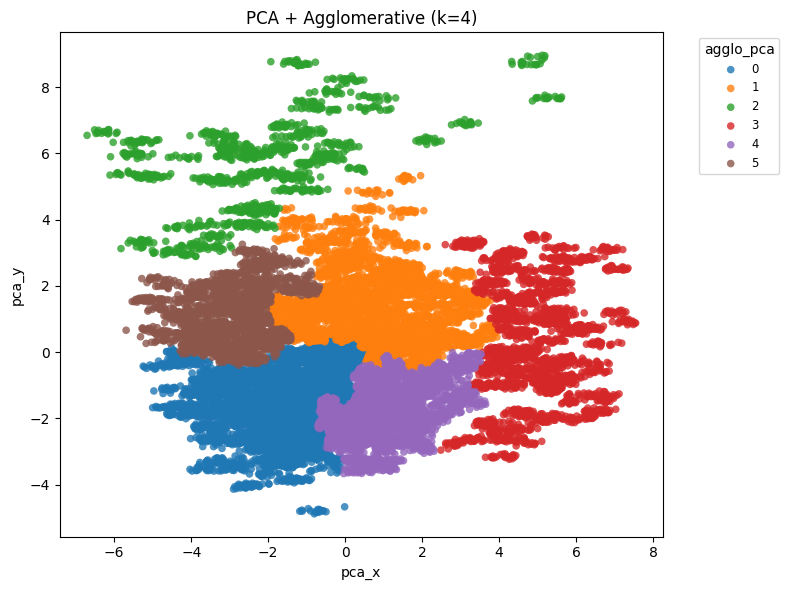

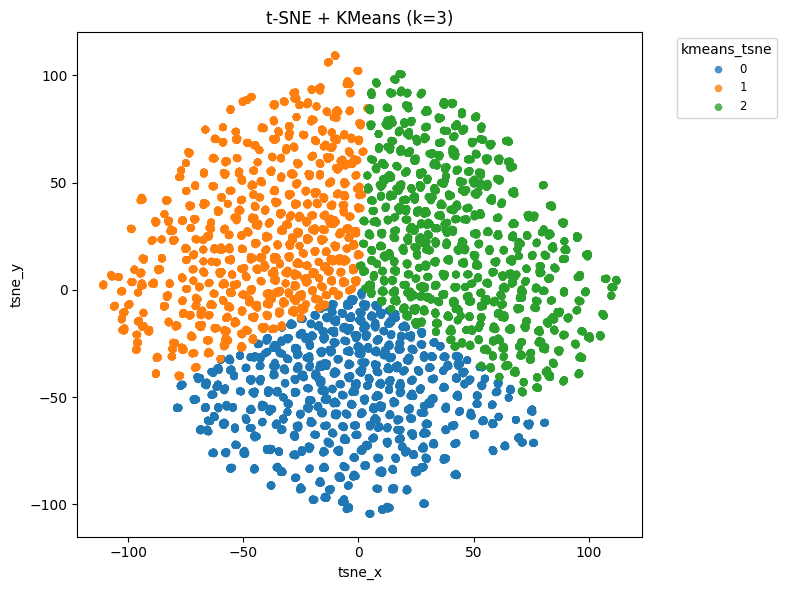

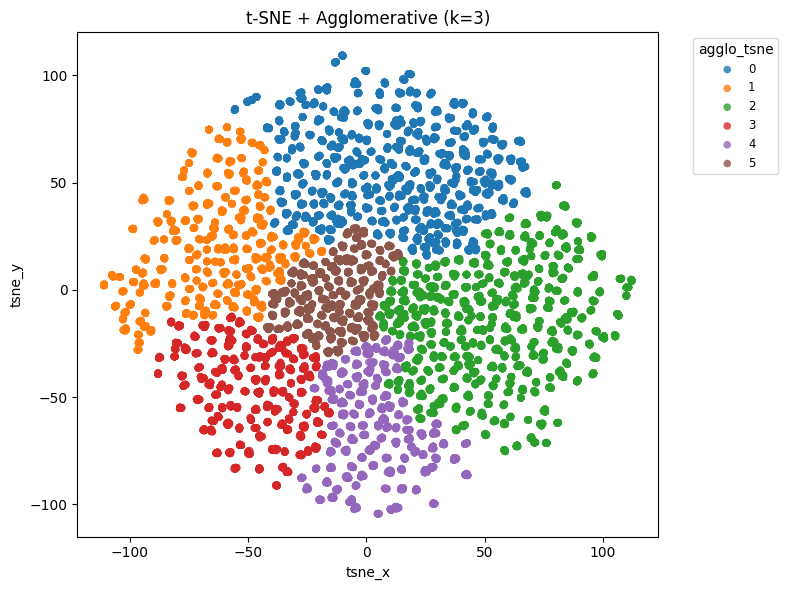

In [27]:
def scatter_clusters(df, x, y, cluster_col, title=None):
    plt.figure(figsize=(8, 6))

    if cluster_col in df.columns:
        labels = df[cluster_col]
        uniq = sorted(labels.unique())
        palette = sns.color_palette("tab10", n_colors=max(2, min(10, len(uniq))))

        for i, val in enumerate(uniq):
            sel = labels == val
            if not sel.any():
                continue

            plt.scatter(
                df.loc[sel, x],
                df.loc[sel, y],
                s=30,
                alpha=0.8,
                edgecolors="none",
                color=palette[i % len(palette)],
                label=str(val),
            )

        plt.legend(
            title=cluster_col,
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            fontsize="small"
        )
    else:
        # fallback: no cluster column
        plt.scatter(df[x], df[y], s=30, alpha=0.8, edgecolors="none")

    plt.xlabel(x)
    plt.ylabel(y)
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


# what to plot: (x, y, cluster_column, title)
plots = [
    ("pca_x",  "pca_y",  "kmeans_pca", "PCA + KMeans (k=5)"),
    ("pca_x",  "pca_y",  "agglo_pca",  "PCA + Agglomerative (k=4)"),
    ("tsne_x", "tsne_y", "kmeans_tsne", "t-SNE + KMeans (k=3)"),
    ("tsne_x", "tsne_y", "agglo_tsne", "t-SNE + Agglomerative (k=3)"),
]

for xcol, ycol, clabel, name in plots:
    if all(c in df_proc.columns for c in [xcol, ycol, clabel]):
        scatter_clusters(df_proc, xcol, ycol, clabel, title=name)
    else:
        print(f"Skipping {name}: required columns not found.")


Using calories column for size encoding: Calories_Burned
Using protein_per_kg column for shape encoding: protein_per_kg


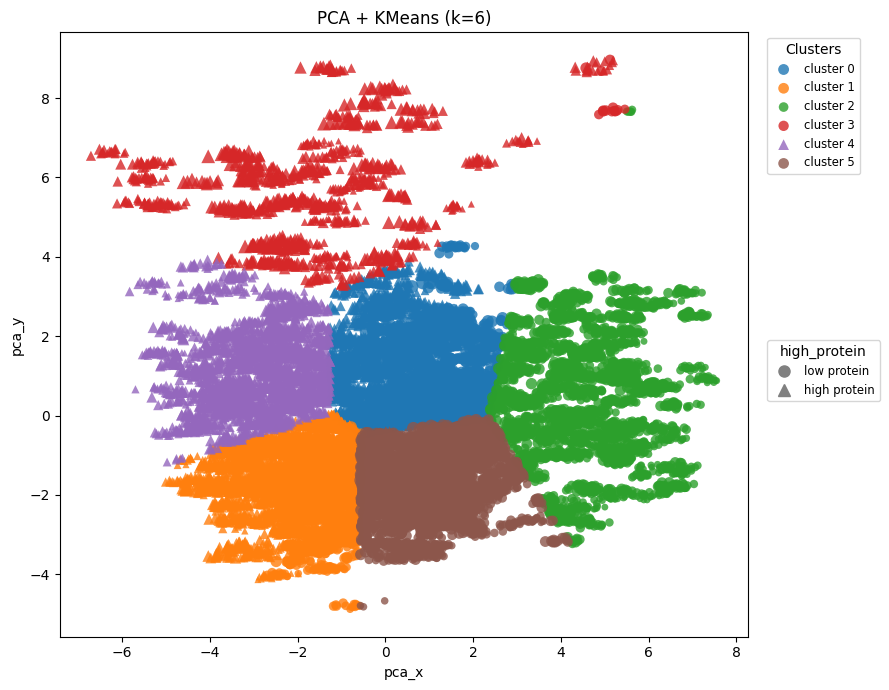

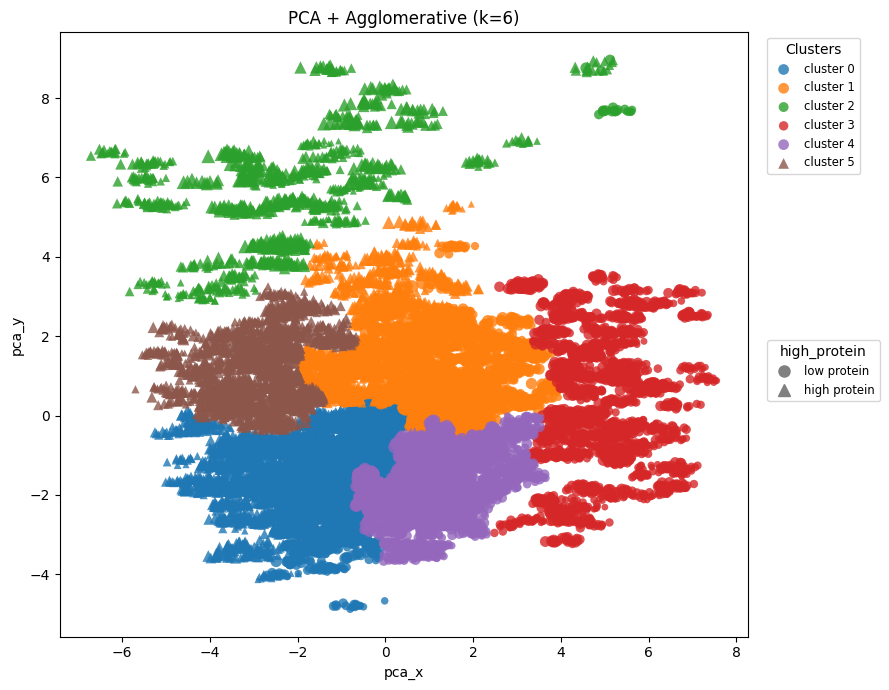

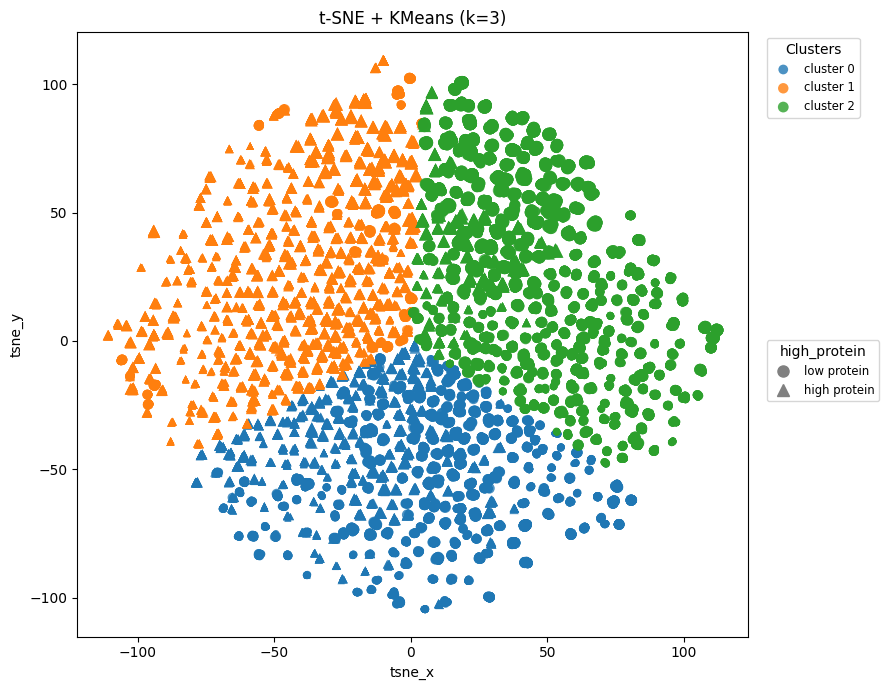

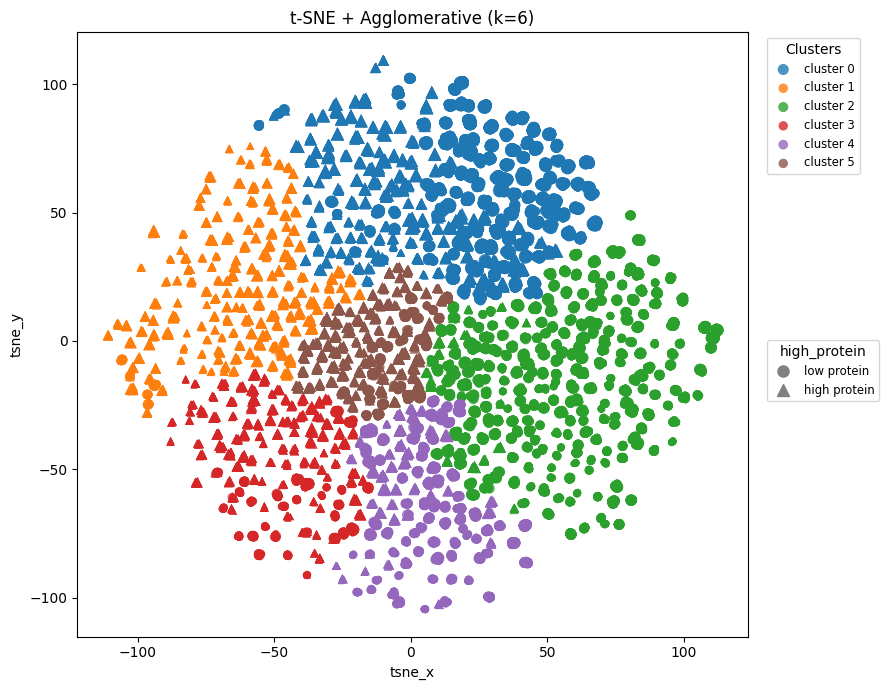

In [28]:
# ---------- detect columns for size (calories) and shape (protein_per_kg) ----------

# try to find a calories-like column
cal_col = None
for cand in df_proc.columns:
    if "calories" in cand.lower():
        cal_col = cand
        break

print("Using calories column for size encoding:", cal_col)

# try to find a protein_per_kg-like column
prot_col = None
for cand in df_proc.columns:
    if "protein_per_kg" in cand.lower():
        prot_col = cand
        break

print("Using protein_per_kg column for shape encoding:", prot_col)

# derive high/low protein flag for SHAPE encoding
if prot_col is not None:
    prot = df_proc[prot_col].astype(float)
    prot = prot.replace([np.inf, -np.inf], np.nan)
    thr = prot.median()
    df_proc["high_protein"] = prot >= thr
else:
    df_proc["high_protein"] = False  # single category fallback


def scatter_clusters_multi(
    df,
    x,
    y,
    cluster_col,
    title=None,
    size_by=None,          # will default to detected cal_col
    shape_by="high_protein"
):
    """
    x, y      -> PCA or t-SNE coordinates
    color     -> cluster label
    size      -> size_by (continuous, e.g. calories)
    shape     -> high_protein (True/False)
    """
    fig, ax = plt.subplots(figsize=(9, 7))

    # --- size encoding ---
    if size_by is not None and size_by in df.columns:
        sizes_raw = df[size_by].astype(float)
        sizes_raw = sizes_raw.replace([np.inf, -np.inf], np.nan)
        sizes_raw = sizes_raw.fillna(sizes_raw.median())
        s_norm = (sizes_raw - sizes_raw.min()) / (sizes_raw.max() - sizes_raw.min() + 1e-9)
        sizes = 20 + 80 * s_norm   # marker size in [20, 100]
    else:
        sizes = np.full(len(df), 40.0)

    # --- color = cluster label ---
    labels = df[cluster_col]
    uniq_clusters = sorted(labels.dropna().unique())
    palette = sns.color_palette("tab10", n_colors=max(2, min(10, len(uniq_clusters))))

    # --- shape = high/low protein (2 shapes max) ---
    if shape_by is not None and shape_by in df.columns:
        shape_vals = df[shape_by].astype(bool)
        uniq_shapes = [False, True] if shape_vals.any() else [False]
    else:
        shape_vals = pd.Series(False, index=df.index)
        uniq_shapes = [False]

    marker_map = {
        False: "o",  # lower protein
        True: "^",   # higher protein
    }

    cluster_labeled = set()

    for ci, cl in enumerate(uniq_clusters):
        for cat in uniq_shapes:
            sel = (labels == cl) & (shape_vals == cat)
            if not sel.any():
                continue

            # label each cluster only once for color legend
            lbl = f"cluster {cl}" if cl not in cluster_labeled else None
            if lbl is not None:
                cluster_labeled.add(cl)

            ax.scatter(
                df.loc[sel, x],
                df.loc[sel, y],
                s=sizes[sel],
                alpha=0.8,
                edgecolors="none",
                color=palette[ci % len(palette)],
                marker=marker_map[cat],
                label=lbl
            )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    if title:
        ax.set_title(title)

    # legend 1: clusters (colors)
    handles1, labels1 = ax.get_legend_handles_labels()
    if handles1:
        leg1 = ax.legend(handles1, labels1, title="Clusters",
                         bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
        ax.add_artist(leg1)

    # legend 2: high/low protein (shapes) – only if we actually have both
    if len(uniq_shapes) > 1:
        shape_labels = []
        shape_handles = []
        for cat in uniq_shapes:
            name = "high protein" if cat else "low protein"
            shape_labels.append(name)
            shape_handles.append(
                Line2D([0], [0],
                       marker=marker_map[cat],
                       color="gray",
                       linestyle="",
                       markersize=8,
                       label=name)
            )

        ax.legend(shape_handles, shape_labels,
                  title=shape_by,
                  bbox_to_anchor=(1.02, 0.5),
                  loc="upper left",
                  fontsize="small")

    plt.tight_layout()
    plt.show()

# ---------- run for ALL 4 clusterings ----------

plots = [
    ("pca_x",  "pca_y",  "kmeans_pca", "PCA + KMeans (k=6)"),
    ("pca_x",  "pca_y",  "agglo_pca",  "PCA + Agglomerative (k=6)"),
    ("tsne_x", "tsne_y", "kmeans_tsne", "t-SNE + KMeans (k=3)"),
    ("tsne_x", "tsne_y", "agglo_tsne",  "t-SNE + Agglomerative (k=6)"),
]

for xcol, ycol, clabel, name in plots:
    required = [xcol, ycol, clabel]
    if all(c in df_proc.columns for c in required):
        scatter_clusters_multi(
            df_proc,
            x=xcol,
            y=ycol,
            cluster_col=clabel,
            title=name,
            size_by=cal_col,         # <-- use the detected calories column
            shape_by="high_protein"  # <-- high vs low protein, if available
        )
    else:
        print(f"Skipping {name}: required columns not found.")


### Feature importance for the clusterings

To understand which variables drive the clusters, we ran an ANOVA F-test for each clustering solution. Across all four variants (K-Means/Agglo on PCA and t-SNE), the **same core features** consistently show the highest F-values:

- **Body size and composition:** `Weight`, `lean_mass_kg`, `BMI`, `BMI_calc`, `Fat_Percentage`  
- **Energy intake and macros:** `Calories`, `cal_from_macros`, `Carbs`, `Fats`, `Proteins`, `protein_per_kg`  
- **Training load / session characteristics (mainly in t-SNE space):** `Experience_Level`, `expected_burn`, `cal_balance`, `Session_Duration (hours)`

This means that the clusters are primarily separated by **overall body mass and body composition**, **total energy and macro intake**, and, to a lesser extent, by **training experience and workload**, rather than by more minor or categorical attributes.

In [29]:
# 1) numeric features from your FEATURES
numeric_feats = df_proc[FEATURES].select_dtypes(include=[np.number]).columns.tolist()
X_num = df_proc[numeric_feats].astype(float)

# clean infinities and NaNs
X_num = X_num.replace([np.inf, -np.inf], np.nan)
X_num_imputed = X_num.fillna(X_num.median())   # median per column

# which clusterings do we have?
cluster_cols = [
    c for c in ["kmeans_pca", "agglo_pca", "kmeans_tsne", "agglo_tsne"]
    if c in df_proc.columns
]

for cluster_col in cluster_cols:
    print(f"\n=== Feature importance (ANOVA F-test) for clustering: {cluster_col} ===")

    y = df_proc[cluster_col].values

    # drop rows with missing labels (just in case)
    mask = ~pd.isna(y)
    X_sub = X_num_imputed.loc[mask]
    y_sub = y[mask]

    # need at least 2 clusters
    if len(np.unique(y_sub)) < 2:
        print(f"Not enough distinct clusters in {cluster_col}.")
        continue

    # ANOVA F-test: higher F => stronger separation between clusters
    f_vals, p_vals = f_classif(X_sub, y_sub)

    imp_df = pd.DataFrame({
        "feature": numeric_feats,
        "F_value": f_vals,
        "p_value": p_vals
    }).sort_values("F_value", ascending=False)

    # show top 10 most important features
    print(imp_df.head(10).to_string(index=False))



=== Feature importance (ANOVA F-test) for clustering: kmeans_pca ===
        feature      F_value  p_value
    Weight (kg) 16354.279449      0.0
       Calories 13297.717719      0.0
   lean_mass_kg 11225.288520      0.0
cal_from_macros 11128.176131      0.0
          Carbs 11120.322266      0.0
           Fats 11117.898496      0.0
       Proteins 11111.423419      0.0
 protein_per_kg 10909.362148      0.0
            BMI  7380.409742      0.0
       BMI_calc  7380.376100      0.0

=== Feature importance (ANOVA F-test) for clustering: agglo_pca ===
        feature      F_value  p_value
    Weight (kg) 12962.741302      0.0
cal_from_macros 10645.240556      0.0
          Carbs 10638.814283      0.0
           Fats 10634.025317      0.0
       Proteins 10630.155296      0.0
       Calories 10629.169934      0.0
 protein_per_kg  9803.542487      0.0
   lean_mass_kg  9604.739016      0.0
            BMI  6081.280204      0.0
       BMI_calc  6081.161318      0.0

=== Feature importance (

In [31]:
# numeric features
numeric_feats = df_proc[FEATURES].select_dtypes(include=[np.number]).columns.tolist()
X_num = df_proc[numeric_feats].astype(float)
X_num = X_num.replace([np.inf, -np.inf], np.nan)
X_num_imputed = X_num.fillna(X_num.median())

cluster_cols = [
    c for c in ["kmeans_pca", "agglo_pca", "kmeans_tsne", "agglo_tsne"]
    if c in df_proc.columns
]

all_scores = []

for cluster_col in cluster_cols:
    y = df_proc[cluster_col].values
    mask = ~pd.isna(y)
    X_sub = X_num_imputed.loc[mask]
    y_sub = y[mask]

    if len(np.unique(y_sub)) < 2:
        continue

    f_vals, p_vals = f_classif(X_sub, y_sub)

    tmp = pd.DataFrame({
        "feature": numeric_feats,
        "cluster": cluster_col,
        "F_value": f_vals
    })
    all_scores.append(tmp)

all_scores = pd.concat(all_scores, ignore_index=True)

# aggregate: mean F-value across clusterings
agg_scores = (
    all_scores
    .groupby("feature")["F_value"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n=== Global feature ranking across all clusterings (mean F-value) ===")
print(agg_scores.head(15).to_string(index=False))




=== Global feature ranking across all clusterings (mean F-value) ===
          feature     F_value
      Weight (kg) 9718.513909
   protein_per_kg 8857.376087
         Calories 8289.439788
  cal_from_macros 7405.150954
            Carbs 7400.695549
             Fats 7399.526169
         Proteins 7395.969163
     lean_mass_kg 7386.963974
              BMI 5022.766198
         BMI_calc 5022.709418
   Fat_Percentage 3749.685958
Physical exercise 3190.141079
      cal_balance 3111.379290
 Experience_Level 1501.373764
    expected_burn 1302.361627


### Global feature importance across all clusterings

To get an overall picture, we averaged the ANOVA F-values for each feature across all four clustering variants (K-Means/Agglo on PCA and t-SNE). The global ranking confirms the earlier pattern:

- **Most influential features:**  
  Weight (kg), Calories, lean_mass_kg, protein_per_kg, BMI, BMI_calc  
- **Nutritional composition:**  
  cal_from_macros, Carbs, Fats, Proteins, Fat_Percentage  
- **Training-related variables:**  
  cal_balance, Physical exercise, Experience_Level, expected_burn

This shows that, independent of the exact clustering method or projection, the cluster structure is dominated by **body mass/composition**, **overall caloric and macro intake**, and **training volume/intensity**.


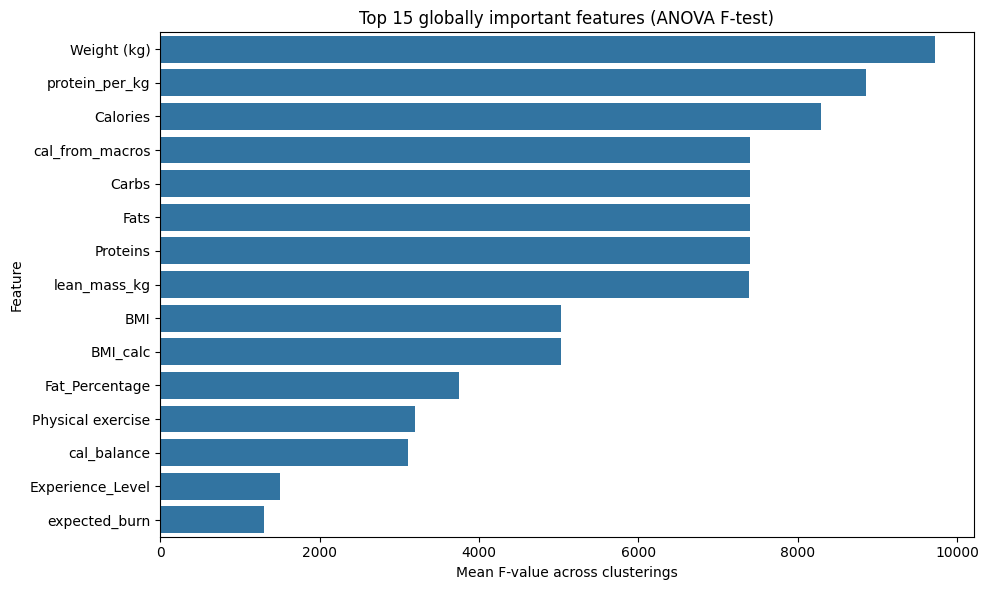

In [32]:
# take top 15 features
topN = 15
top_agg = agg_scores.head(topN)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_agg,
    x="F_value",
    y="feature",
    orient="h"
)
plt.xlabel("Mean F-value across clusterings")
plt.ylabel("Feature")
plt.title(f"Top {topN} globally important features (ANOVA F-test)")
plt.tight_layout()
plt.show()


In [33]:
def cluster_feature_summary(df, features, cluster_col, cluster_id, top_k=5):
    """
    For a single cluster (cluster_id in cluster_col), compute which features
    differ most from the global distribution (effect size).
    Returns a small DataFrame with top_k features.
    """
    # numeric-only + clean NaNs/inf
    X = df[features].astype(float)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())

    mask = (df[cluster_col] == cluster_id)
    X_cluster = X[mask]

    # global vs cluster means/std
    global_mean = X.mean()
    global_std  = X.std().replace(0, np.nan)
    cluster_mean = X_cluster.mean()

    # standardized difference (effect size)
    effect = (cluster_mean - global_mean) / global_std
    effect = effect.replace([np.inf, -np.inf], np.nan)

    # rank by |effect|
    effect_abs = effect.abs().sort_values(ascending=False)
    top_feats = effect_abs.head(top_k).index

    summary = pd.DataFrame({
        "feature": top_feats,
        "effect_size": effect.loc[top_feats],
        "cluster_mean": cluster_mean.loc[top_feats],
        "global_mean": global_mean.loc[top_feats]
    }).reset_index(drop=True)

    return summary


def label_cluster_from_summary(summary_df):
    """
    Turn top features and effect sizes into a simple text label.
    """
    parts = []
    for _, row in summary_df.iterrows():
        feat = row["feature"]
        eff  = row["effect_size"]

        if eff > 1.0:
            qualifier = "high"
        elif eff > 0.5:
            qualifier = "slightly high"
        elif eff < -1.0:
            qualifier = "low"
        elif eff < -0.5:
            qualifier = "slightly low"
        else:
            continue

        parts.append(f"{qualifier} {feat}")

    if not parts:
        return "no strong deviations from global distribution"

    return ", ".join(parts)

def plot_cluster_feature_distributions(df, cluster_col, cluster_id, features):
    """
    For each feature in `features`, plot:
      - overall vs cluster KDE
      - boxplot by cluster_col
    """
    mask = (df[cluster_col] == cluster_id)
    df_cluster = df[mask]

    for feat in features:
        # KDE: cluster vs overall
        plt.figure(figsize=(8, 4))
        sns.kdeplot(df[feat], label="overall", common_norm=False)
        sns.kdeplot(df_cluster[feat], label=f"cluster {cluster_id}", common_norm=False)
        plt.title(f"Distribution of {feat}: cluster {cluster_id} vs overall")

        ax = plt.gca()
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(fontsize="small")

        plt.tight_layout()
        plt.show()

        # boxplot: all clusters
        plt.figure(figsize=(8, 4))
        sns.boxplot(x=cluster_col, y=feat, data=df, showfliers=False)
        plt.title(f"{feat} by {cluster_col} (cluster {cluster_id} highlighted)")

        # no legend needed here; categories are on x-axis
        plt.tight_layout()
        plt.show()



def cluster_density_and_outliers(df, cluster_col, cluster_id, x_col="pca_x", y_col="pca_y", z_thresh=3.0):
    """
    Compute simple density stats and outliers in 2D projection (e.g. PCA).
    """
    mask = (df[cluster_col] == cluster_id)
    df_c = df[mask][[x_col, y_col]].dropna()

    n = len(df_c)
    if n == 0:
        print(f"Cluster {cluster_id}: no points.")
        return

    center = df_c.mean()
    dists = np.linalg.norm(df_c - center.values, axis=1)
    mean_dist = dists.mean()
    std_dist  = dists.std()

    print(f"Cluster {cluster_id}: n={n}, mean distance to center={mean_dist:.3f}, std={std_dist:.3f}")

    # outliers: points far from cluster center
    if std_dist > 0:
        z_scores = (dists - mean_dist) / std_dist
        outlier_mask = z_scores > z_thresh
        n_out = outlier_mask.sum()
        print(f"  Outliers (dist > {z_thresh} std): {n_out} points")

        # store an outlier flag if you want
        df.loc[mask, f"{cluster_col}_outlier"] = False
        df.loc[df_c.index[outlier_mask], f"{cluster_col}_outlier"] = True

def analyze_top_k_clusters(
    df,
    features,
    cluster_col,
    top_clusters=5,
    top_feats_per_cluster=5,
    x_col="pca_x",   # <- new: which projection to use
    y_col="pca_y"
):
    """
    For the top `top_clusters` (by size) in `cluster_col`, print:
      - size & fraction
      - top driving features (with effect sizes)
      - suggested label
      - plots of distributions for those features
      - density & outliers in a 2D projection (x_col, y_col)
    """
    sizes = df[cluster_col].value_counts().head(top_clusters)

    print(f"\n=== Analyzing top {len(sizes)} clusters of '{cluster_col}' ===")
    for cid, cnt in sizes.items():
        frac = cnt / len(df)
        print(f"\n--- Cluster {cid} ({cnt} points, {frac:.1%} of data) ---")

        # 1) main features that drive this cluster
        summary = cluster_feature_summary(df, features, cluster_col, cid,
                                          top_k=top_feats_per_cluster)
        print("\nTop driving features (effect size, cluster_mean, global_mean):")
        print(summary.to_string(index=False))

        # 2) human-readable label
        label = label_cluster_from_summary(summary)
        print("\nSuggested label:", label)

        # 3) distributions of those features
        plot_cluster_feature_distributions(df, cluster_col, cid,
                                           summary["feature"].tolist())

        # 4) density & outliers in chosen projection
        cluster_density_and_outliers(df, cluster_col, cid,
                                     x_col=x_col, y_col=y_col)


=== Analyzing top 6 clusters of 'kmeans_pca' ===

--- Cluster 1 (4765 points, 23.8% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
       feature  effect_size  cluster_mean  global_mean
      Calories    -0.887527   1543.475131  2024.418300
   Weight (kg)    -0.881491     55.235005    73.898832
  lean_mass_kg    -0.871030     42.899611    53.786384
Fat_Percentage    -0.792632     22.141197    26.101313
      BMI_calc    -0.792043     19.614055    24.921651

Suggested label: slightly low Calories, slightly low Weight (kg), slightly low lean_mass_kg, slightly low Fat_Percentage, slightly low BMI_calc


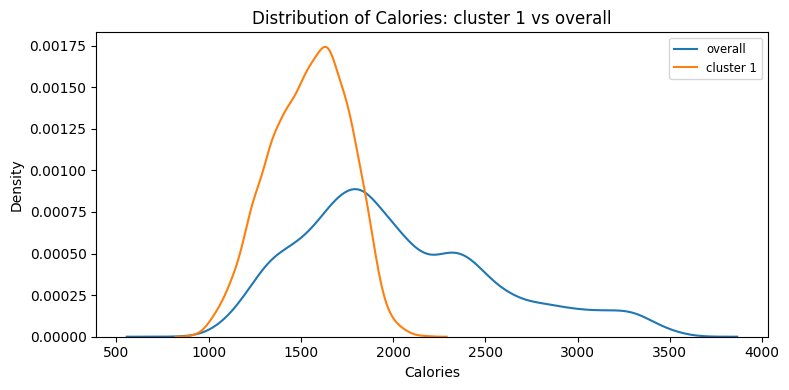

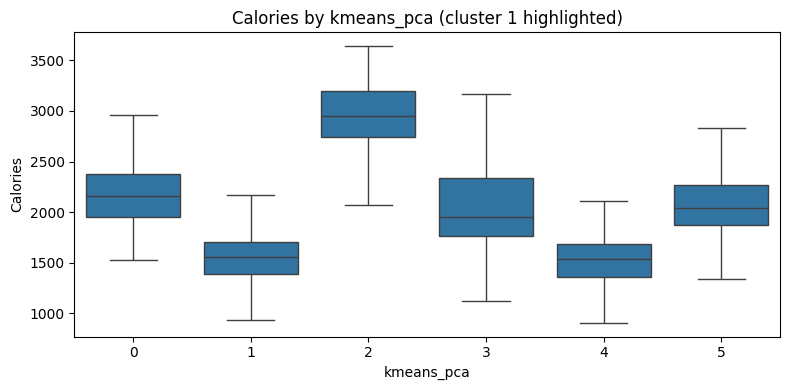

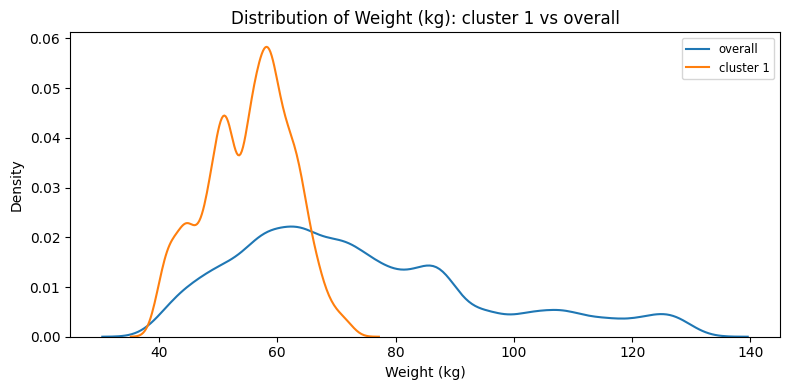

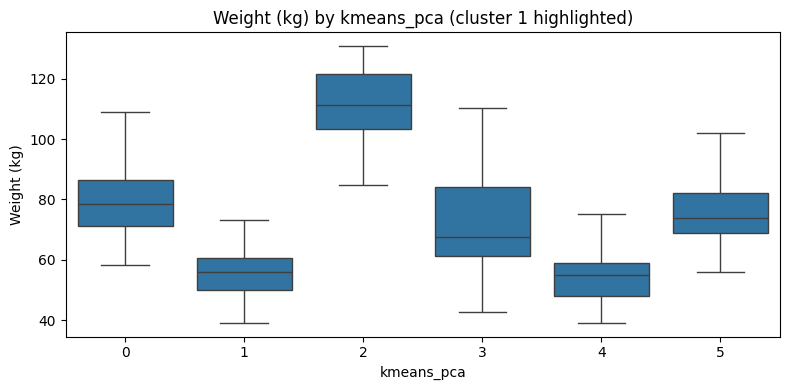

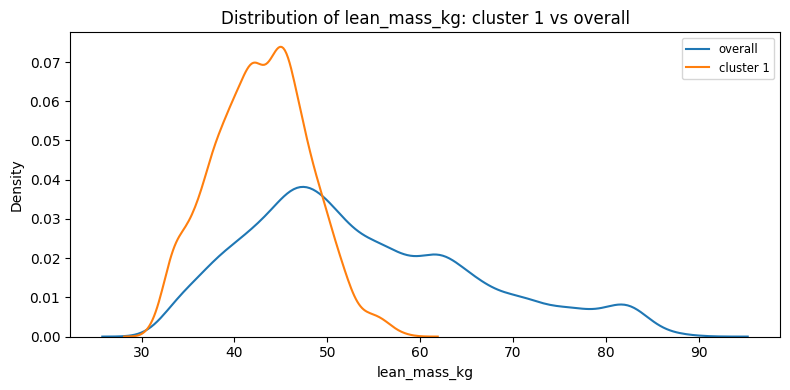

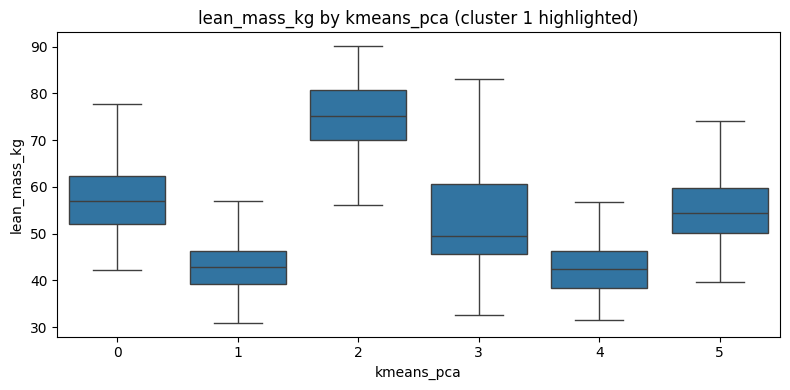

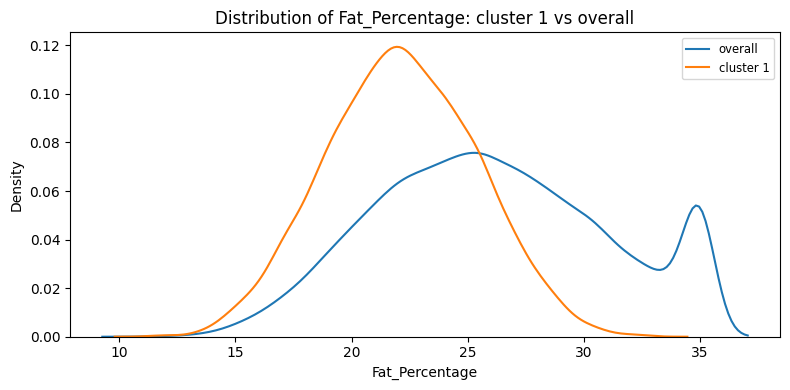

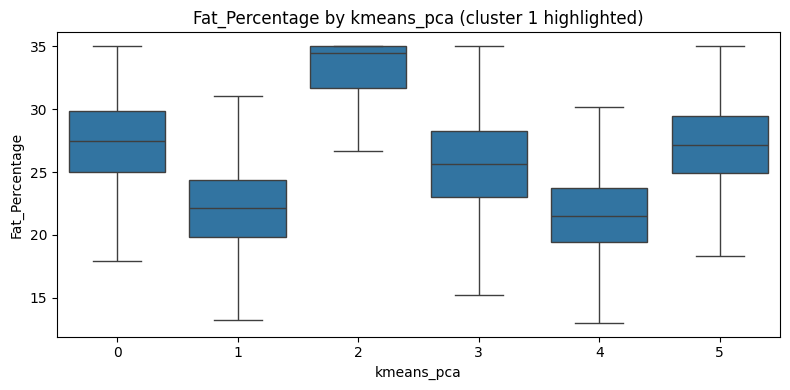

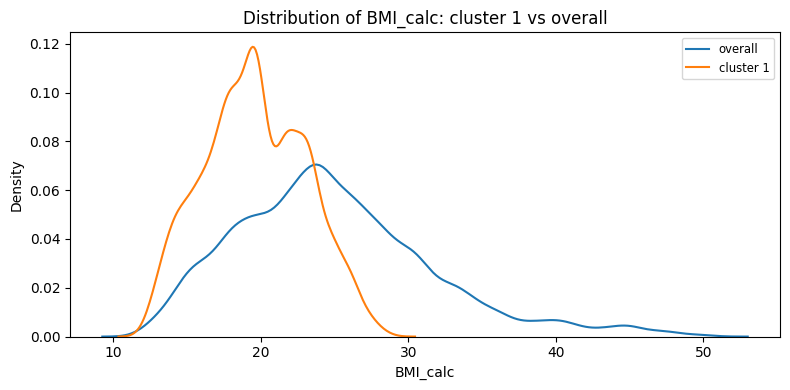

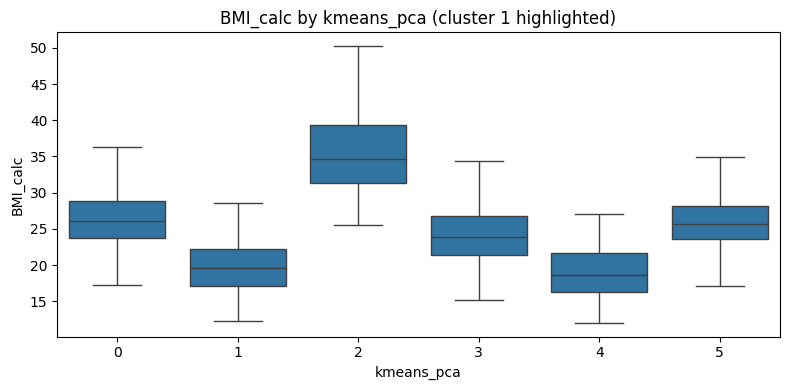

Cluster 1: n=4765, mean distance to center=1.184, std=0.540
  Outliers (dist > 3.0 std): 21 points

--- Cluster 5 (4205 points, 21.0% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
       Proteins    -0.881510     80.486578    99.918290
cal_from_macros    -0.881387   1609.738949  1998.297076
           Fats    -0.881380     53.656514    66.612172
          Carbs    -0.881125    201.221004   249.778592
 protein_per_kg    -0.734520      1.078966     1.460142

Suggested label: slightly low Proteins, slightly low cal_from_macros, slightly low Fats, slightly low Carbs, slightly low protein_per_kg


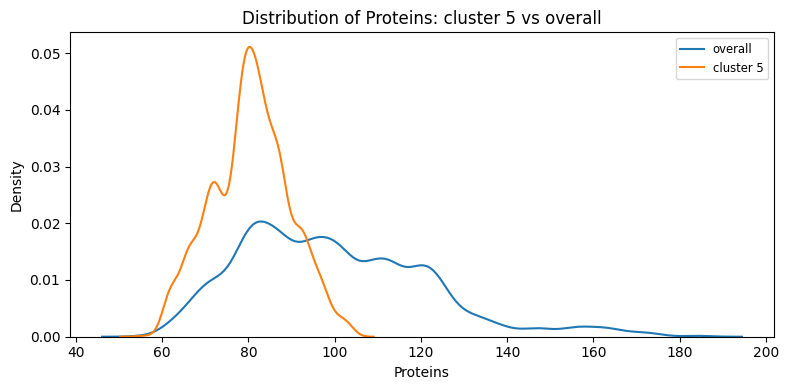

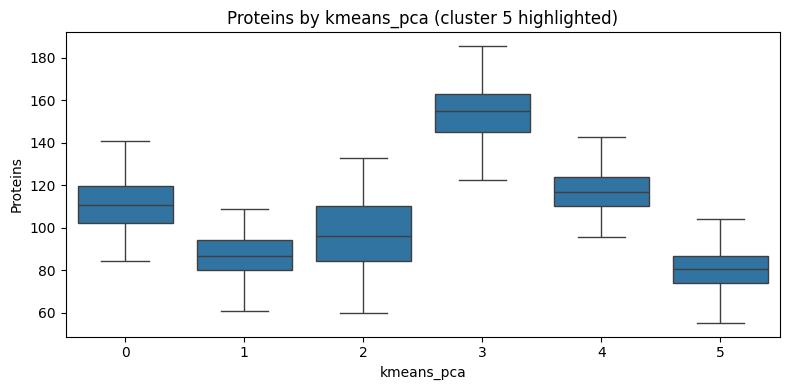

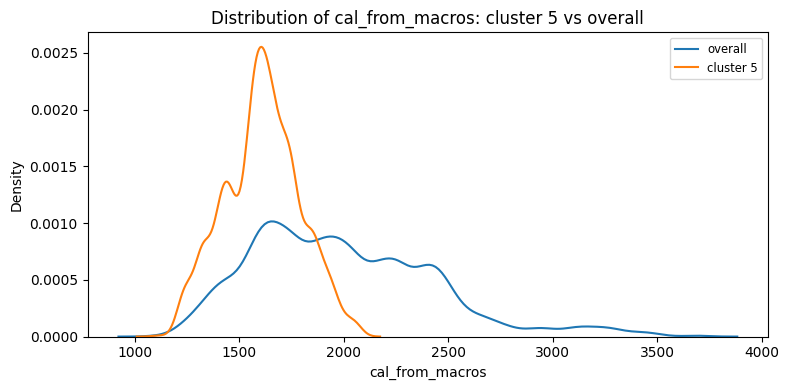

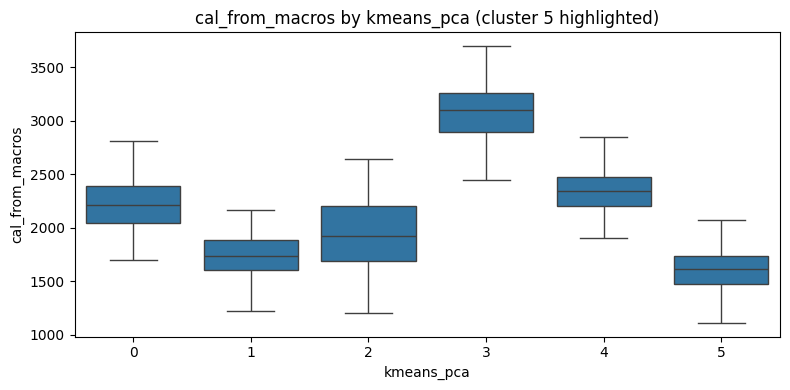

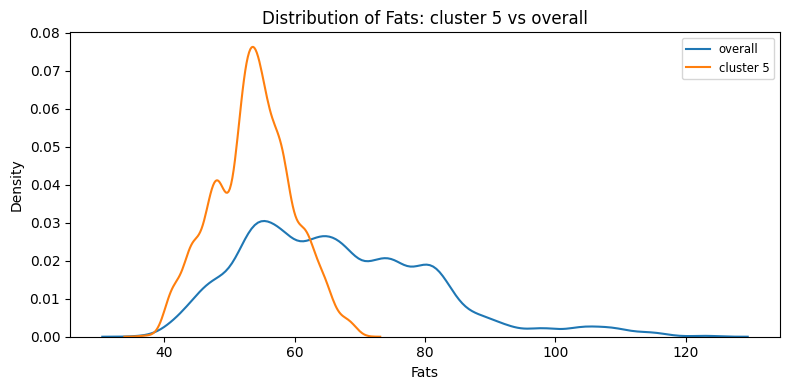

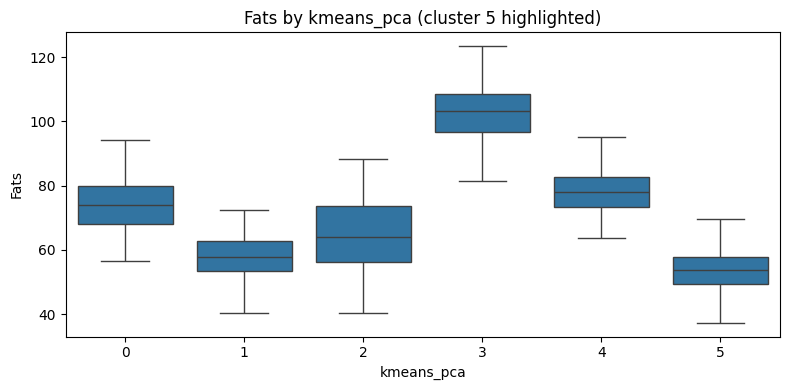

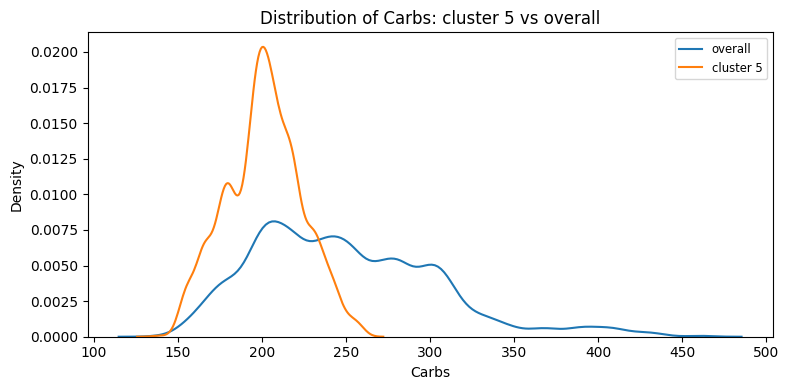

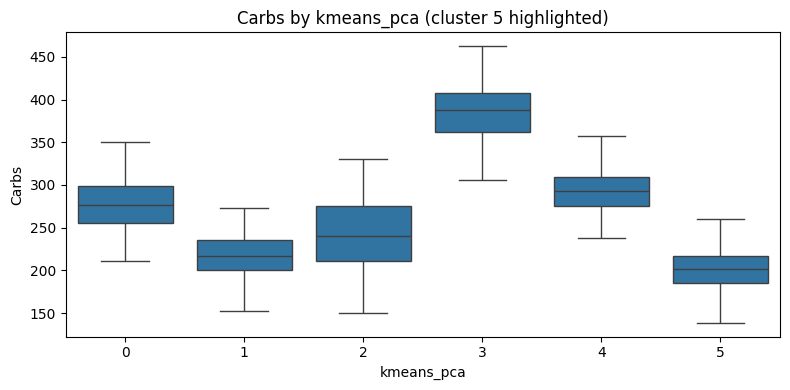

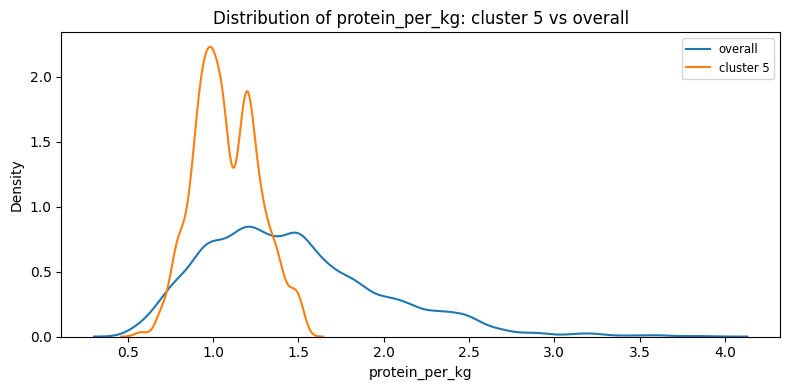

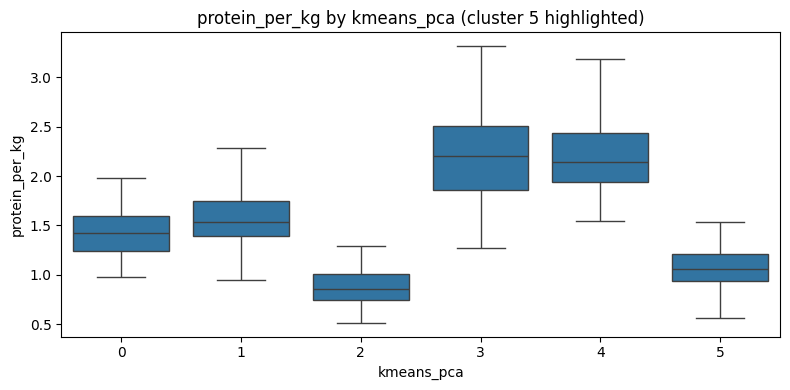

Cluster 5: n=4205, mean distance to center=1.141, std=0.506
  Outliers (dist > 3.0 std): 35 points

--- Cluster 0 (4194 points, 21.0% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
          Carbs     0.505768    277.650789   249.778592
cal_from_macros     0.505557   2221.170992  1998.297076
           Fats     0.505336     74.040243    66.612172
       Proteins     0.505048    111.051412    99.918290
   lean_mass_kg     0.281153     57.300446    53.786384

Suggested label: slightly high Carbs, slightly high cal_from_macros, slightly high Fats, slightly high Proteins


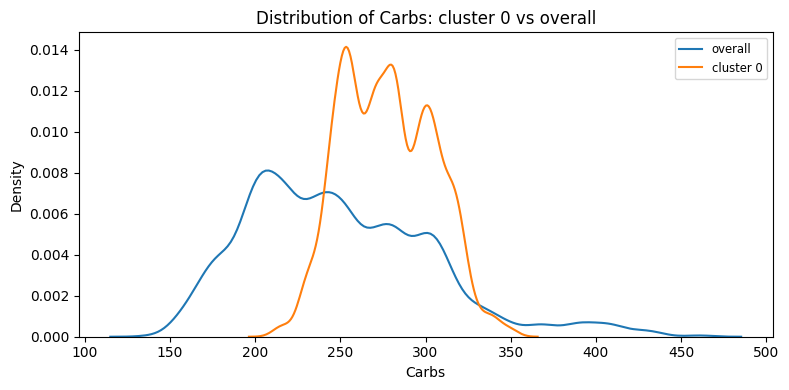

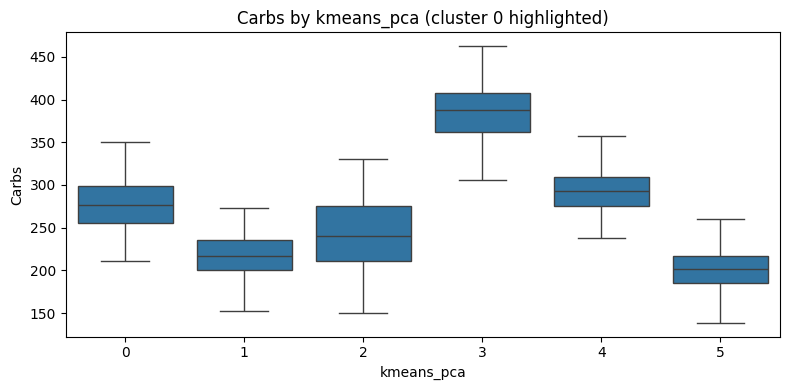

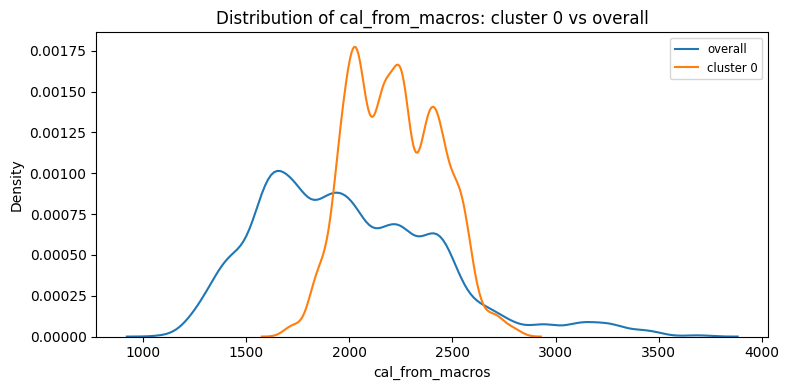

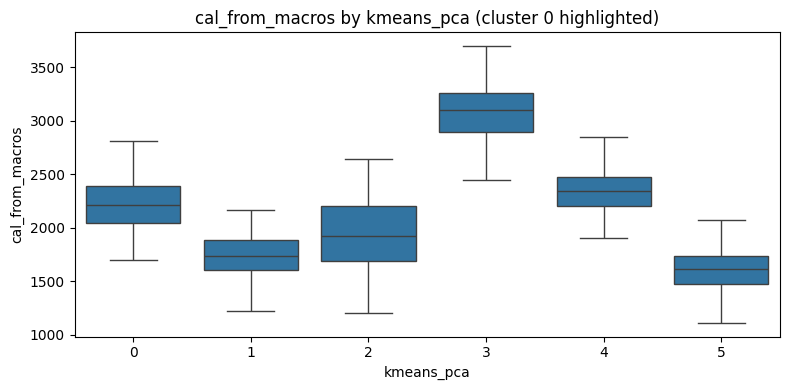

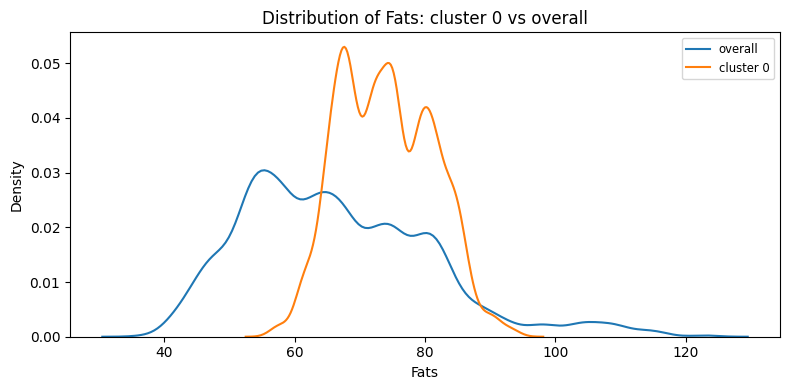

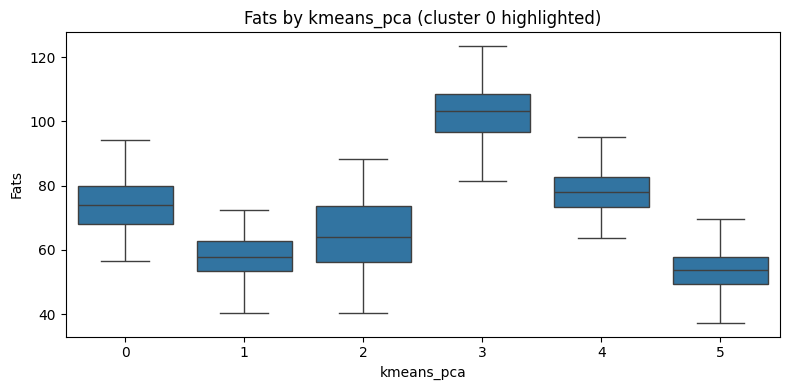

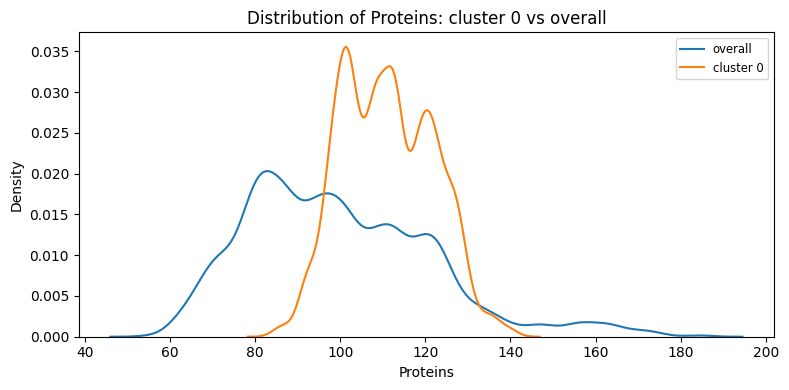

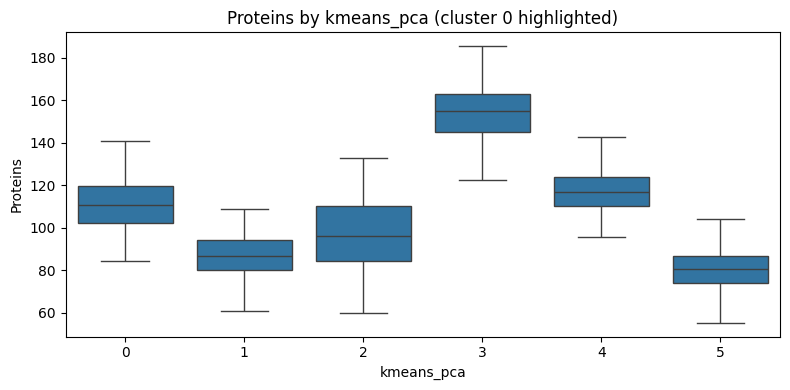

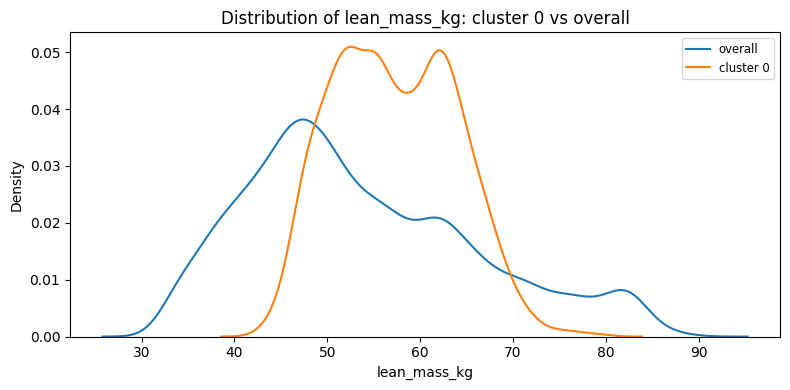

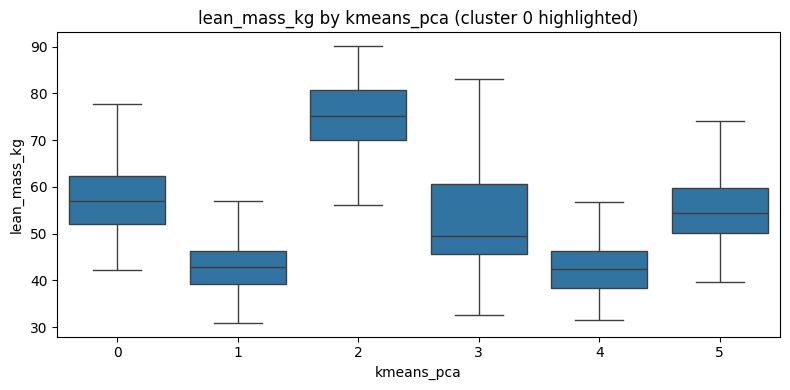

Cluster 0: n=4194, mean distance to center=1.298, std=0.527
  Outliers (dist > 3.0 std): 32 points

--- Cluster 2 (3007 points, 15.0% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
     feature  effect_size  cluster_mean  global_mean
 Weight (kg)     1.800332    112.017283    73.898832
    Calories     1.731097   2962.484869  2024.418300
lean_mass_kg     1.681034     74.797195    53.786384
    BMI_calc     1.593994     35.603236    24.921651
         BMI     1.593991     35.603213    24.921680

Suggested label: high Weight (kg), high Calories, high lean_mass_kg, high BMI_calc, high BMI


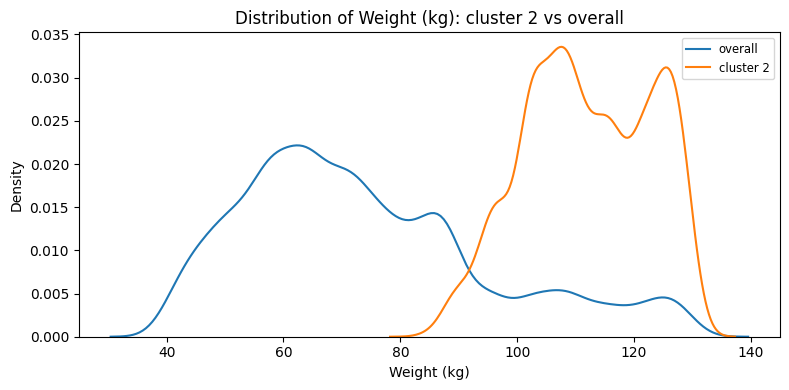

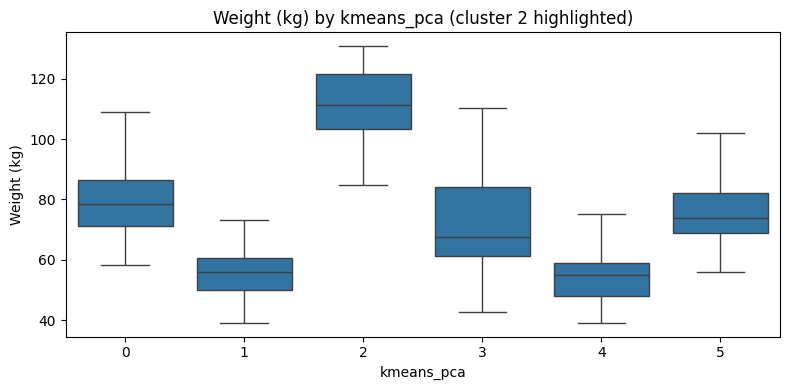

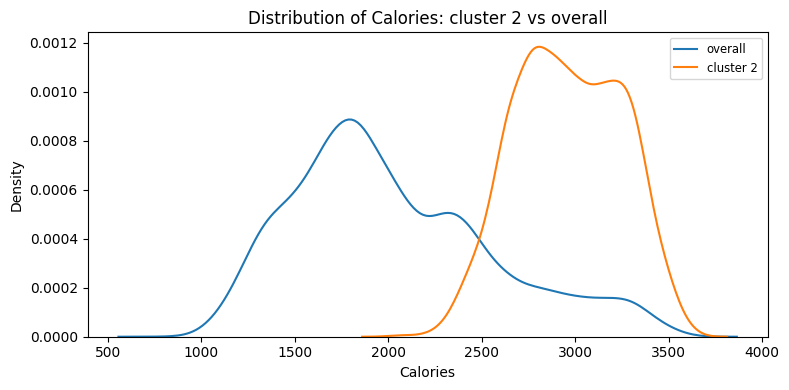

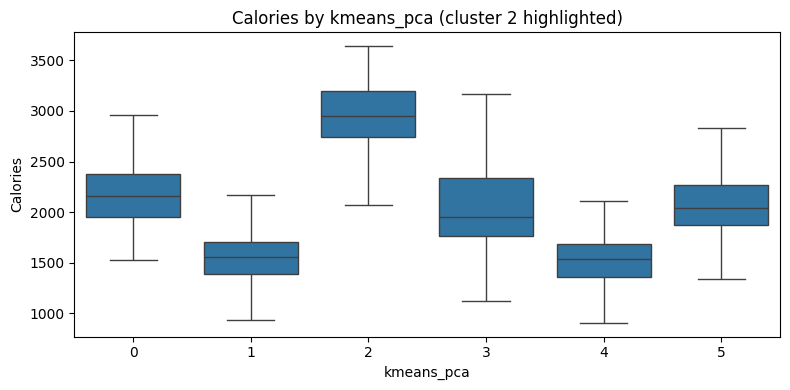

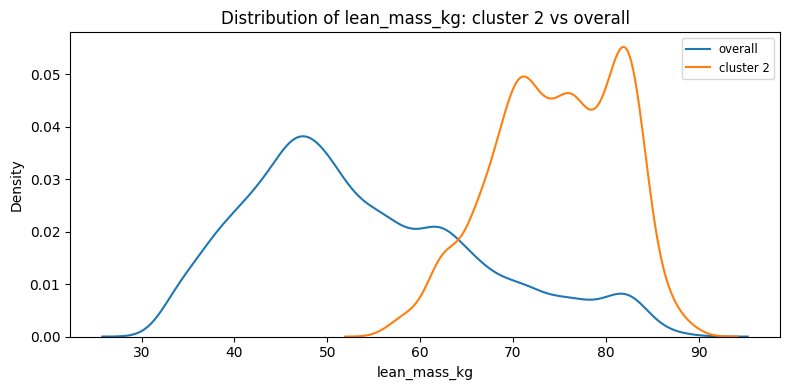

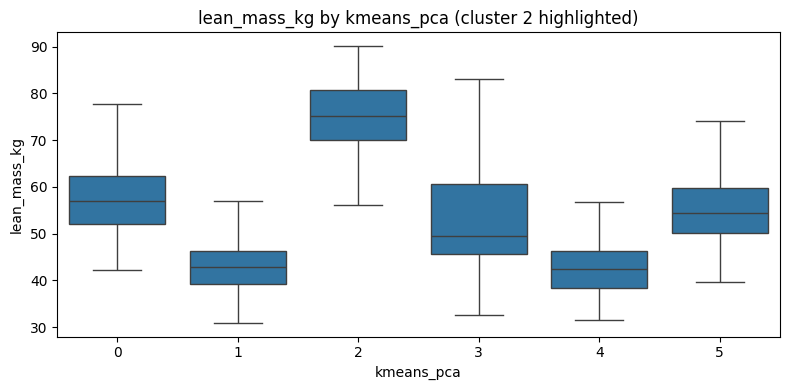

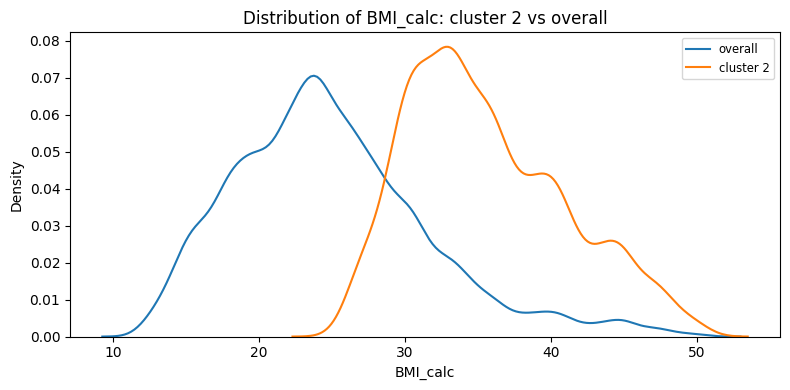

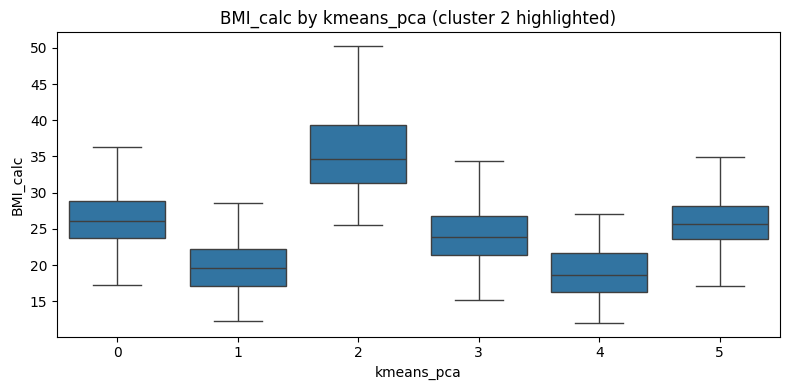

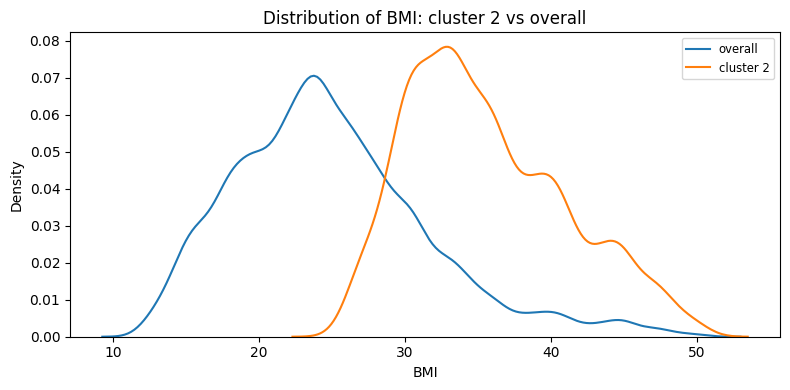

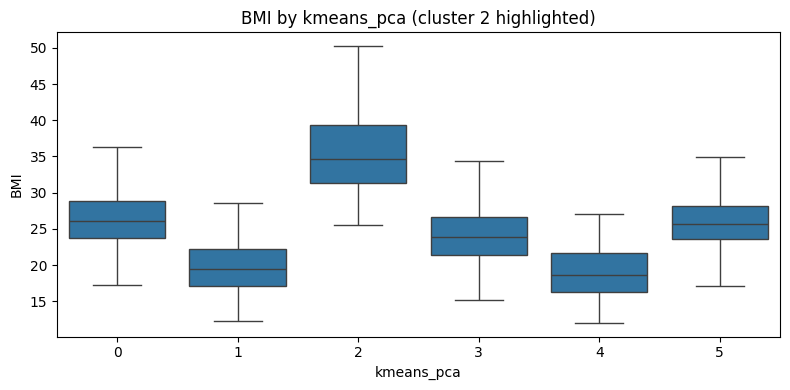

Cluster 2: n=3007, mean distance to center=1.778, std=0.796
  Outliers (dist > 3.0 std): 5 points

--- Cluster 4 (2679 points, 13.4% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
       feature  effect_size  cluster_mean  global_mean
protein_per_kg     1.445643      2.210352     1.460142
   Weight (kg)    -0.932821     54.148205    73.898832
      Calories    -0.925612   1522.837253  2024.418300
  lean_mass_kg    -0.916168     42.335436    53.786384
Fat_Percentage    -0.899082     21.609355    26.101313

Suggested label: high protein_per_kg, slightly low Weight (kg), slightly low Calories, slightly low lean_mass_kg, slightly low Fat_Percentage


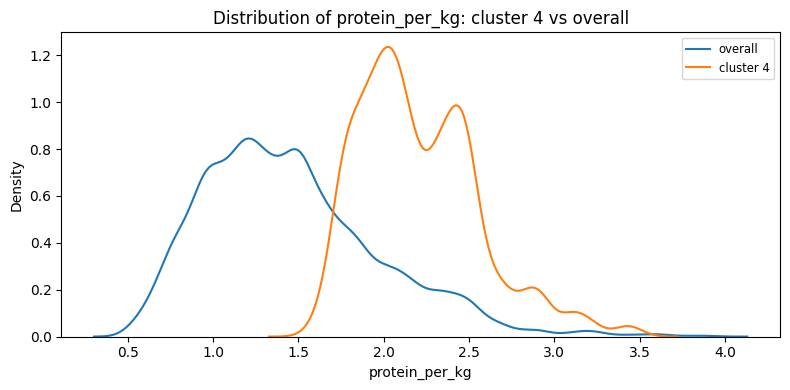

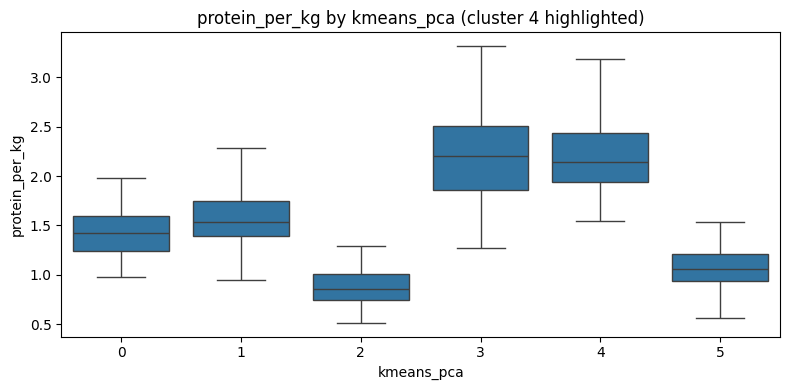

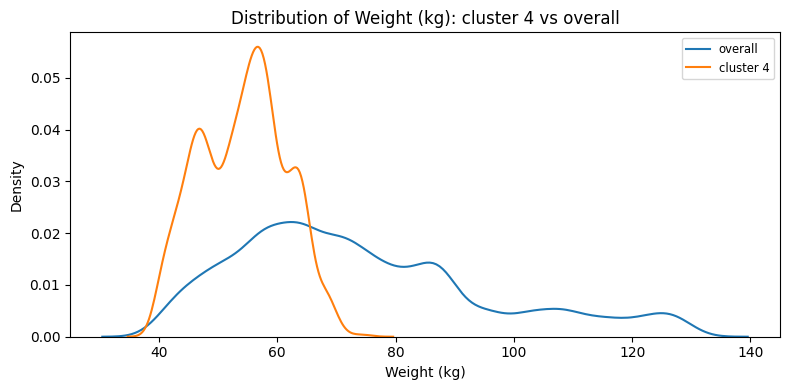

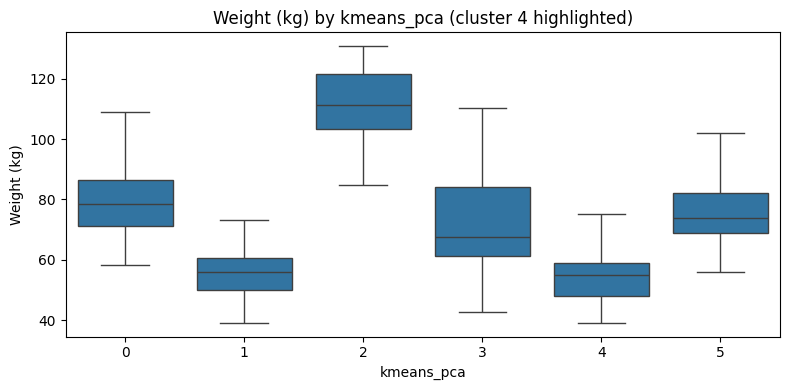

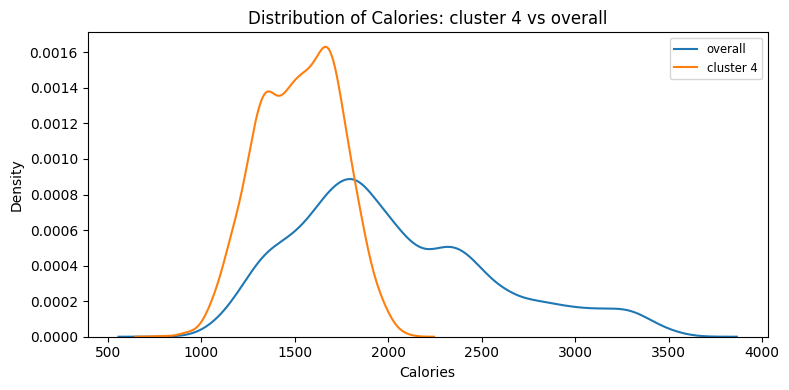

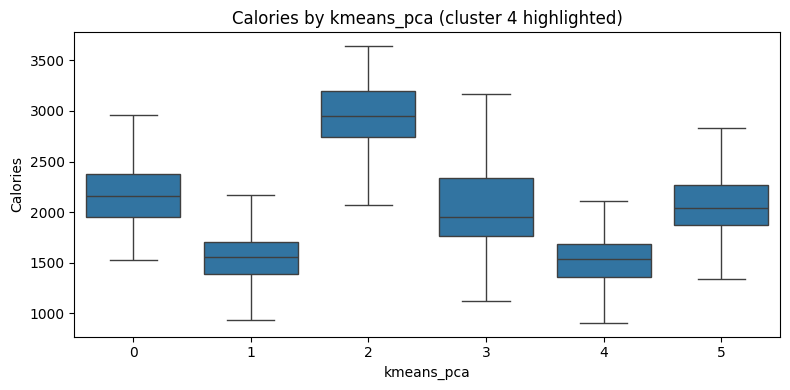

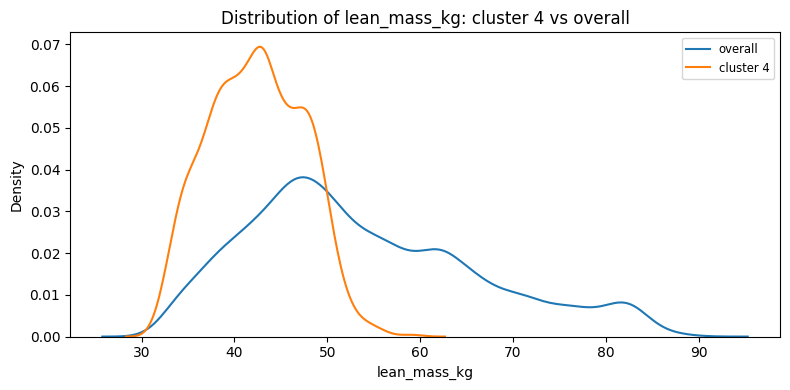

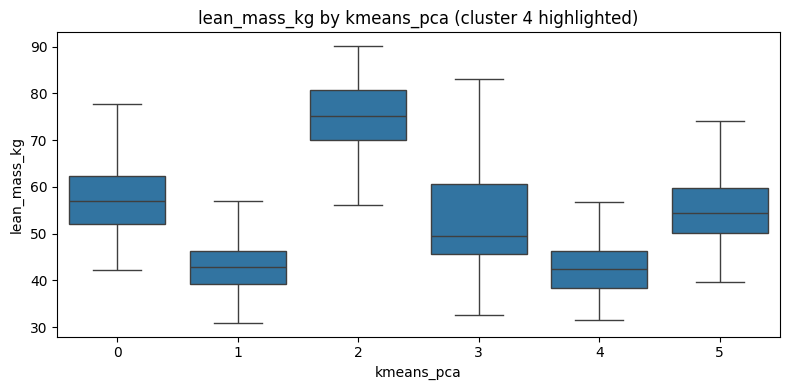

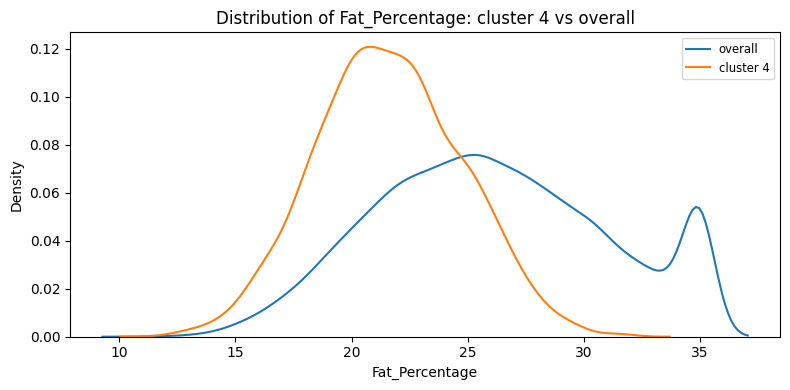

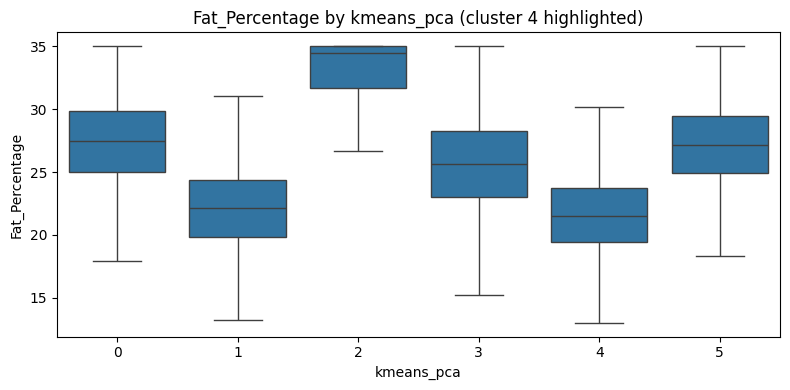

Cluster 4: n=2679, mean distance to center=1.299, std=0.583
  Outliers (dist > 3.0 std): 26 points

--- Cluster 3 (1150 points, 5.8% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
          feature  effect_size  cluster_mean  global_mean
Physical exercise     2.958230      3.371174     0.452503
  cal_from_macros     2.430271   3069.678200  1998.297076
            Carbs     2.430210    383.704113   249.778592
         Proteins     2.429875    153.481643    99.918290
             Fats     2.429639    102.326130    66.612172

Suggested label: high Physical exercise, high cal_from_macros, high Carbs, high Proteins, high Fats


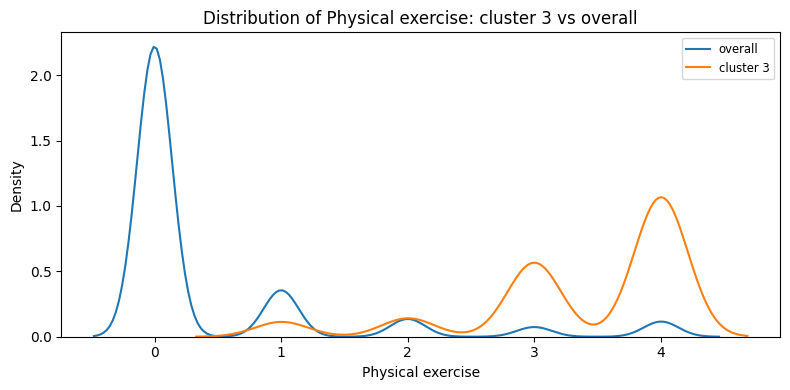

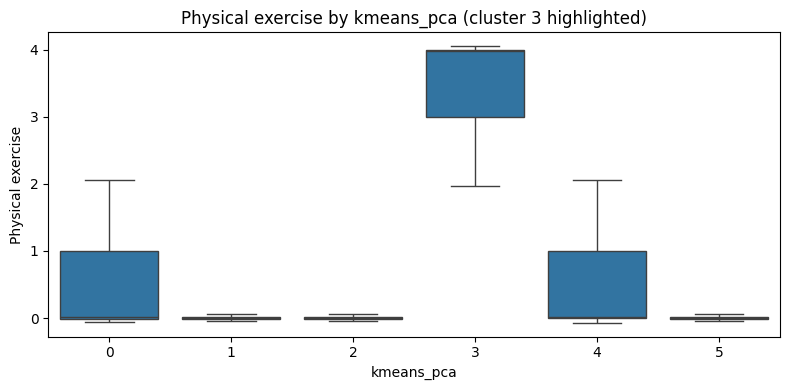

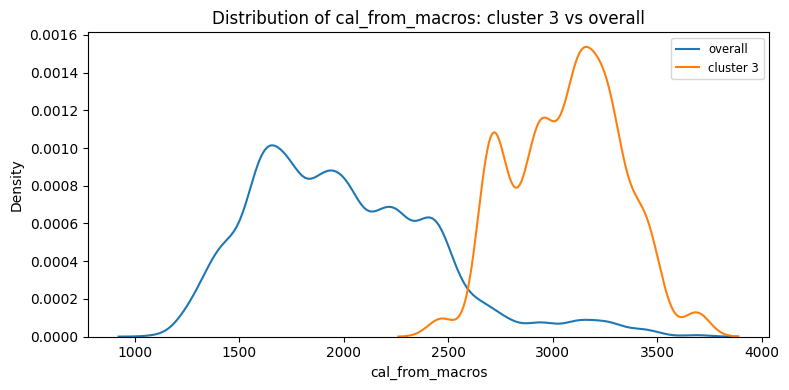

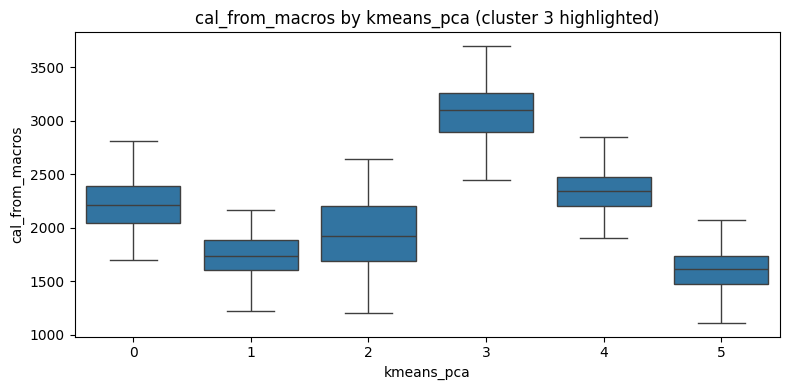

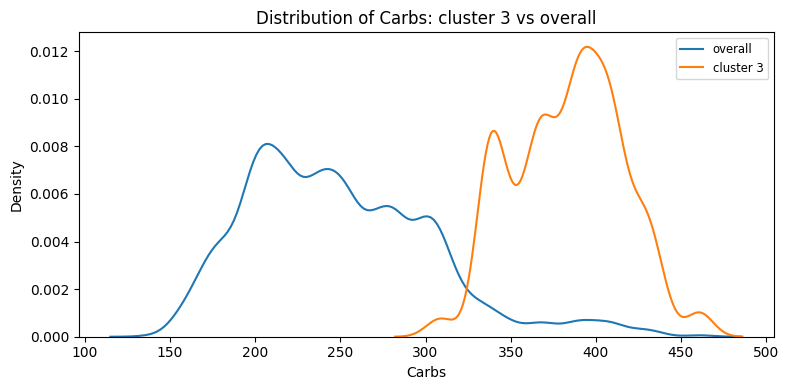

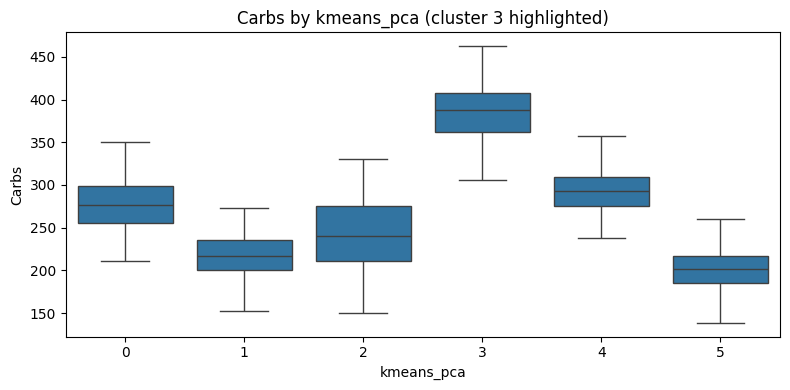

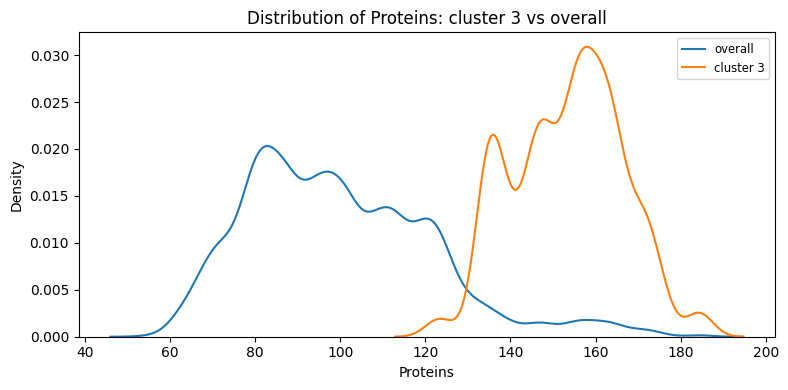

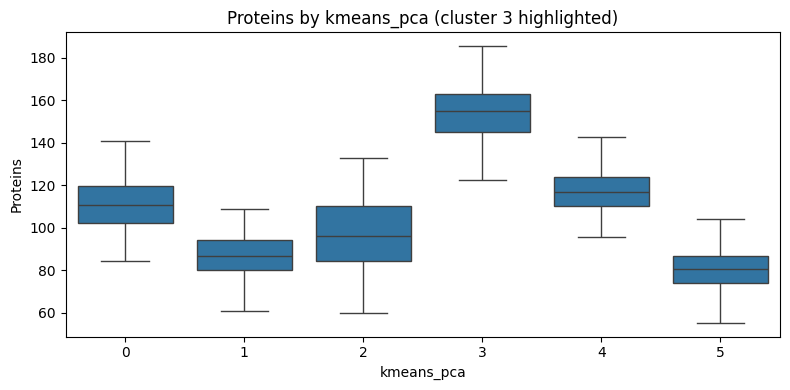

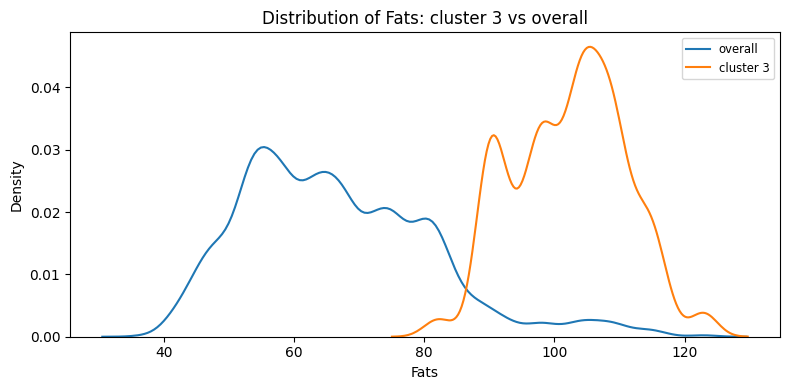

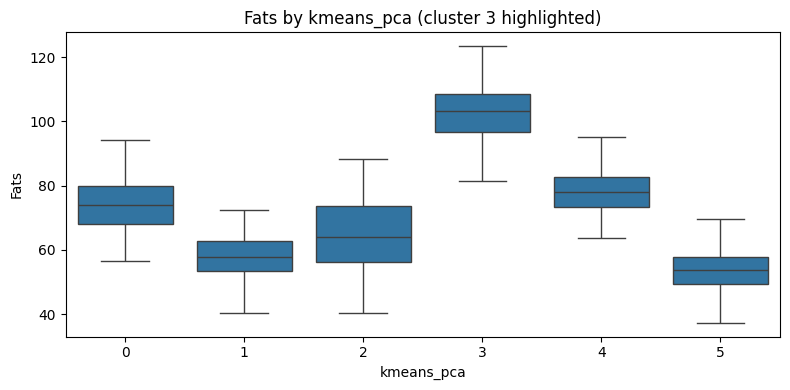

Cluster 3: n=1150, mean distance to center=2.118, std=1.365
  Outliers (dist > 3.0 std): 32 points

=== Analyzing top 6 clusters of 'agglo_pca' ===

--- Cluster 0 (6174 points, 30.9% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
     feature  effect_size  cluster_mean  global_mean
    Calories    -0.762515   1611.217849  2024.418300
 Weight (kg)    -0.759535     57.817180    73.898832
lean_mass_kg    -0.751491     44.393698    53.786384
    BMI_calc    -0.658642     20.507994    24.921651
         BMI    -0.658637     20.508073    24.921680

Suggested label: slightly low Calories, slightly low Weight (kg), slightly low lean_mass_kg, slightly low BMI_calc, slightly low BMI


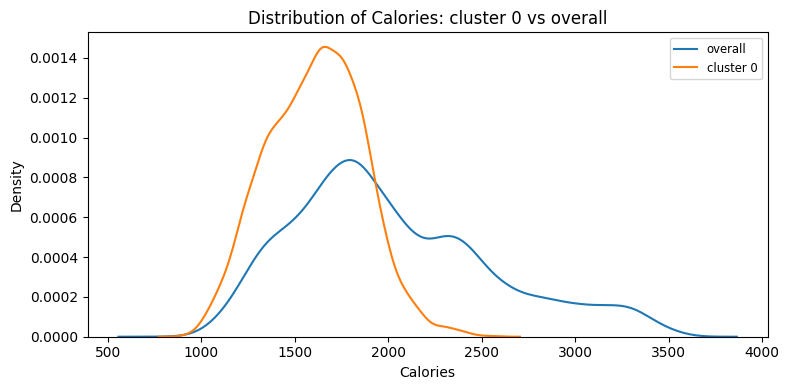

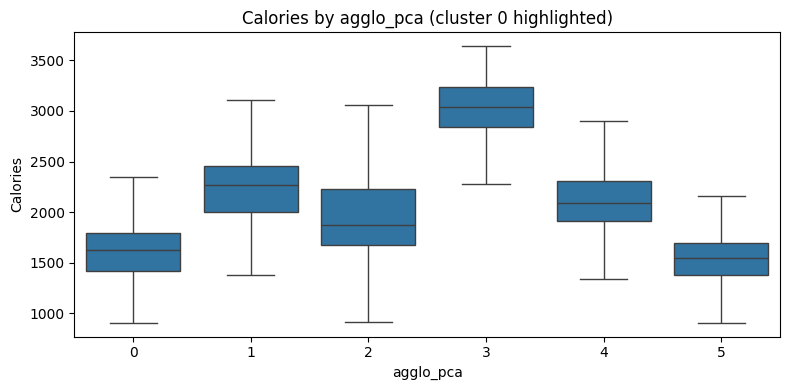

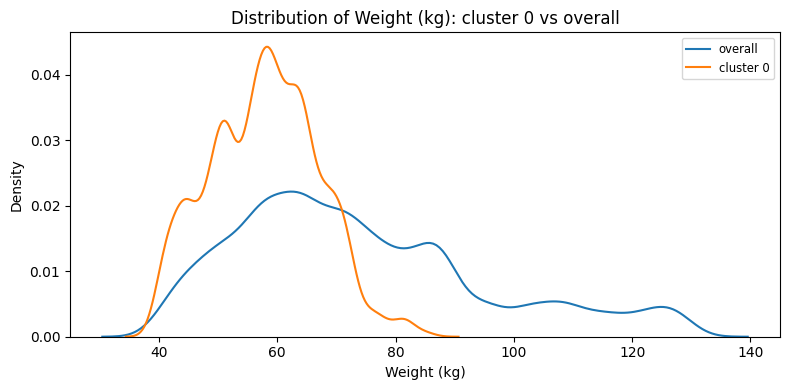

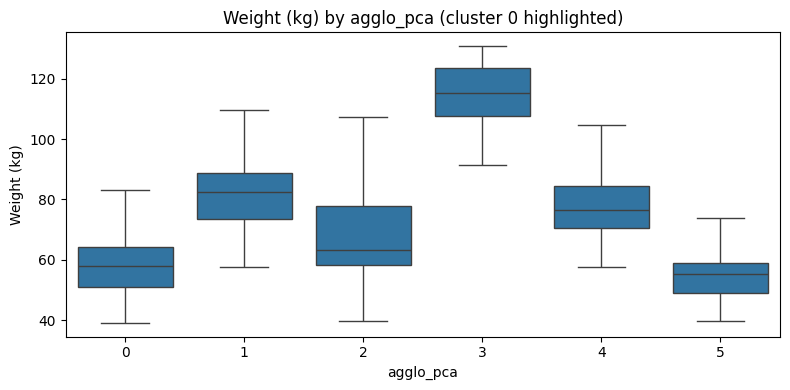

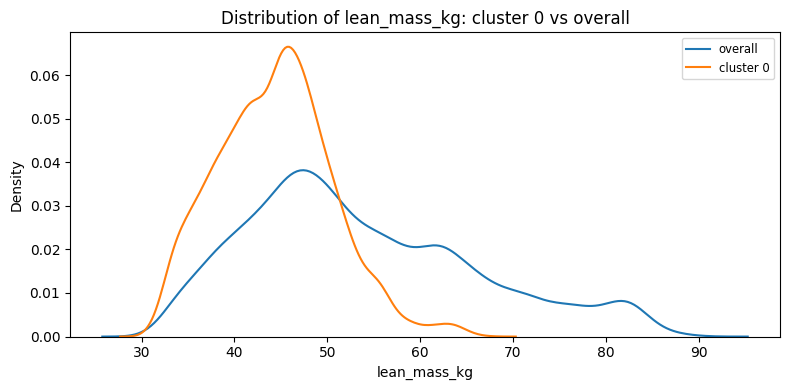

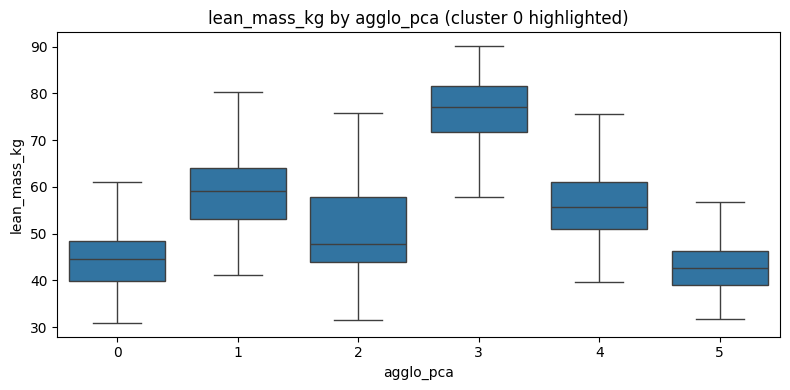

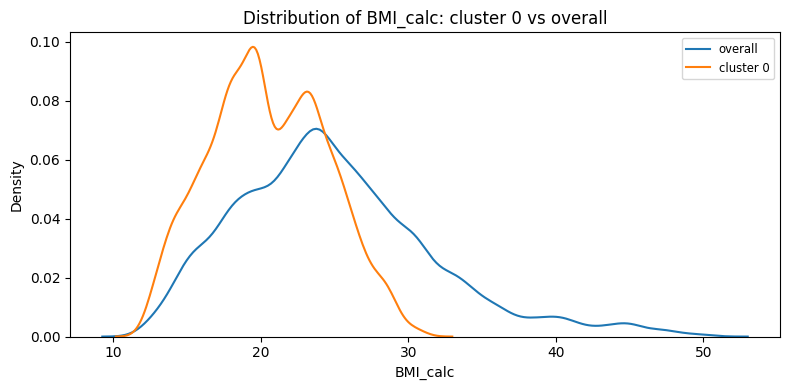

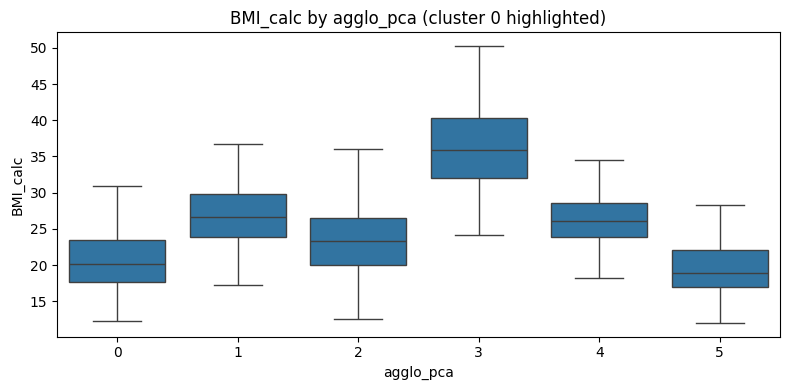

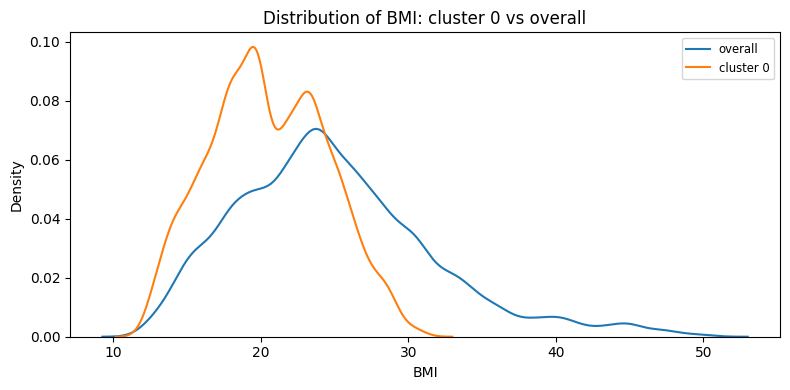

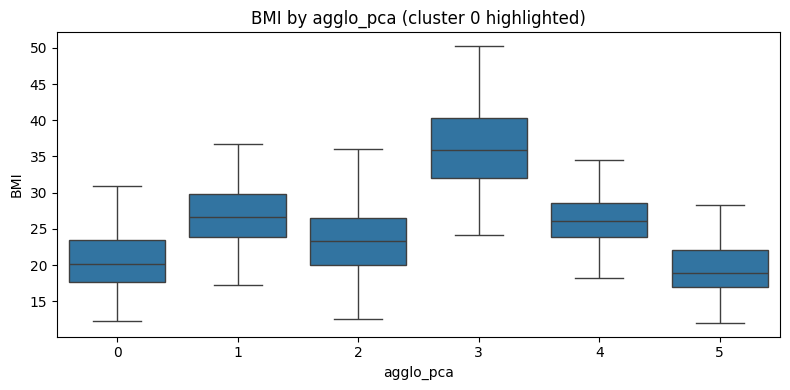

Cluster 0: n=6174, mean distance to center=1.385, std=0.689
  Outliers (dist > 3.0 std): 17 points

--- Cluster 1 (4393 points, 22.0% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
          Carbs     0.565267    280.929690   249.778592
cal_from_macros     0.565062   2247.403934  1998.297076
           Fats     0.564953     74.916576    66.612172
       Proteins     0.564366    112.358996    99.918290
   lean_mass_kg     0.410115     58.912301    53.786384

Suggested label: slightly high Carbs, slightly high cal_from_macros, slightly high Fats, slightly high Proteins


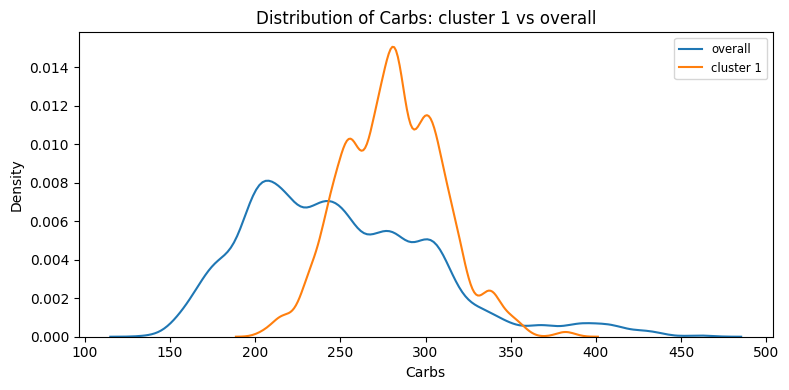

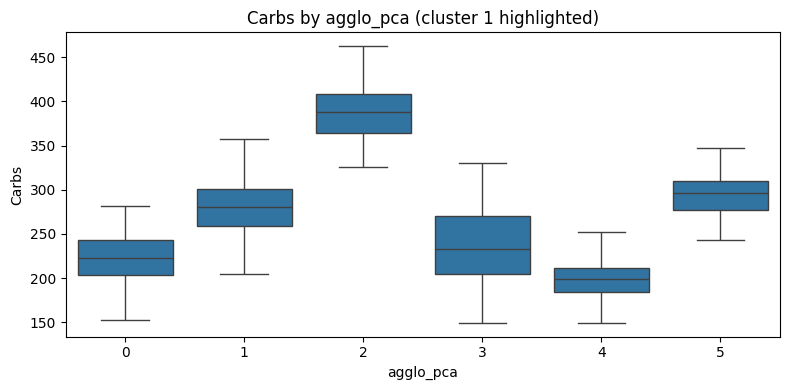

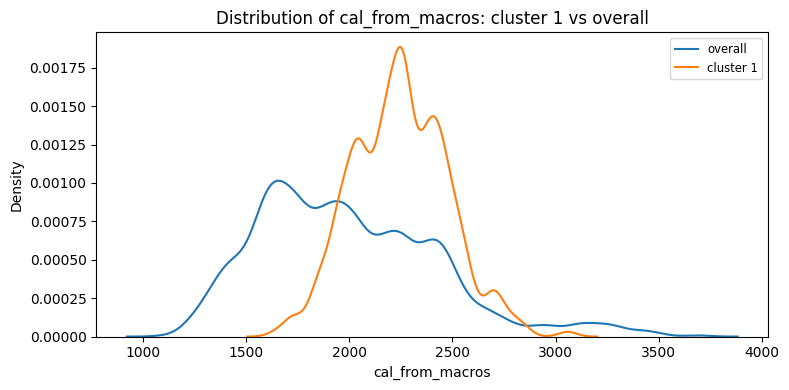

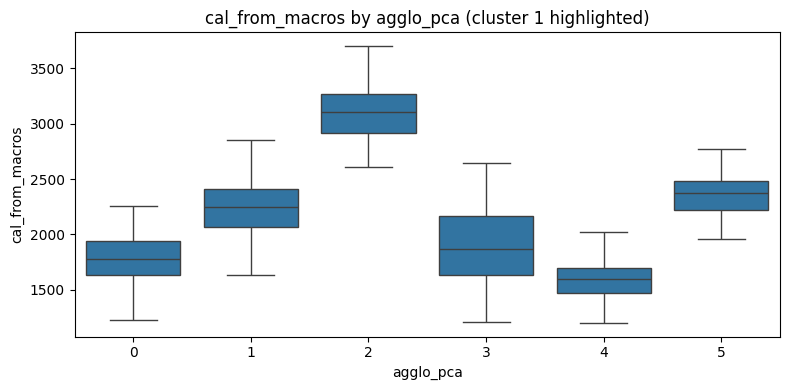

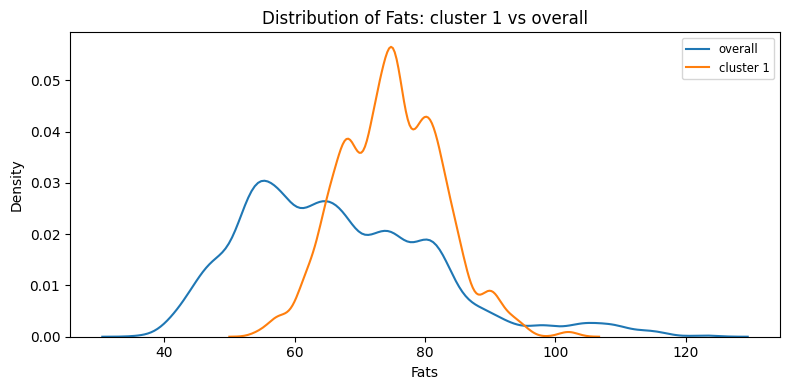

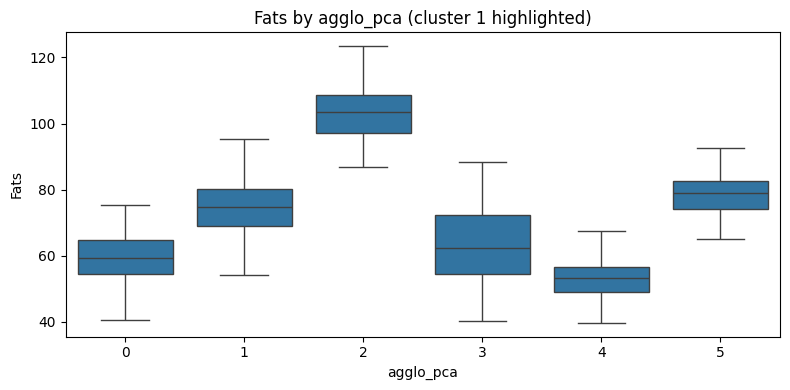

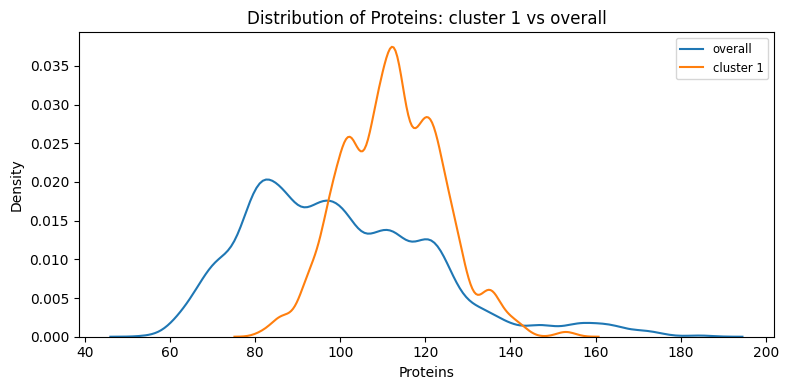

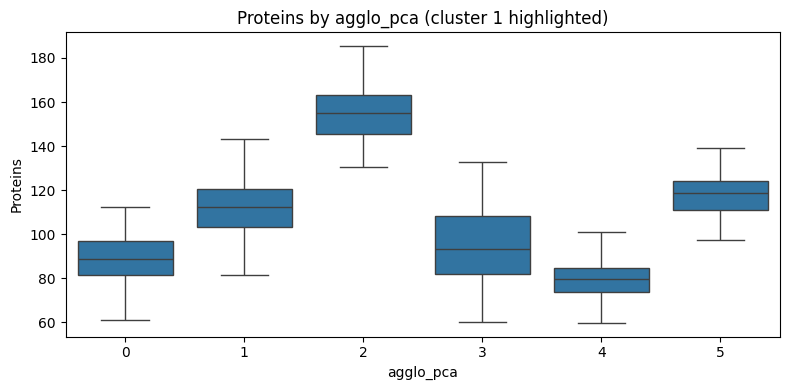

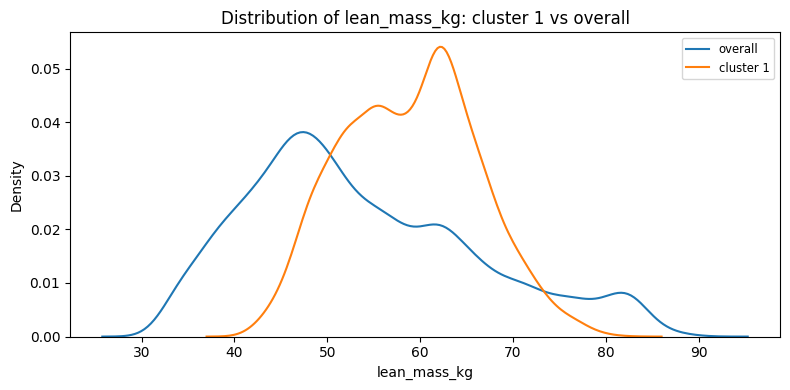

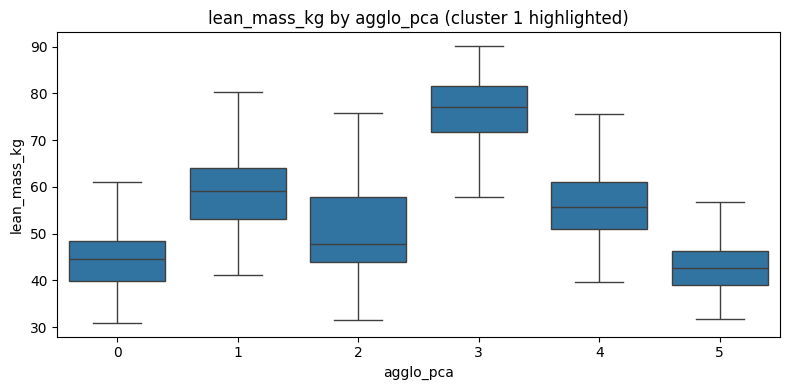

Cluster 1: n=4393, mean distance to center=1.533, std=0.709
  Outliers (dist > 3.0 std): 18 points

--- Cluster 4 (3636 points, 18.2% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
cal_from_macros    -0.926015   1590.065055  1998.297076
       Proteins    -0.925977     79.506350    99.918290
          Carbs    -0.925910    198.752946   249.778592
           Fats    -0.925833     53.003097    66.612172
 protein_per_kg    -0.814698      1.037358     1.460142

Suggested label: slightly low cal_from_macros, slightly low Proteins, slightly low Carbs, slightly low Fats, slightly low protein_per_kg


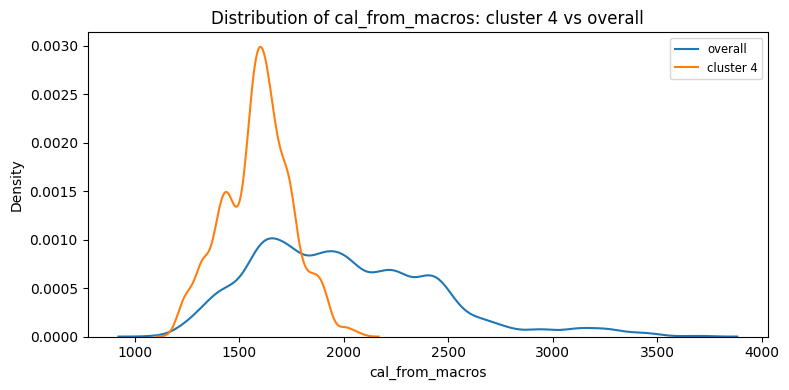

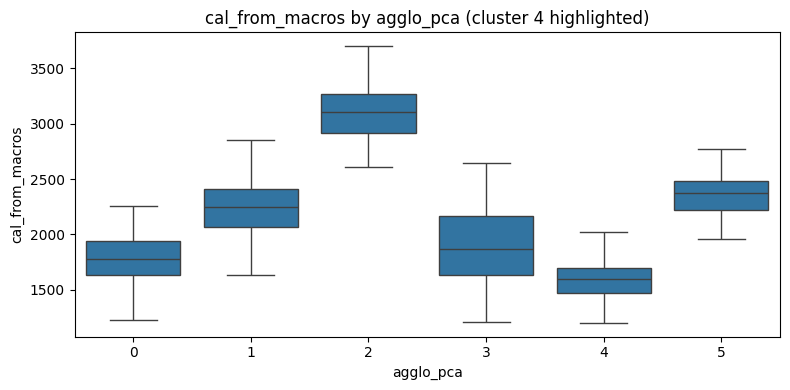

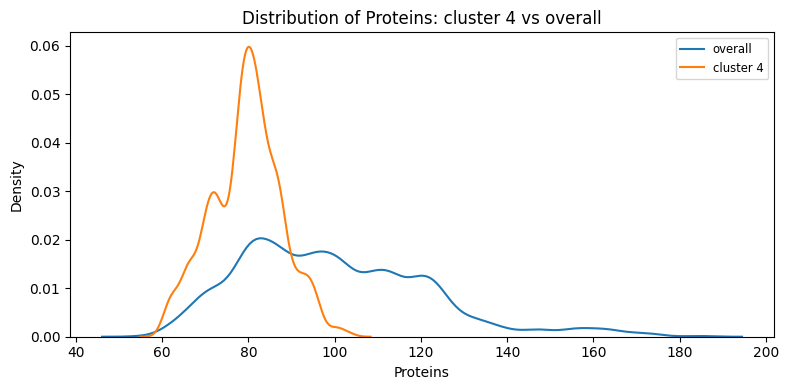

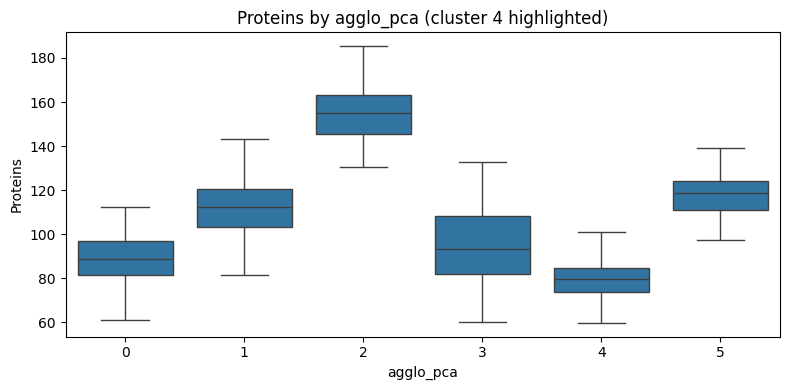

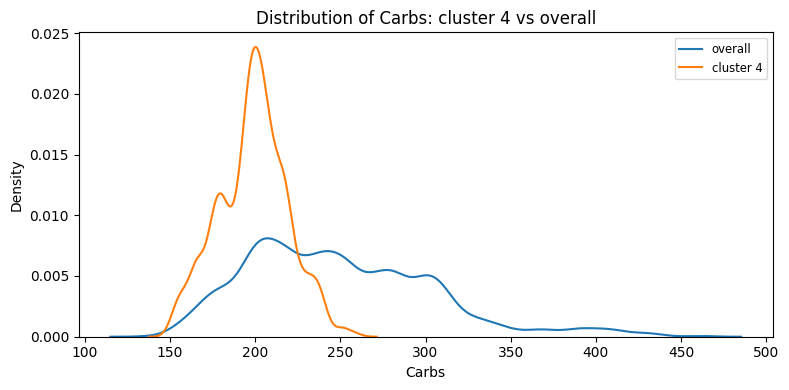

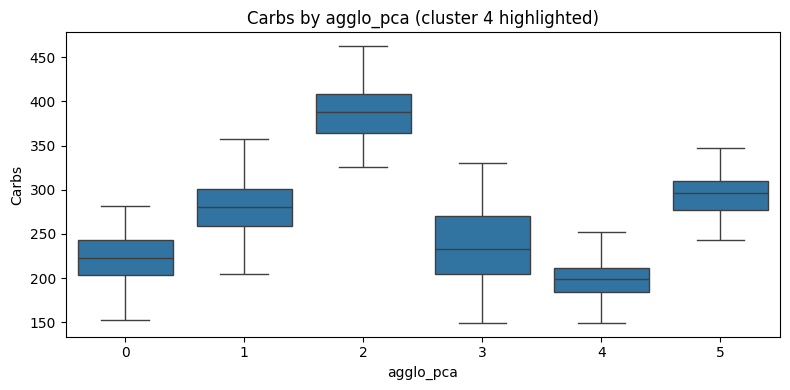

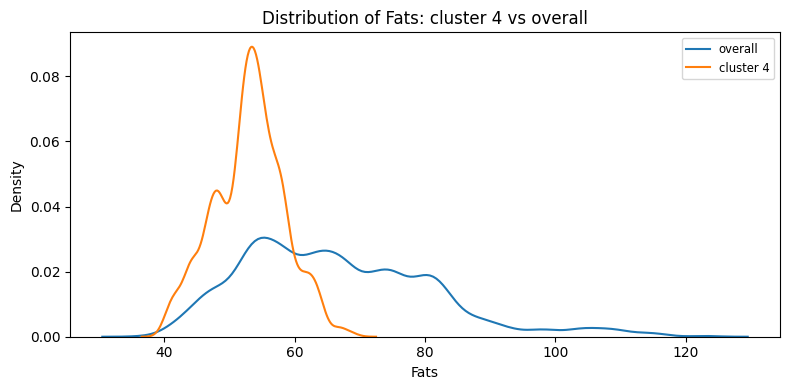

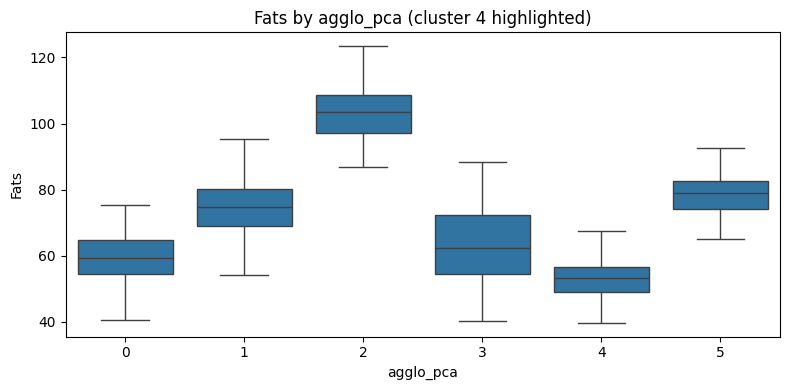

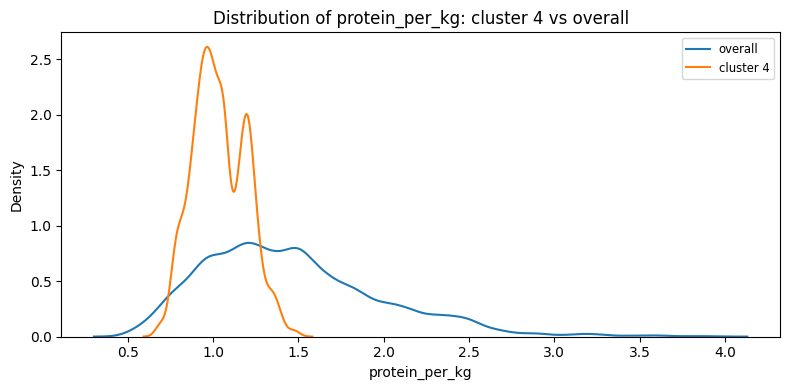

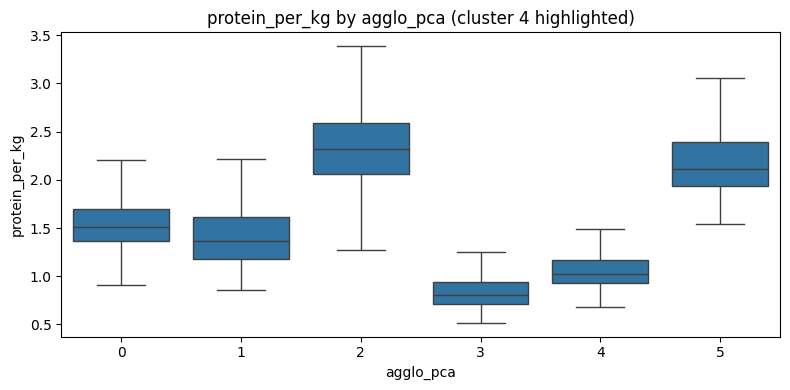

Cluster 4: n=3636, mean distance to center=1.141, std=0.534
  Outliers (dist > 3.0 std): 18 points

--- Cluster 3 (2415 points, 12.1% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
     feature  effect_size  cluster_mean  global_mean
 Weight (kg)     1.941622    115.008812    73.898832
    Calories     1.859686   3032.166460  2024.418300
lean_mass_kg     1.815279     76.475085    53.786384
         BMI     1.735830     36.553694    24.921680
    BMI_calc     1.735825     36.553667    24.921651

Suggested label: high Weight (kg), high Calories, high lean_mass_kg, high BMI, high BMI_calc


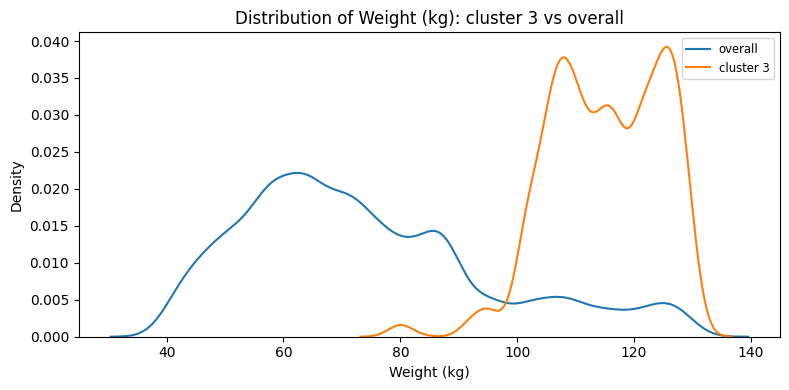

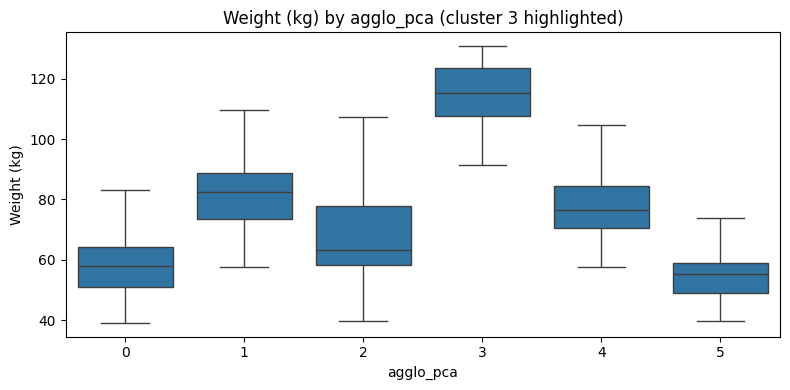

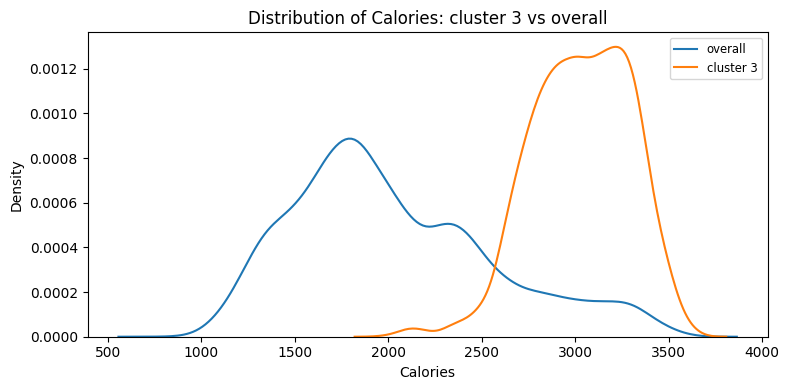

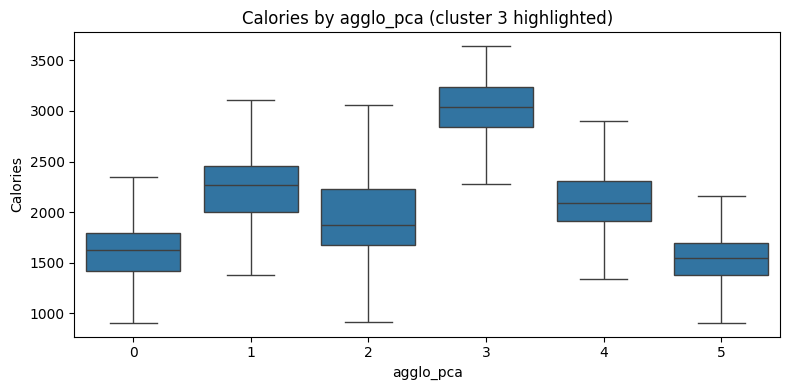

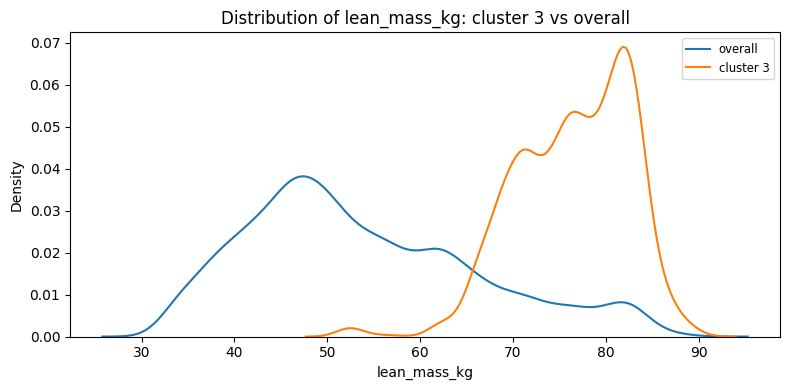

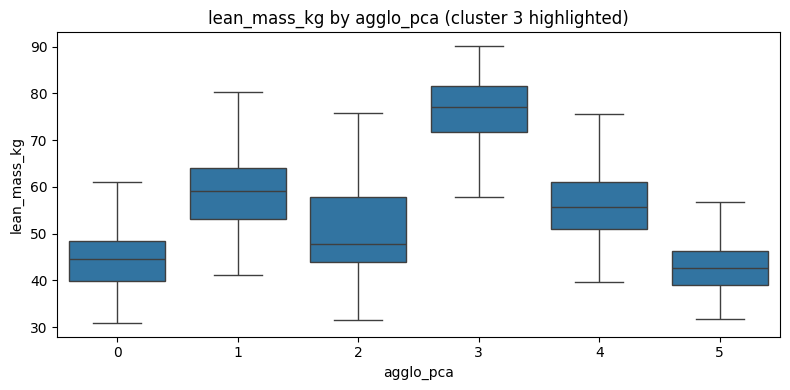

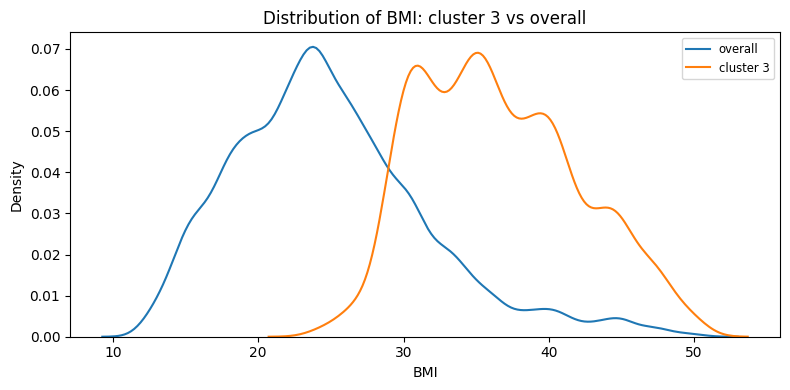

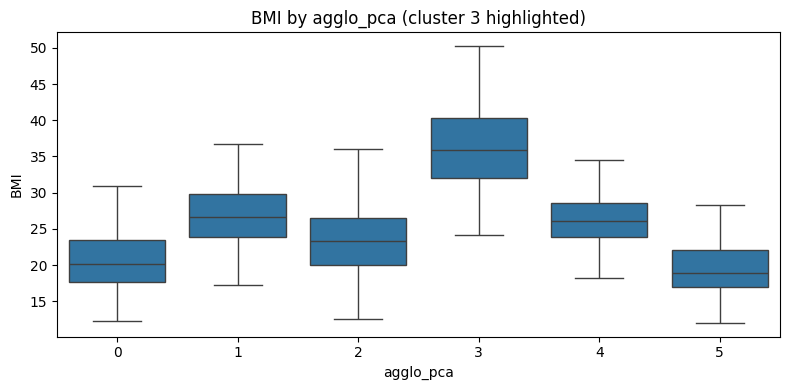

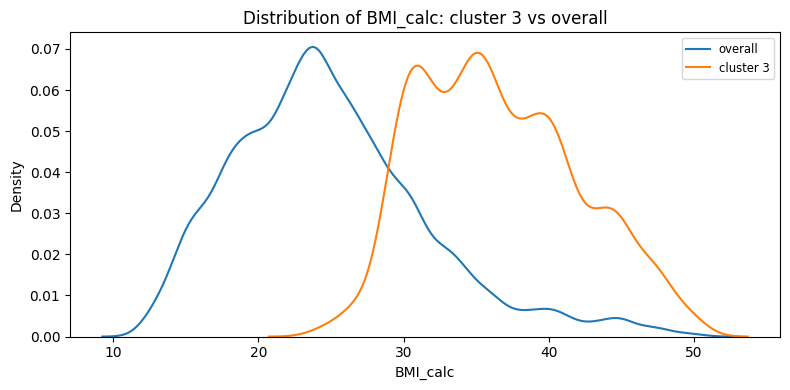

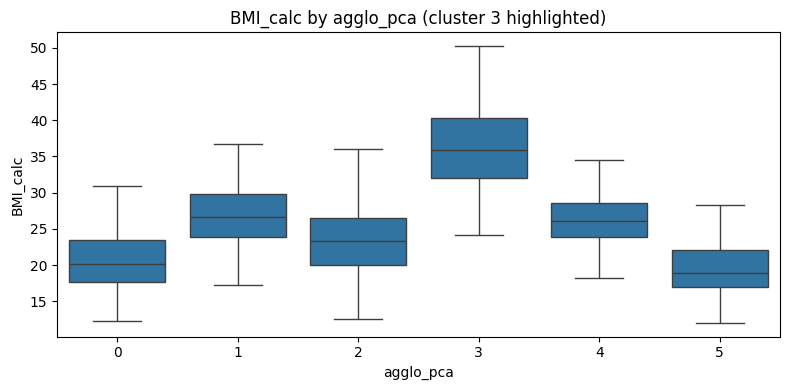

Cluster 3: n=2415, mean distance to center=1.790, std=0.872
  Outliers (dist > 3.0 std): 0 points

--- Cluster 5 (2253 points, 11.3% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
       feature  effect_size  cluster_mean  global_mean
protein_per_kg     1.383733      2.178224     1.460142
   Weight (kg)    -0.894276     54.964323    73.898832
      Calories    -0.890300   1541.972037  2024.418300
  lean_mass_kg    -0.877339     42.820746    53.786384
Fat_Percentage    -0.844768     21.880717    26.101313

Suggested label: high protein_per_kg, slightly low Weight (kg), slightly low Calories, slightly low lean_mass_kg, slightly low Fat_Percentage


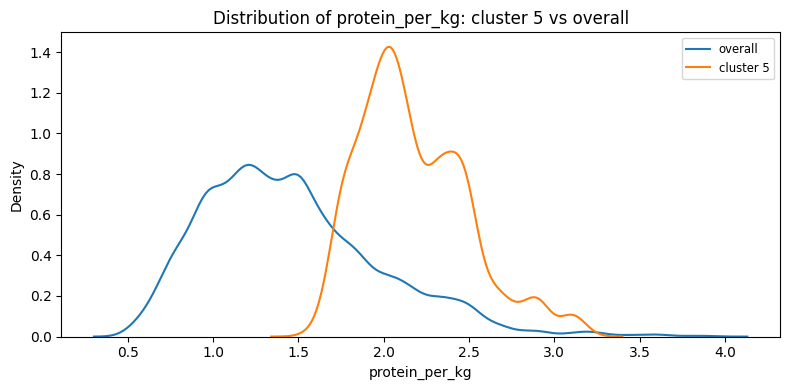

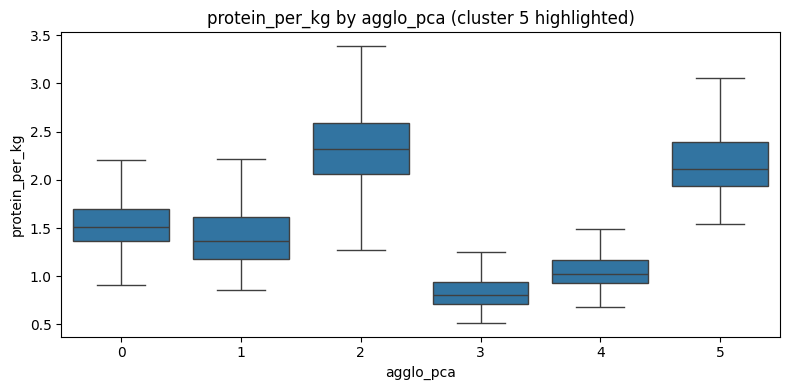

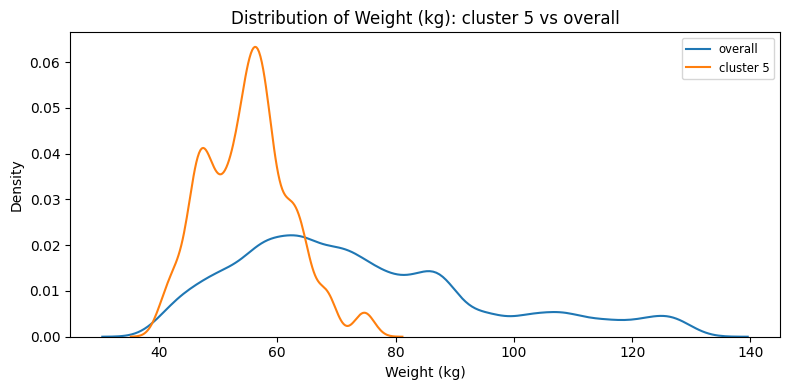

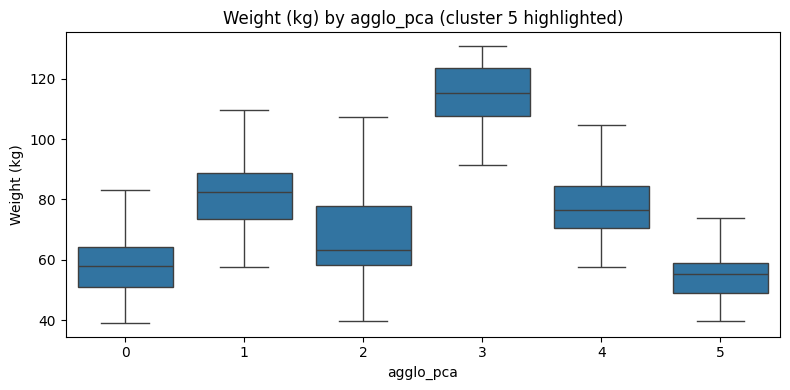

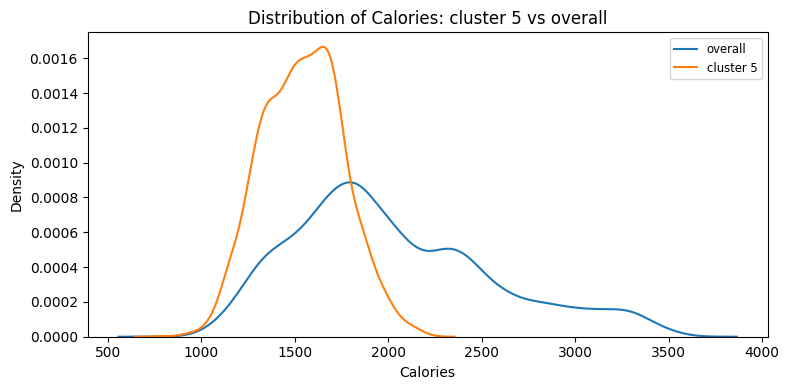

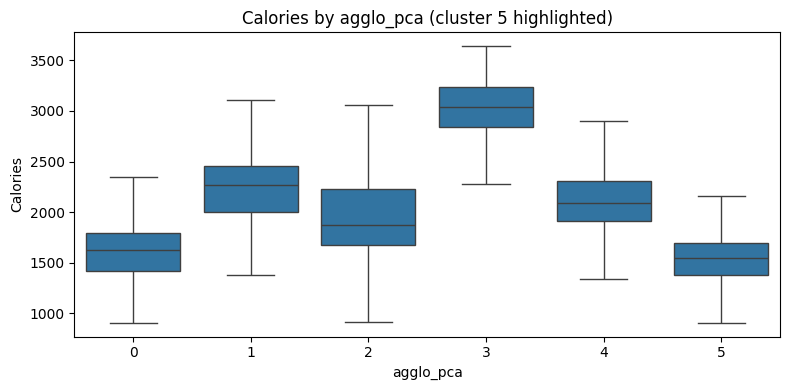

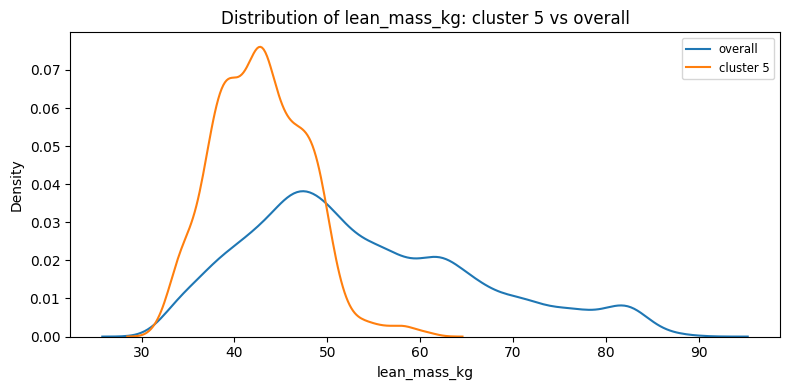

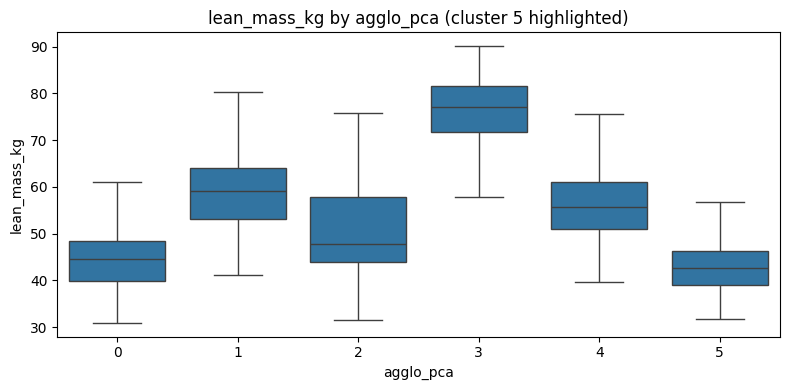

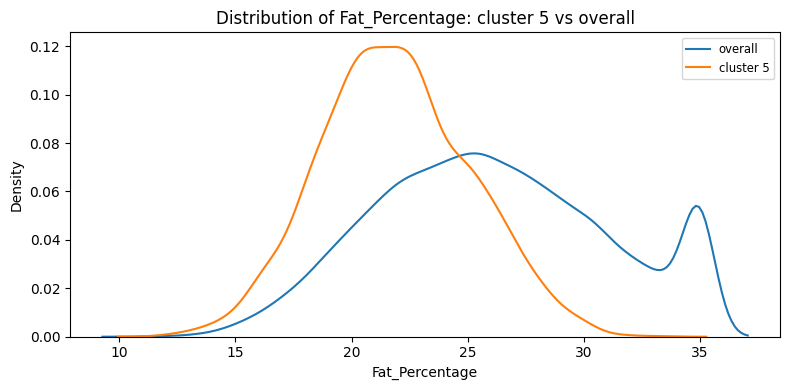

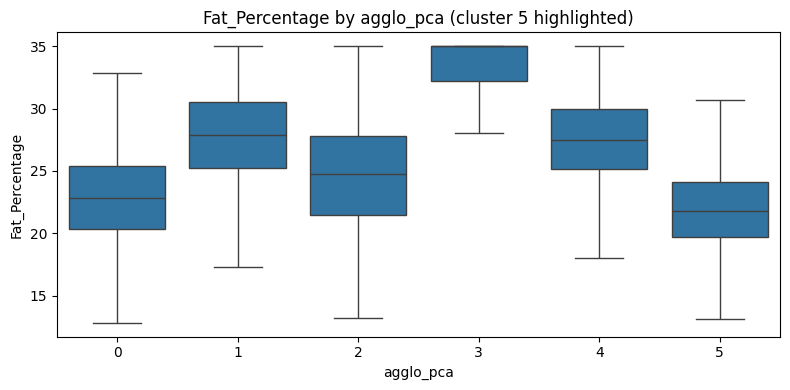

Cluster 5: n=2253, mean distance to center=1.191, std=0.521
  Outliers (dist > 3.0 std): 1 points

--- Cluster 2 (1129 points, 5.6% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
          feature  effect_size  cluster_mean  global_mean
Physical exercise     2.882689      3.296643     0.452503
  cal_from_macros     2.456193   3081.106058  1998.297076
         Proteins     2.456057    154.058804    99.918290
            Carbs     2.456056    385.128441   249.778592
             Fats     2.455505    102.706342    66.612172

Suggested label: high Physical exercise, high cal_from_macros, high Proteins, high Carbs, high Fats


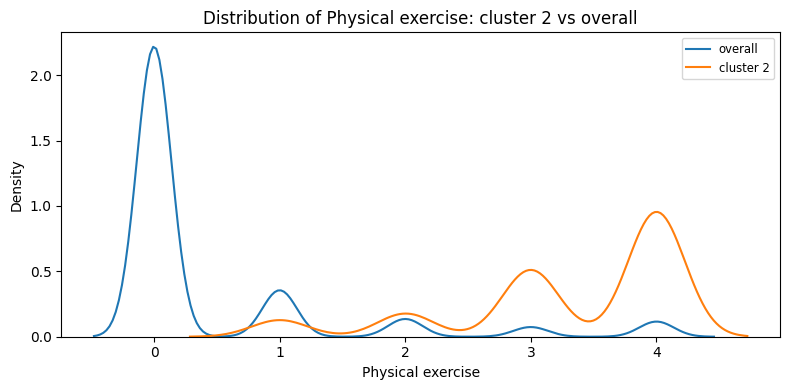

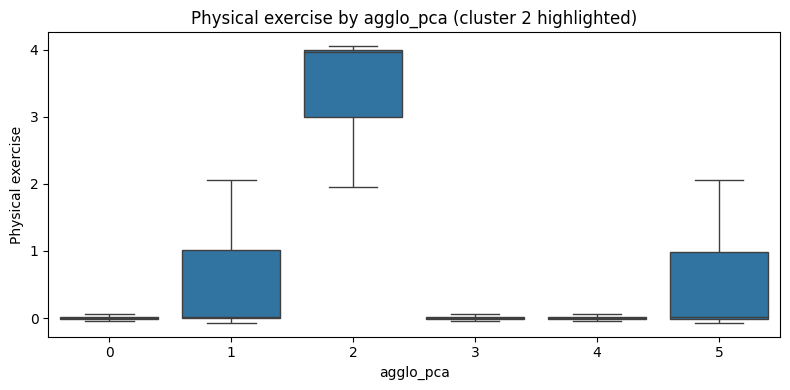

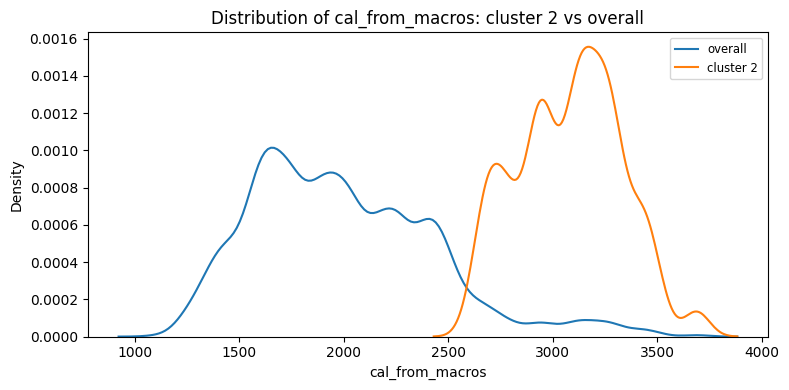

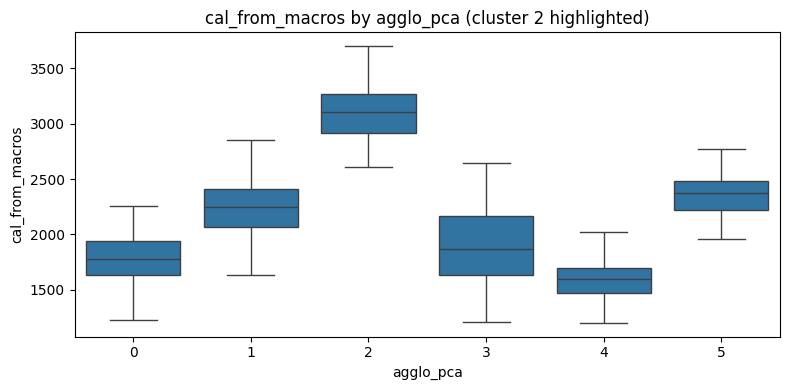

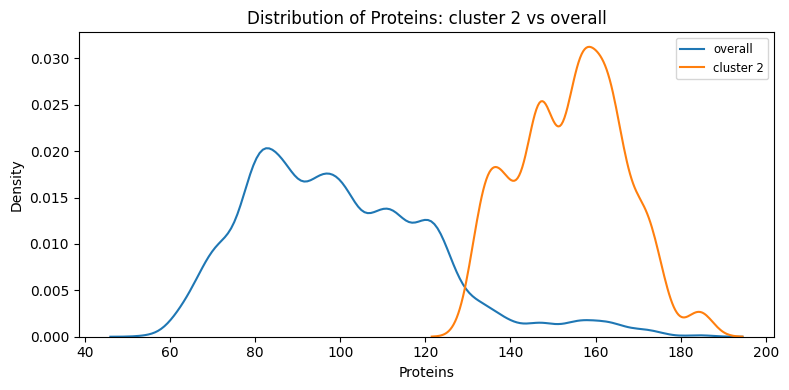

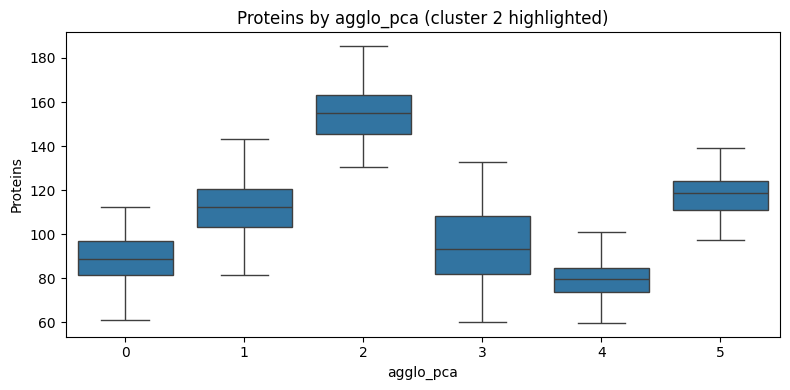

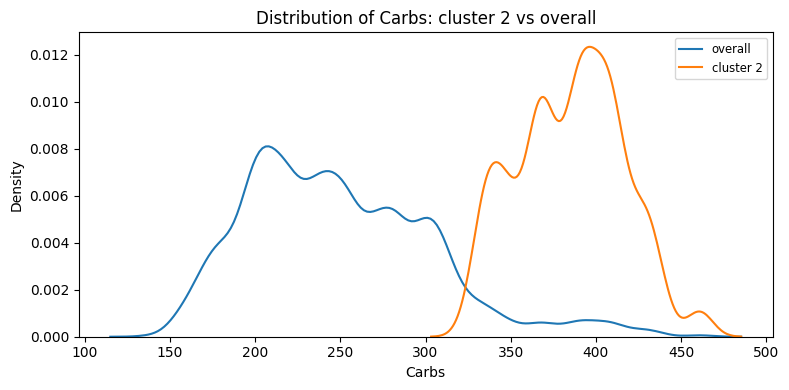

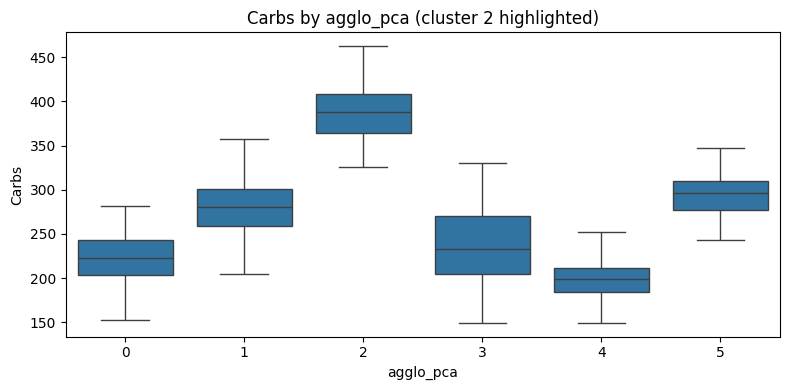

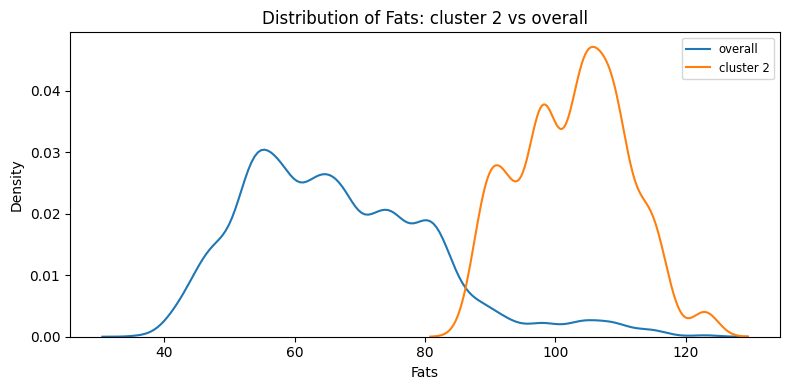

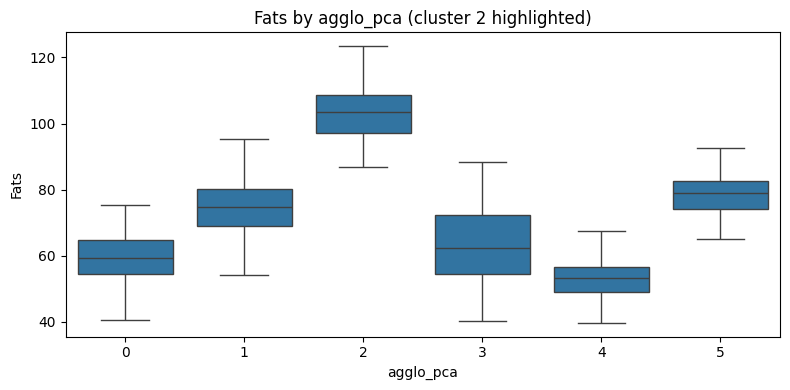

Cluster 2: n=1129, mean distance to center=2.228, std=1.516
  Outliers (dist > 3.0 std): 37 points

=== Analyzing top 3 clusters of 'kmeans_tsne' ===

--- Cluster 1 (6788 points, 33.9% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
 protein_per_kg     0.970124      1.963583     1.460142
cal_from_macros     0.842710   2369.804328  1998.297076
           Fats     0.842707     78.999361    66.612172

Suggested label: slightly high protein_per_kg, slightly high cal_from_macros, slightly high Fats


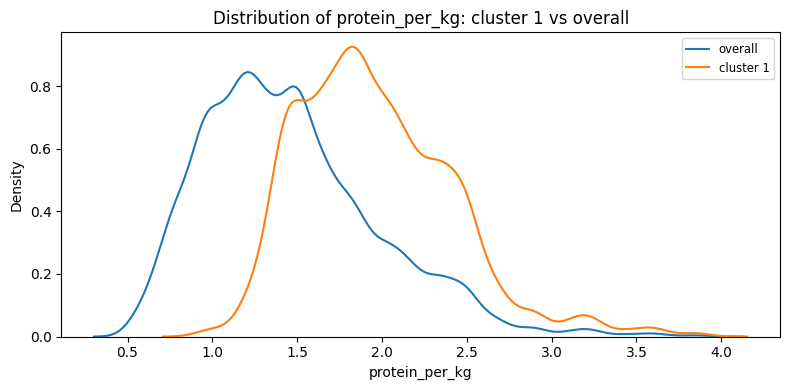

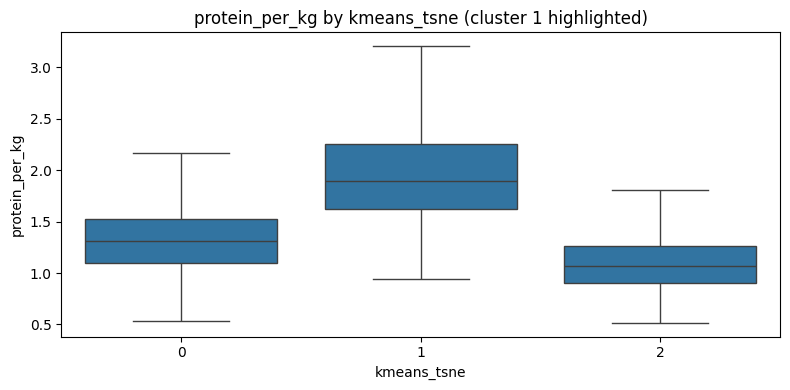

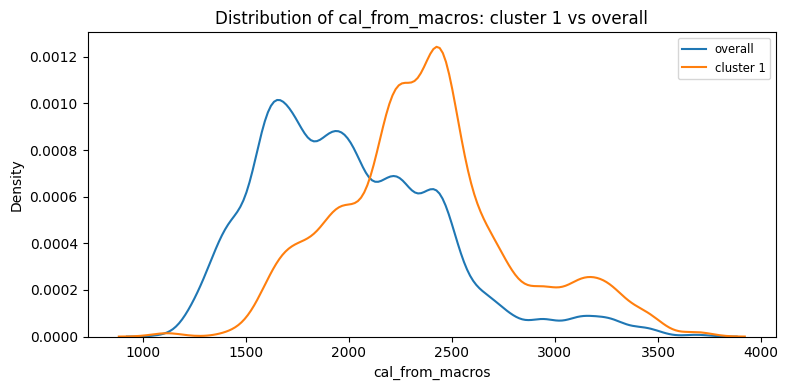

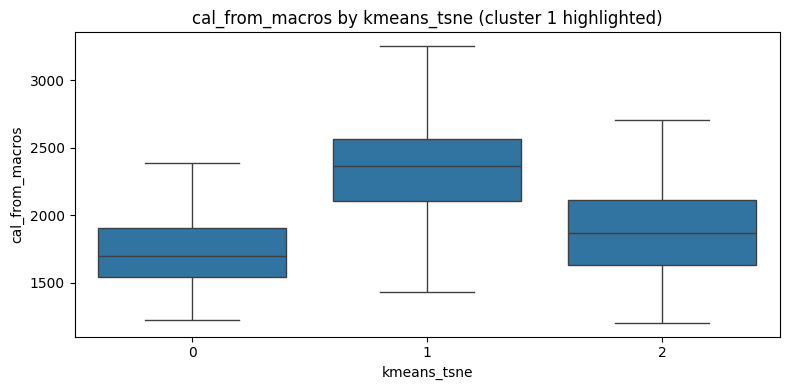

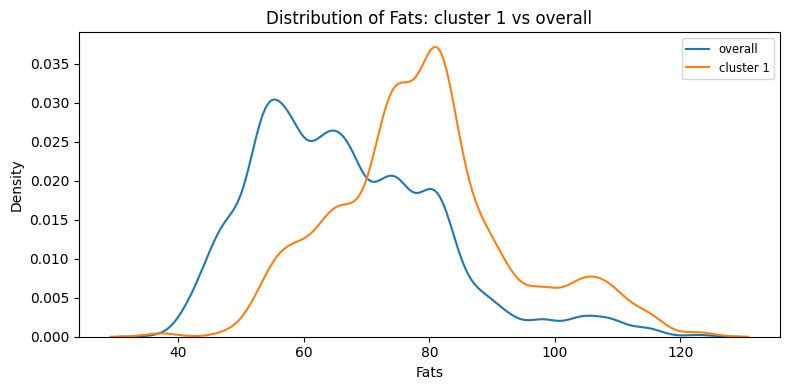

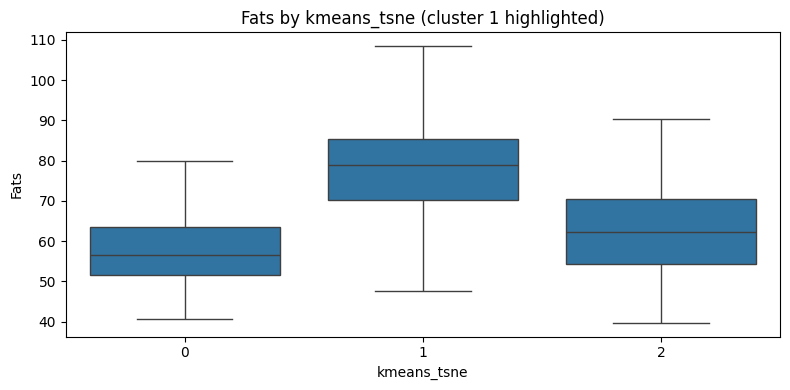

Cluster 1: n=6788, mean distance to center=40.036, std=17.443
  Outliers (dist > 3.0 std): 0 points

--- Cluster 2 (6770 points, 33.9% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
     feature  effect_size  cluster_mean  global_mean
    Calories     0.766343   2439.693058  2024.418300
 Weight (kg)     0.756615     89.918648    73.898832
lean_mass_kg     0.755386     63.227761    53.786384

Suggested label: slightly high Calories, slightly high Weight (kg), slightly high lean_mass_kg


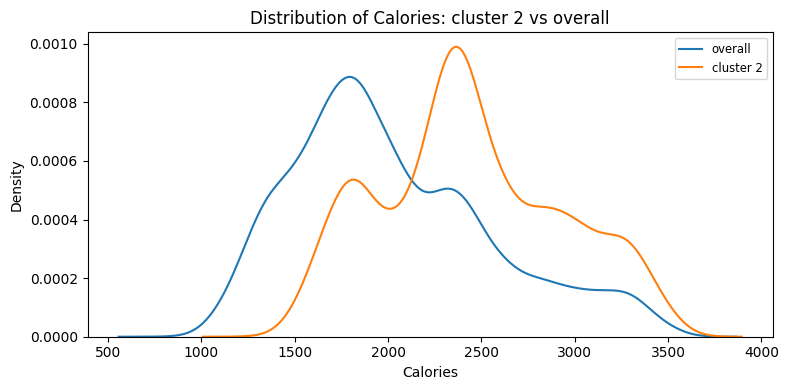

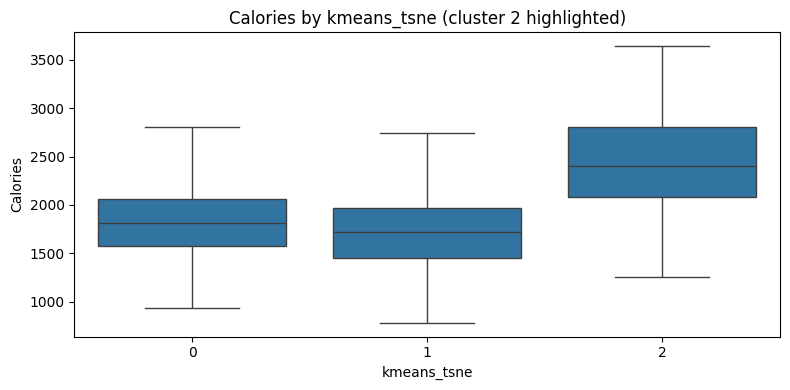

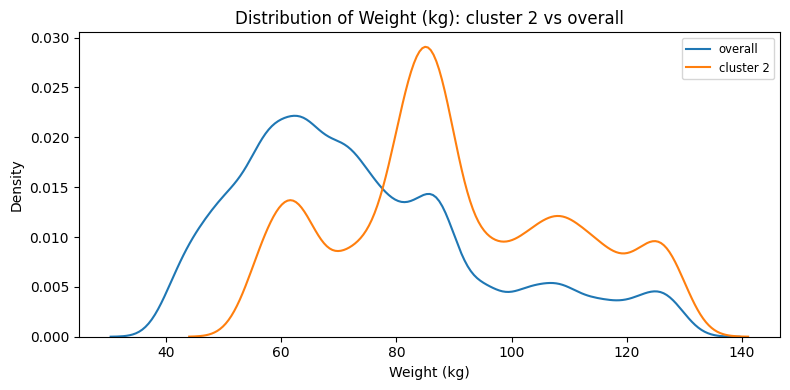

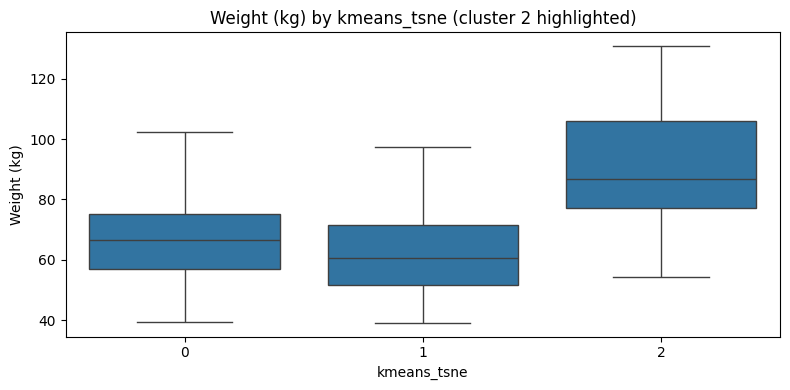

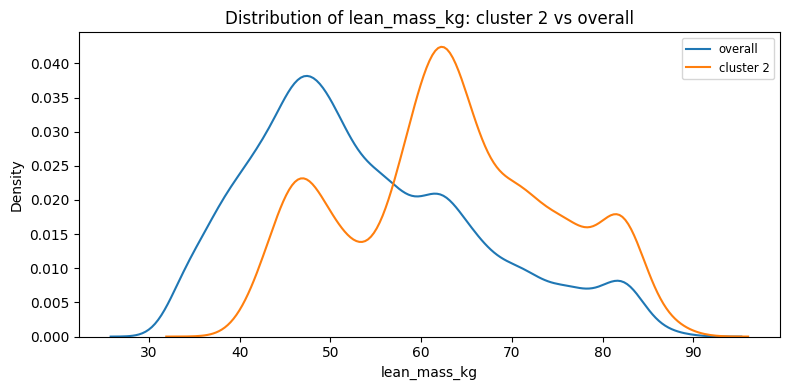

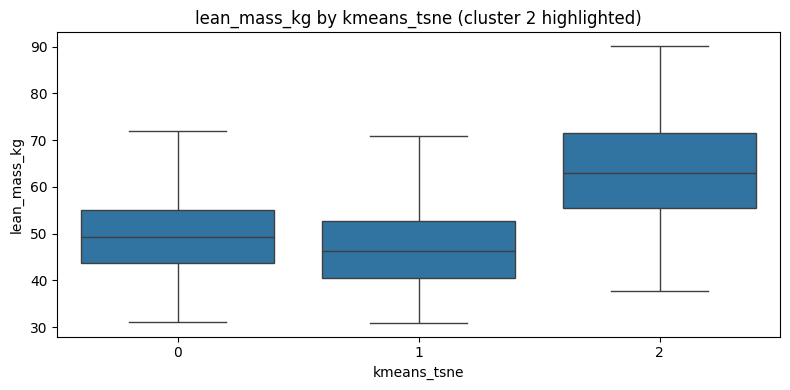

Cluster 2: n=6770, mean distance to center=40.090, std=17.317
  Outliers (dist > 3.0 std): 0 points

--- Cluster 0 (6442 points, 32.2% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
cal_from_macros    -0.607465   1730.497144  1998.297076
          Carbs    -0.607434    216.303743   249.778592
           Fats    -0.607419     57.683552    66.612172

Suggested label: slightly low cal_from_macros, slightly low Carbs, slightly low Fats


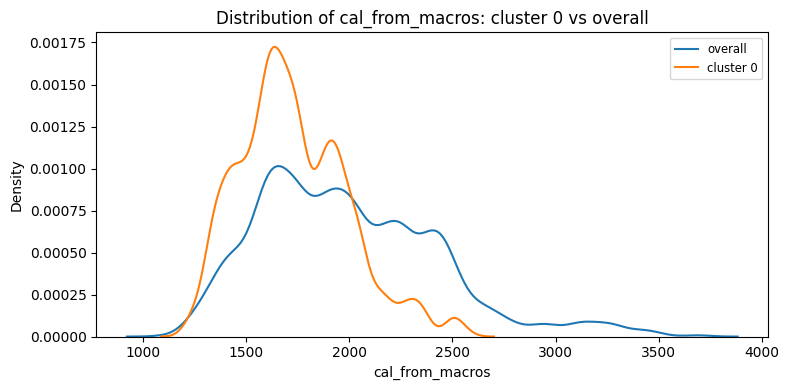

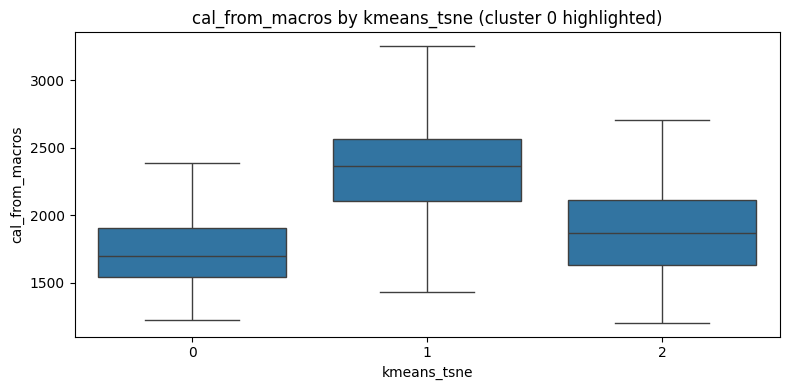

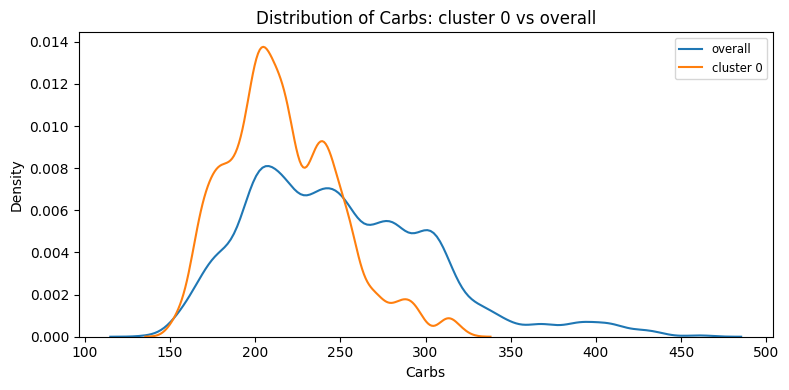

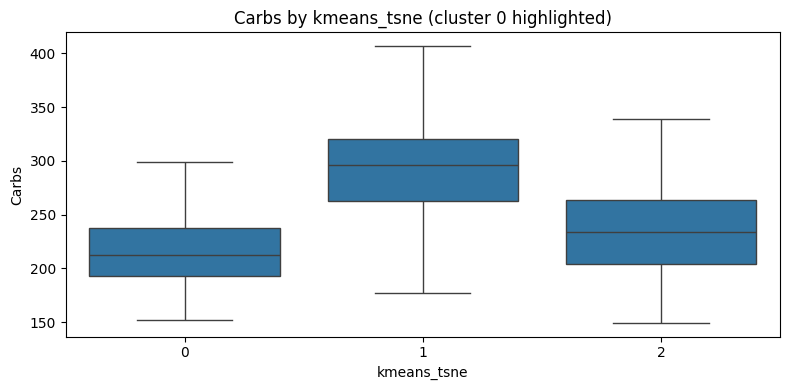

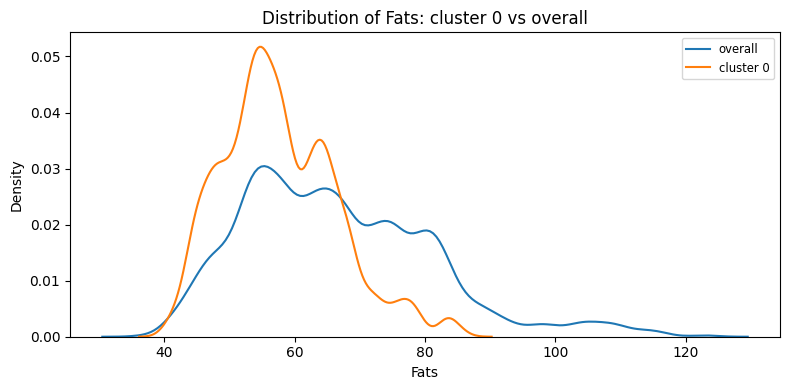

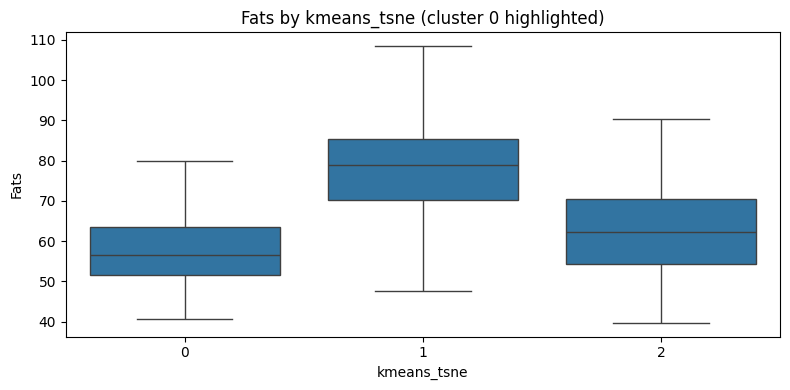

Cluster 0: n=6442, mean distance to center=37.680, std=16.573
  Outliers (dist > 3.0 std): 0 points

=== Analyzing top 5 clusters of 'agglo_tsne' ===

--- Cluster 2 (5261 points, 26.3% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
     feature  effect_size  cluster_mean  global_mean
 Weight (kg)     1.153716     98.326472    73.898832
    Calories     1.097200   2618.981753  2024.418300
lean_mass_kg     1.090654     67.418188    53.786384
         BMI     1.035462     31.860445    24.921680
    BMI_calc     1.035459     31.860414    24.921651
 cal_balance     1.022564   1481.522701   744.308699

Suggested label: high Weight (kg), high Calories, high lean_mass_kg, high BMI, high BMI_calc, high cal_balance


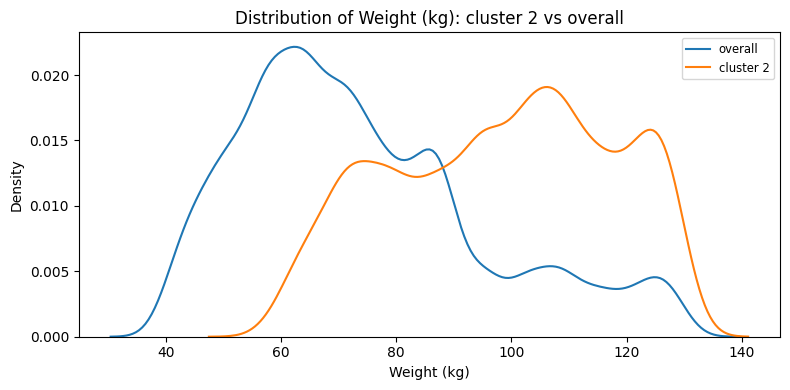

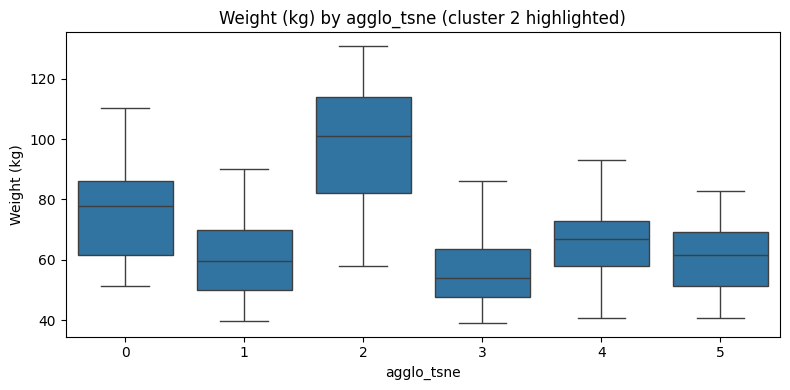

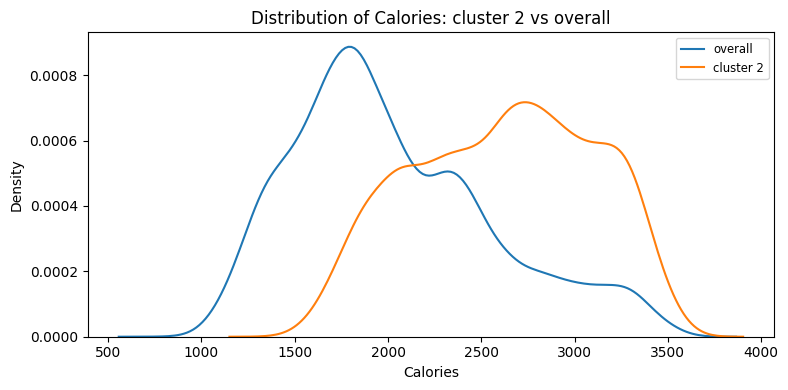

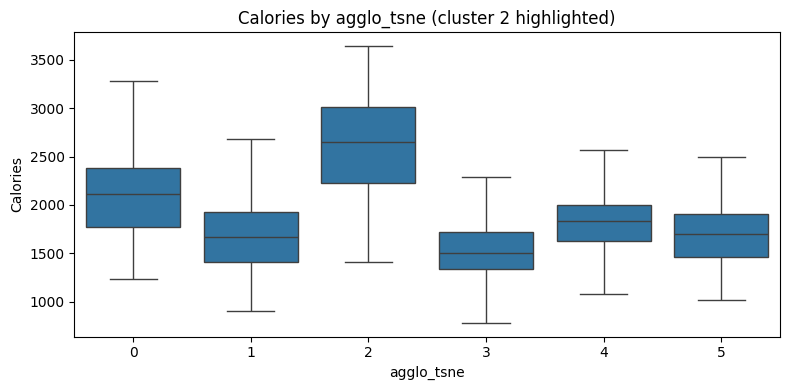

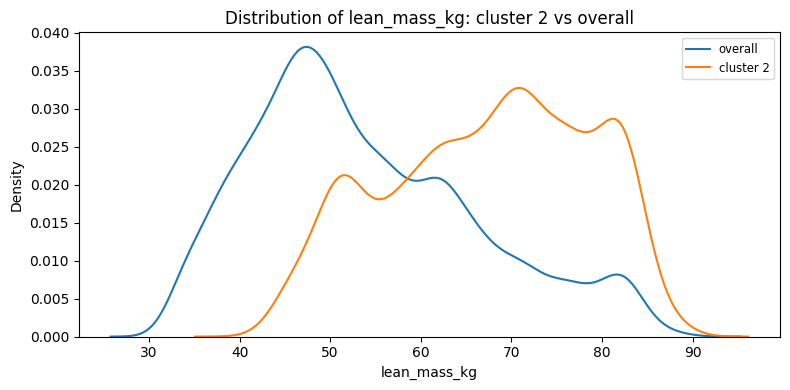

...

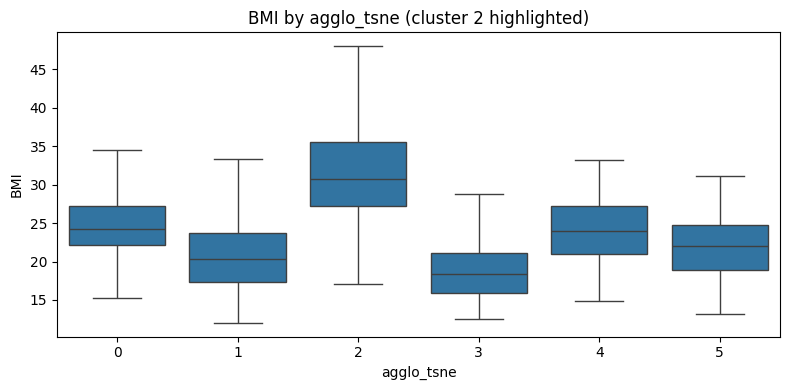

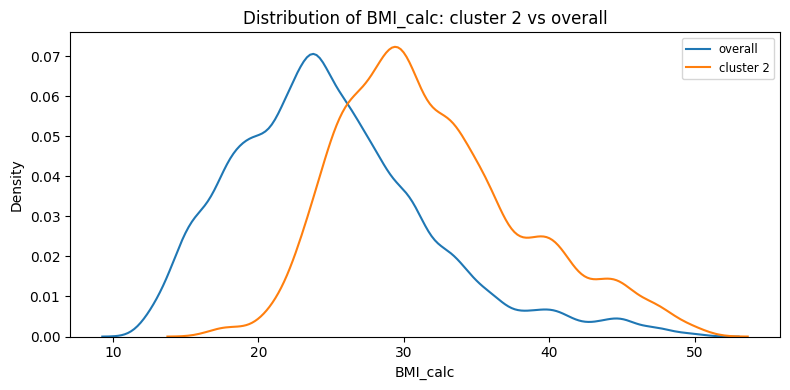

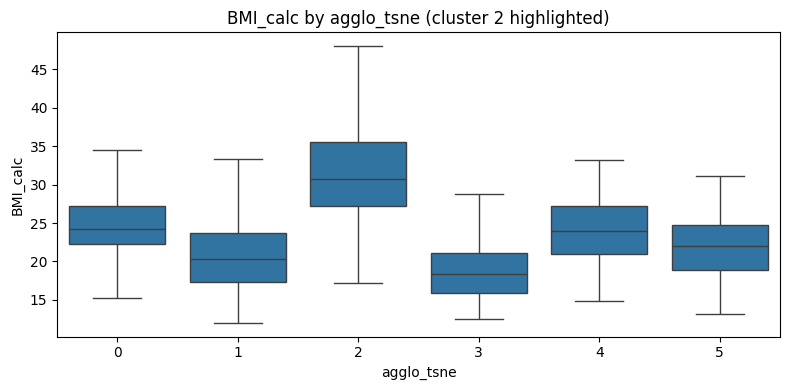

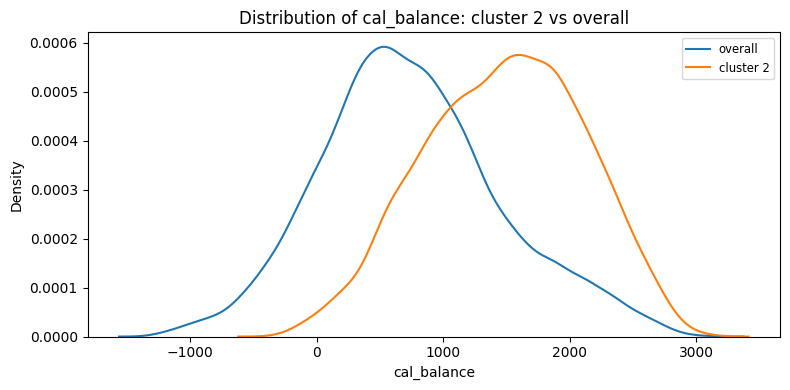

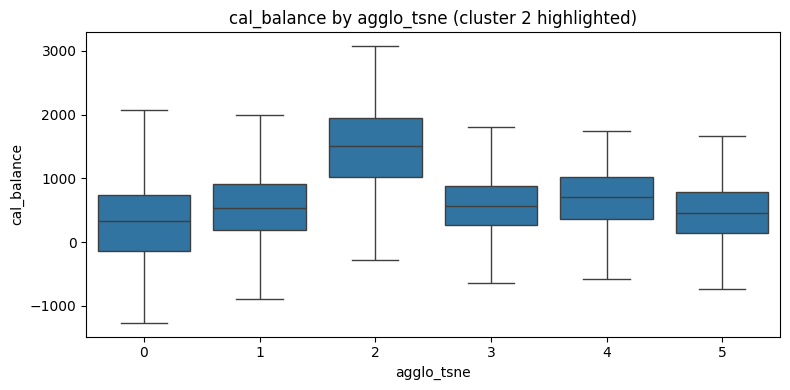

Cluster 2: n=5261, mean distance to center=33.978, std=13.667
  Outliers (dist > 3.0 std): 0 points

--- Cluster 0 (4906 points, 24.5% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
                      feature  effect_size  cluster_mean  global_mean
             Experience_Level     1.183627      2.680567     1.809176
                expected_burn     1.123254   1147.522024   866.352318
     Session_Duration (hours)     1.109184      1.638051     1.259446
Workout_Frequency (days/week)     1.008322      4.237409     3.318629
              Calories_Burned     0.995516   1780.086665  1280.109600
        Water_Intake (liters)     0.679632      3.038475     2.627485

Suggested label: high Experience_Level, high expected_burn, high Session_Duration (hours), high Workout_Frequency (days/week), slightly high Calories_Burned, slightly high Water_Intake (liters)


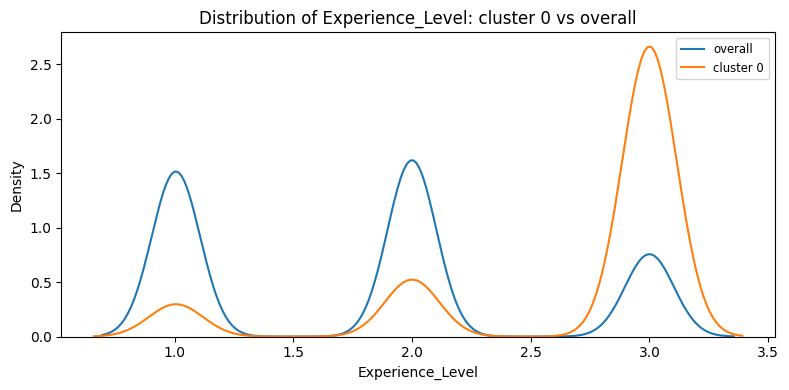

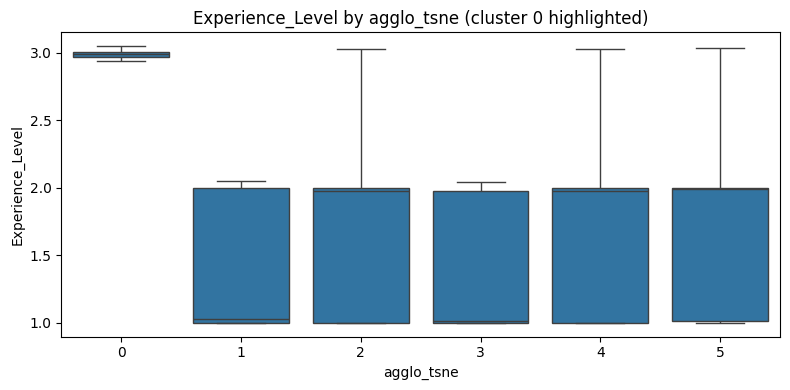

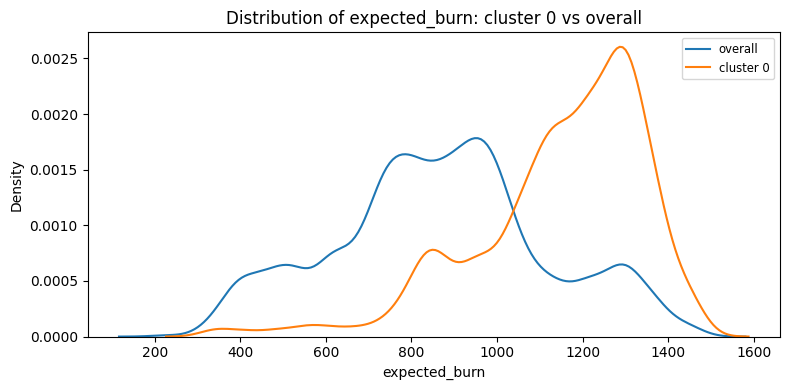

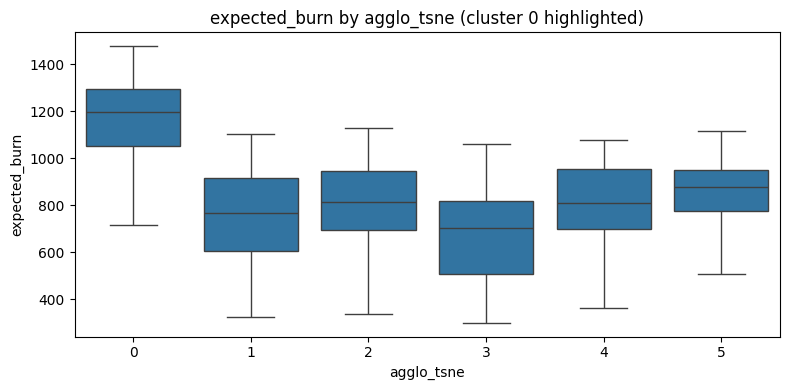

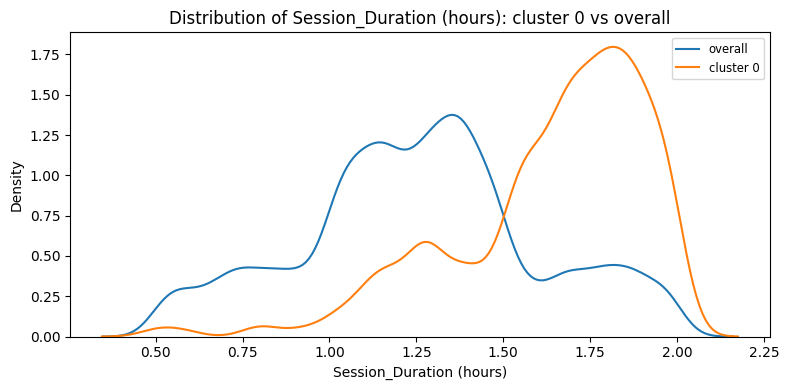

...

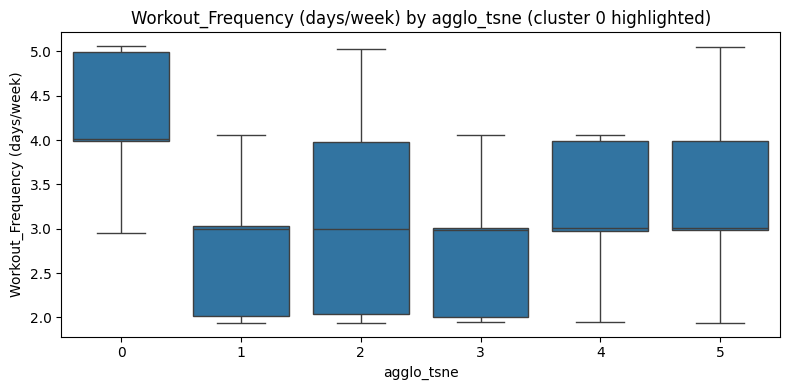

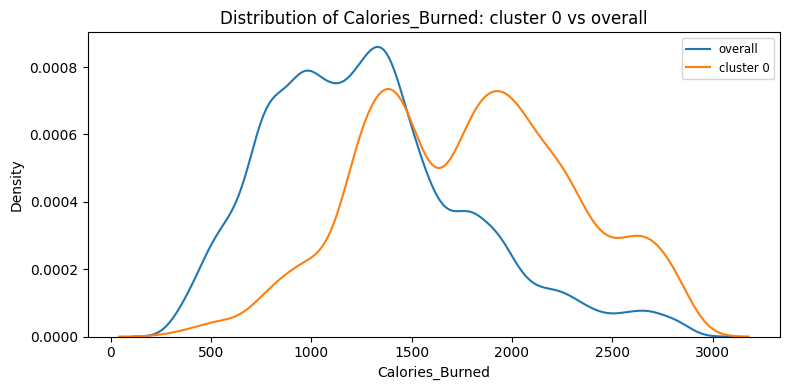

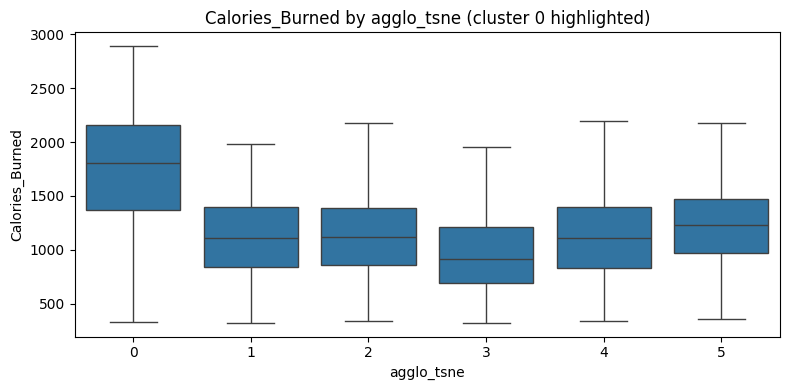

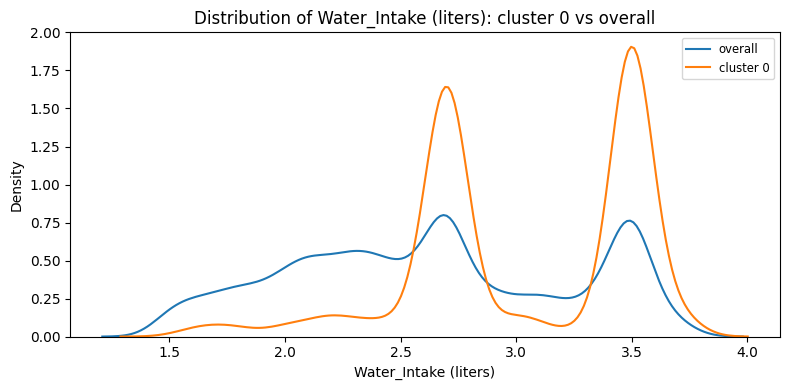

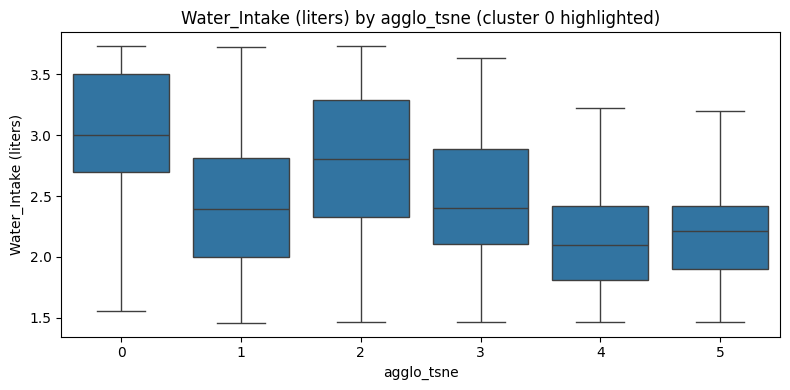

Cluster 0: n=4906, mean distance to center=33.344, std=13.527
  Outliers (dist > 3.0 std): 0 points

--- Cluster 1 (3098 points, 15.5% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
        feature  effect_size  cluster_mean  global_mean
 protein_per_kg     1.248459      2.108024     1.460142
cal_from_macros     1.049074   2460.779496  1998.297076
          Carbs     1.048986    307.586743   249.778592
           Fats     1.048954     82.031039    66.612172
       Proteins     1.048827    123.038292    99.918290
       Calories    -0.647555   1673.513880  2024.418300

Suggested label: high protein_per_kg, high cal_from_macros, high Carbs, high Fats, high Proteins, slightly low Calories


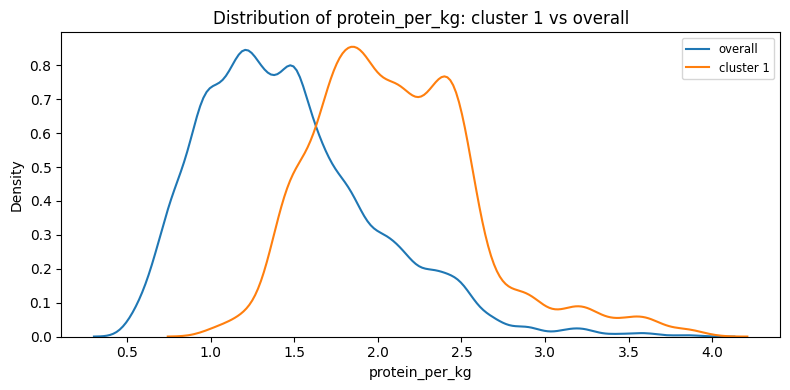

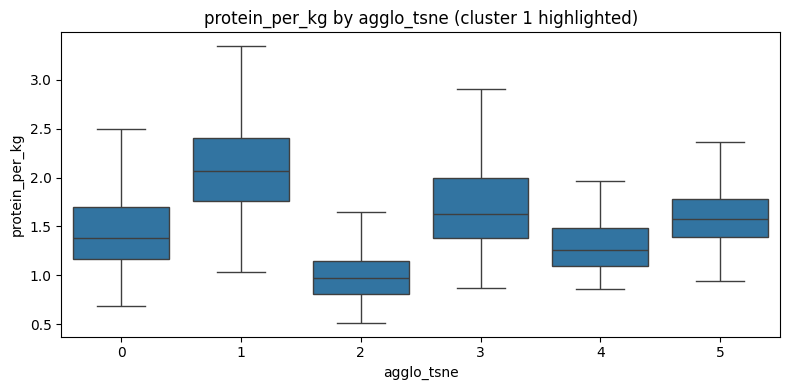

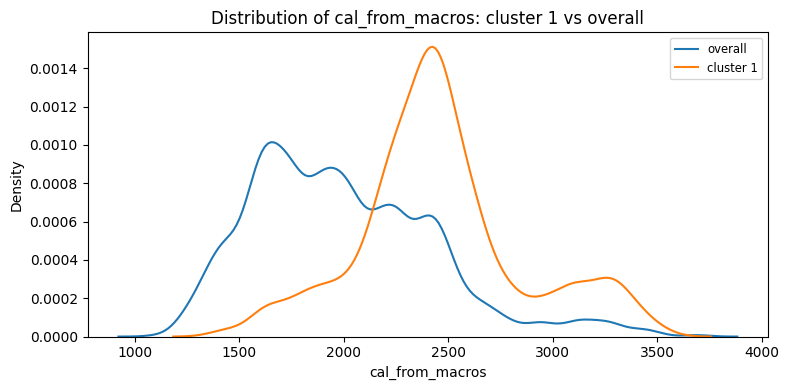

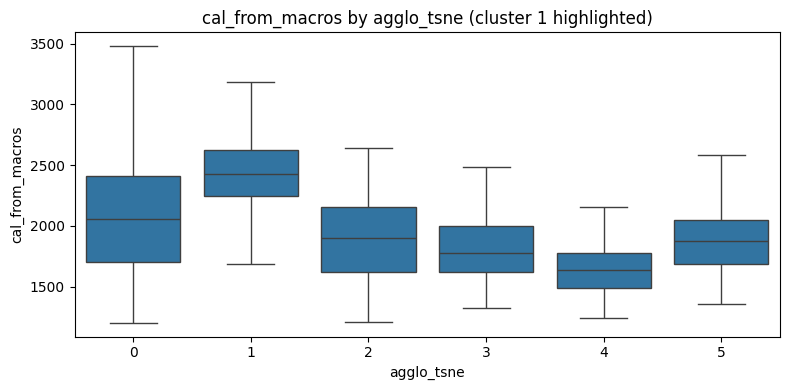

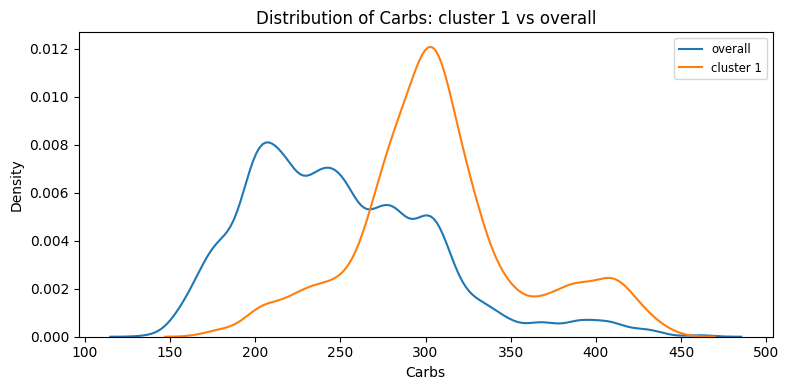

...

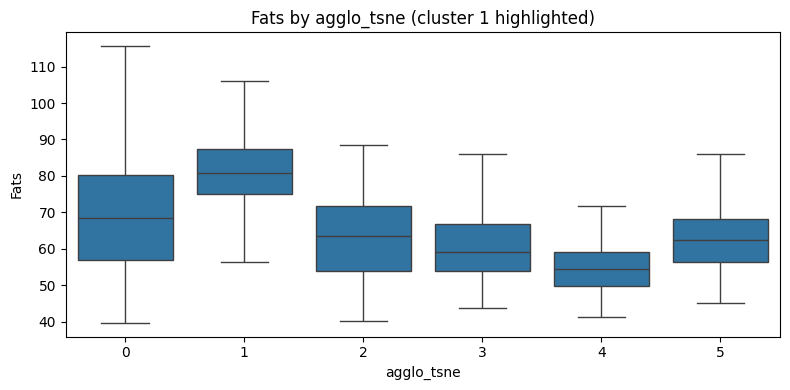

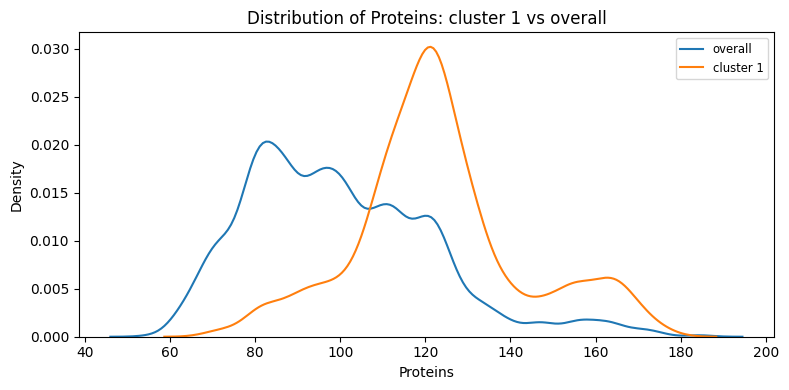

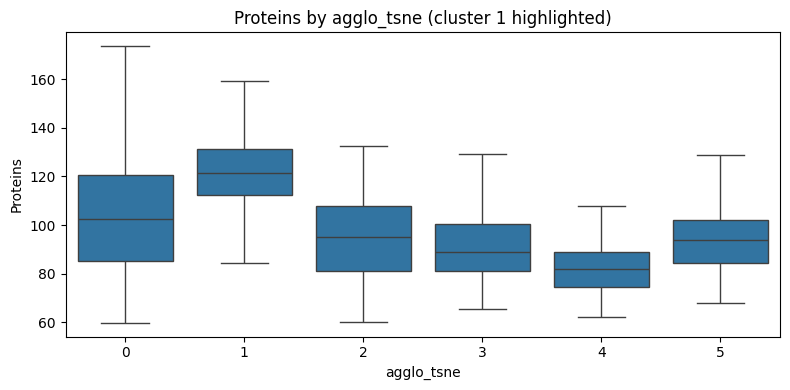

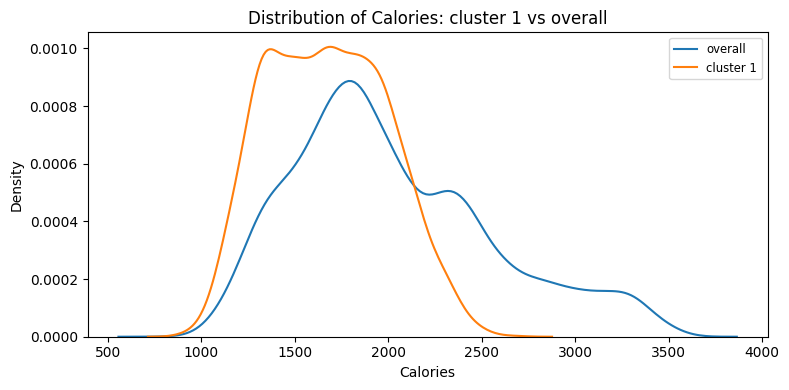

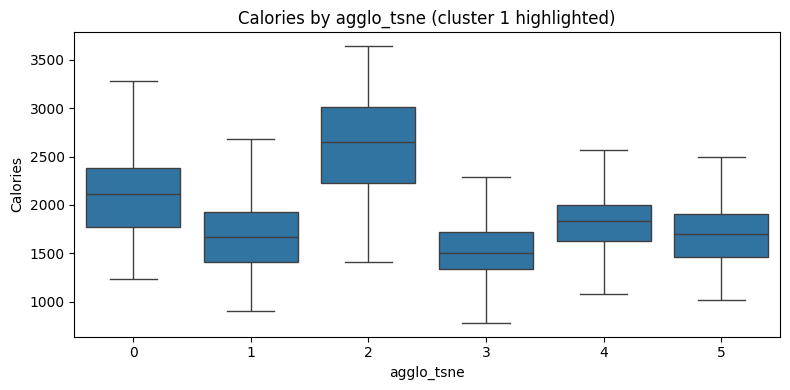

Cluster 1: n=3098, mean distance to center=29.365, std=12.834
  Outliers (dist > 3.0 std): 0 points

--- Cluster 3 (2400 points, 12.0% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
       feature  effect_size  cluster_mean  global_mean
      BMI_calc    -0.928021     18.702847    24.921651
           BMI    -0.928013     18.702946    24.921680
      Calories    -0.906028   1533.449167  2024.418300
Fat_Percentage    -0.880568     21.701856    26.101313
   Weight (kg)    -0.863343     55.619262    73.898832
  lean_mass_kg    -0.835427     43.344605    53.786384

Suggested label: slightly low BMI_calc, slightly low BMI, slightly low Calories, slightly low Fat_Percentage, slightly low Weight (kg), slightly low lean_mass_kg


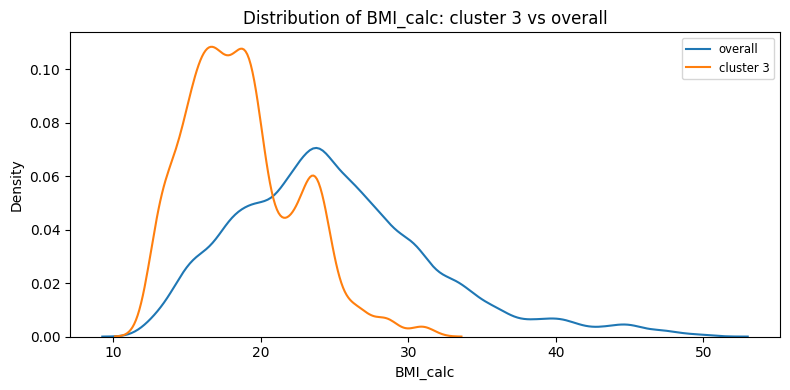

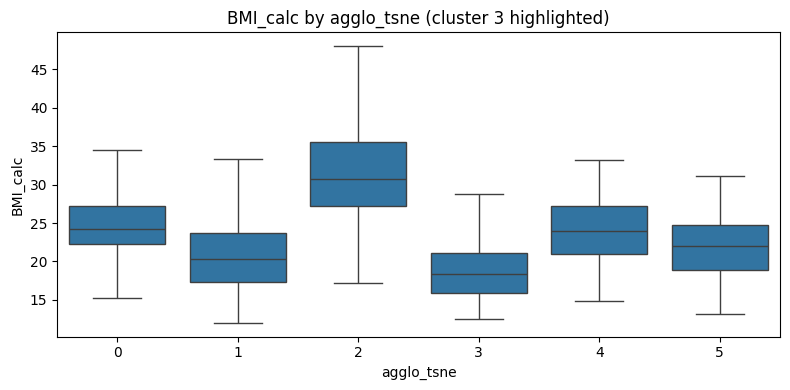

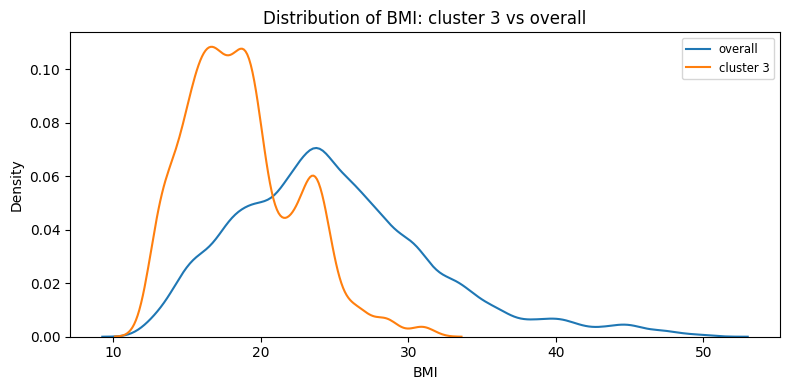

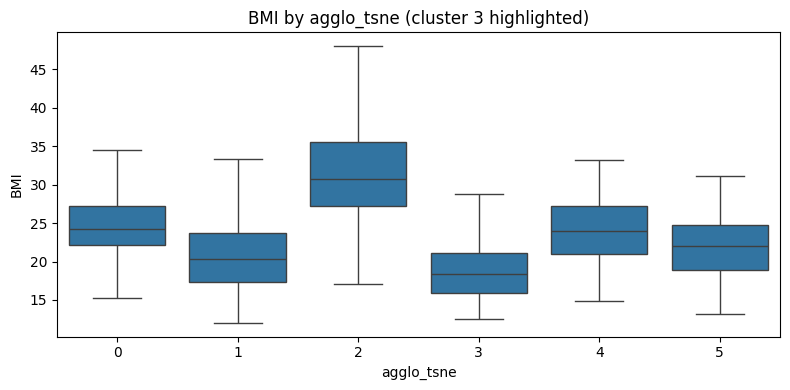

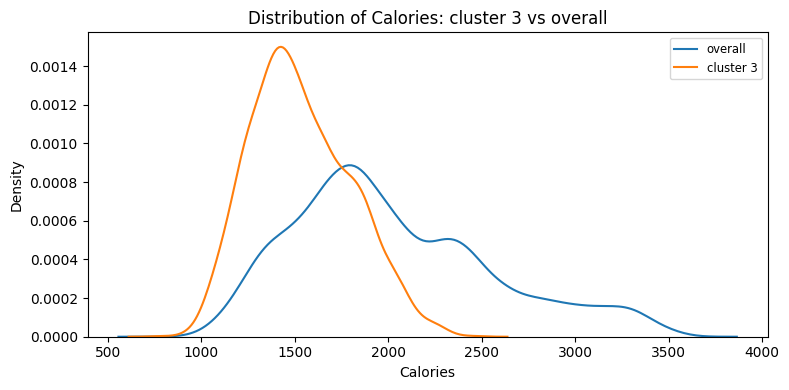

...

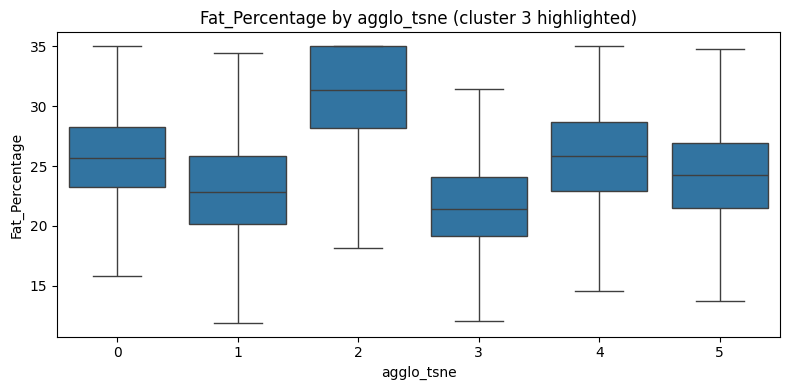

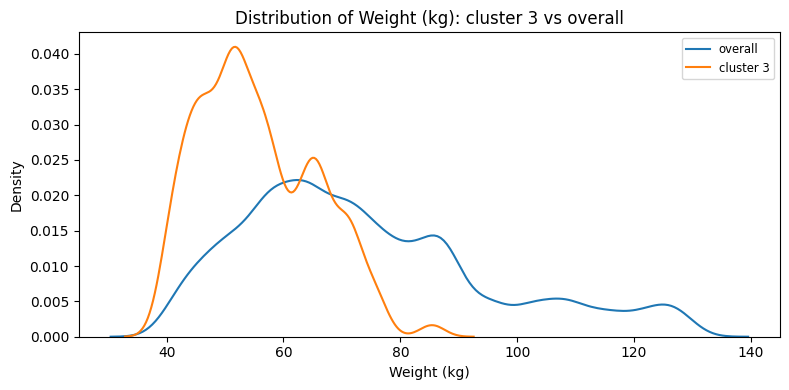

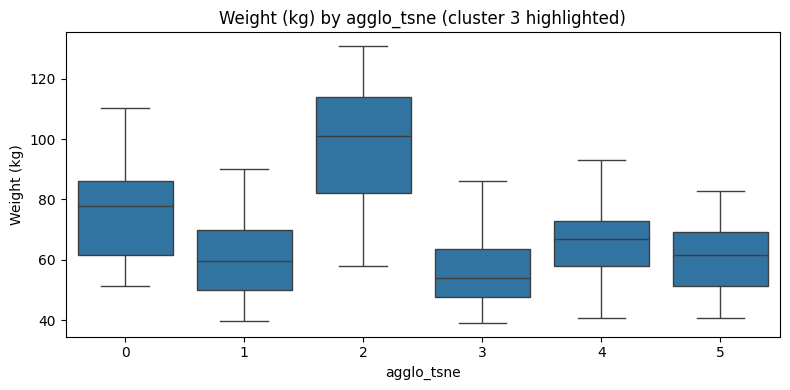

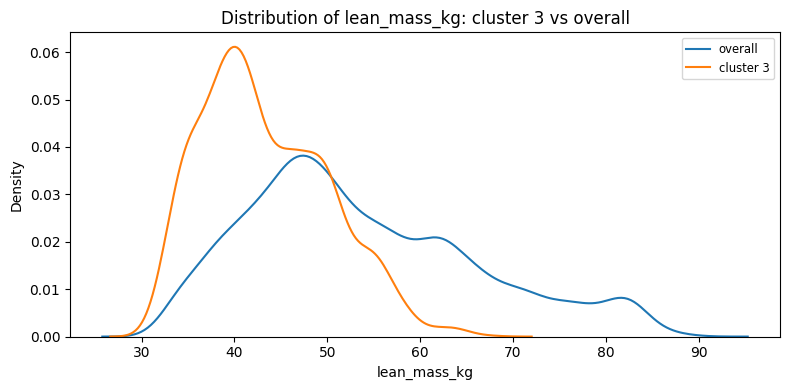

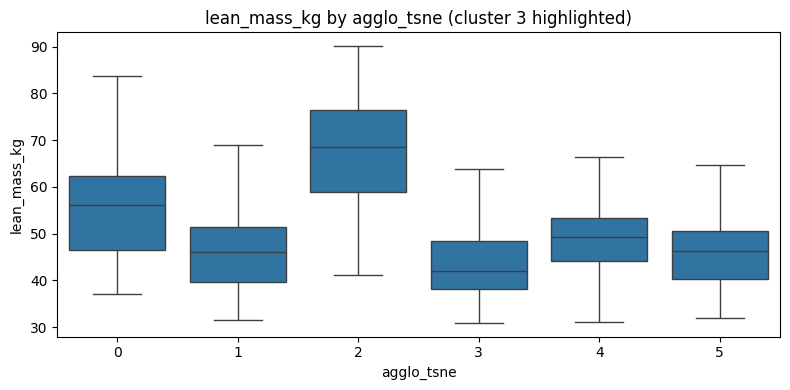

Cluster 3: n=2400, mean distance to center=24.348, std=9.610
  Outliers (dist > 3.0 std): 0 points

--- Cluster 4 (2282 points, 11.4% of data) ---

Top driving features (effect size, cluster_mean, global_mean):
              feature  effect_size  cluster_mean  global_mean
      cal_from_macros    -0.769139   1659.223344  1998.297076
                Carbs    -0.769065    207.396494   249.778592
             Proteins    -0.769064     82.965302    99.918290
                 Fats    -0.768997     55.308462    66.612172
Water_Intake (liters)    -0.760005      2.167892     2.627485
            pct_maxHR    -0.586868      0.745606     0.802305

Suggested label: slightly low cal_from_macros, slightly low Carbs, slightly low Proteins, slightly low Fats, slightly low Water_Intake (liters), slightly low pct_maxHR


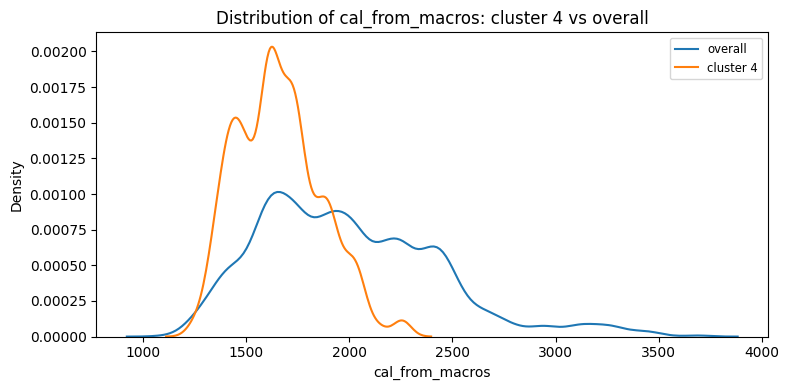

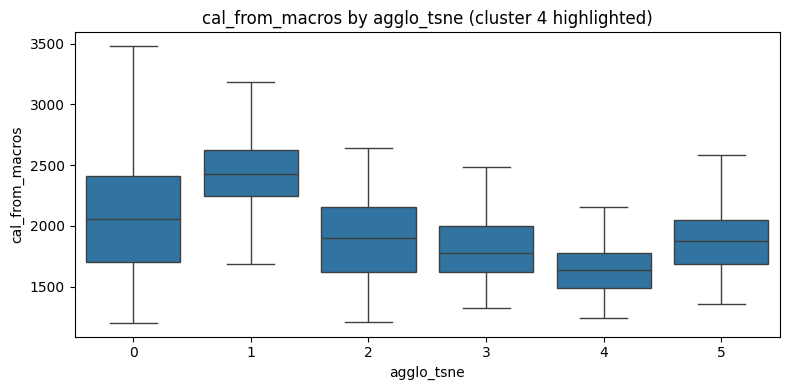

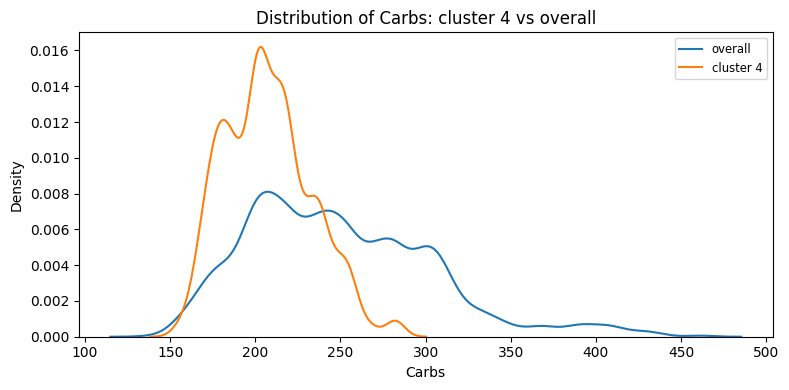

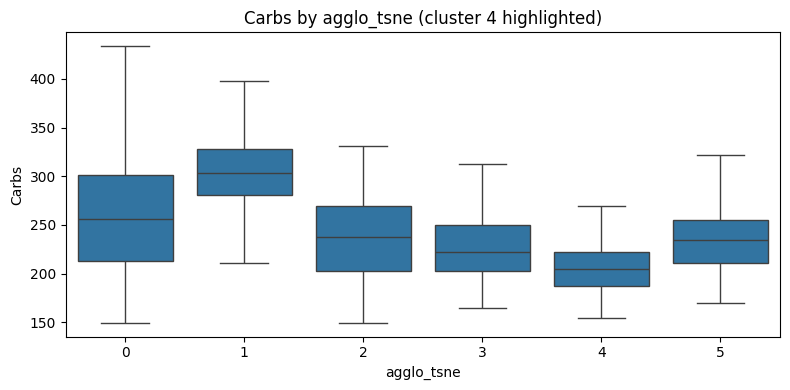

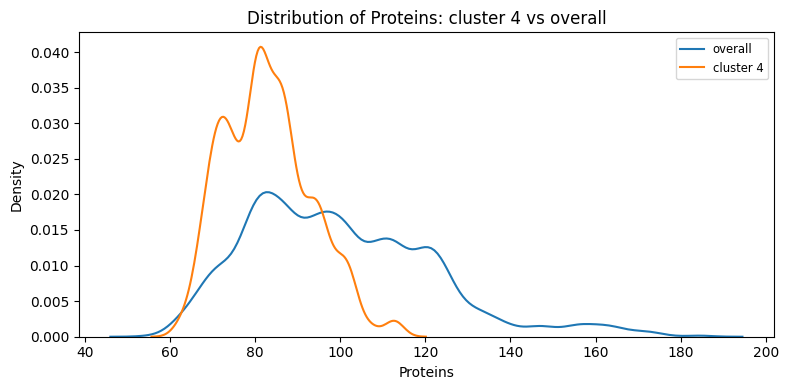

...

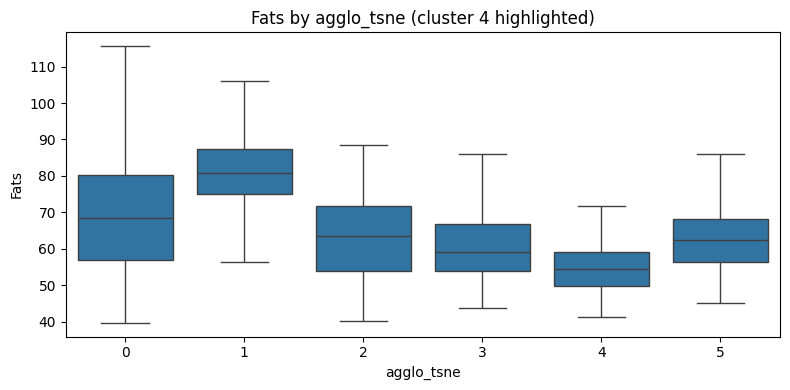

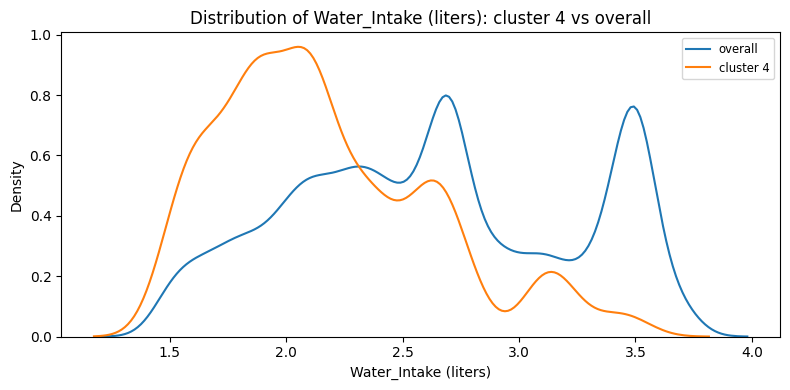

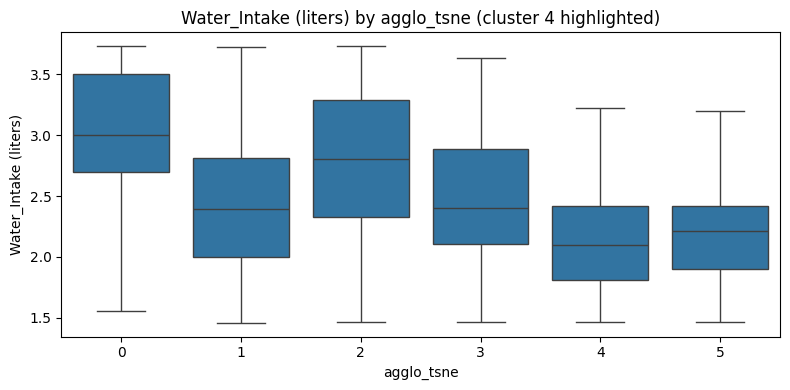

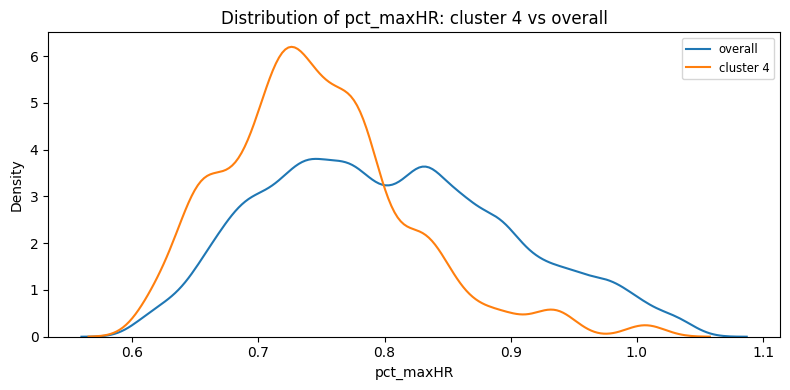

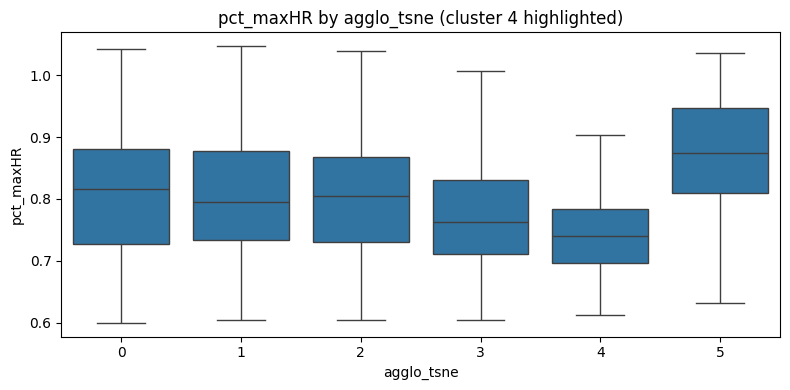

Cluster 4: n=2282, mean distance to center=24.870, std=10.663
  Outliers (dist > 3.0 std): 0 points


In [34]:
# === Analyze all clusterings (PCA + t-SNE, KMeans + Agglo) ===

# KMeans on PCA
if "kmeans_pca" in df_proc.columns:
    analyze_top_k_clusters(
        df=df_proc,
        features=FEATURES,
        cluster_col="kmeans_pca",
        top_clusters=6,
        top_feats_per_cluster=5,
        x_col="pca_x",
        y_col="pca_y"
    )

# Agglomerative on PCA
if "agglo_pca" in df_proc.columns:
    analyze_top_k_clusters(
        df=df_proc,
        features=FEATURES,
        cluster_col="agglo_pca",
        top_clusters=6,
        top_feats_per_cluster=5,
        x_col="pca_x",
        y_col="pca_y"
    )

# KMeans on t-SNE
if "kmeans_tsne" in df_proc.columns:
    analyze_top_k_clusters(
        df=df_proc,
        features=FEATURES,
        cluster_col="kmeans_tsne",
        top_clusters=5,
        top_feats_per_cluster=3,
        x_col="tsne_x",
        y_col="tsne_y"
    )

# Agglomerative on t-SNE
if "agglo_tsne" in df_proc.columns:
    analyze_top_k_clusters(
        df=df_proc,
        features=FEATURES,
        cluster_col="agglo_tsne",
        top_clusters=5,
        top_feats_per_cluster=6,
        x_col="tsne_x",
        y_col="tsne_y"
    )


#### Cluster interpretation

### K-Means on PCA (k = 6)

- **Cluster 1 – “Lean low-intake”**  
  Lower calories, body weight, lean mass, body fat and BMI → overall lighter athletes eating below average.

- **Cluster 5 – “Low-macro eaters”**  
  Carbs, fats, proteins and protein_per_kg all below average → normal-ish body, but consistently under-eating macros.

- **Cluster 0 – “High-macro eaters”**  
  Carbs, fats, proteins and total macro calories all above average → people fueling more than the rest.

- **Cluster 2 – “Heavy high-calorie bulkers”**  
  Much higher weight, calories, lean mass and BMI → classic “bulking / strongman-like” profile.

- **Cluster 4 – “Lean high-protein cutters”**  
  High protein per kg but low calories, weight, lean mass and fat% → looks like a lean group prioritising protein on a cut.

- **Cluster 3 – “High-exercise high-fuel”**  
  Very high physical exercise and very high macros → heavy training volume and heavy fueling.


### Agglomerative on PCA (k = 6)

- **Cluster 0 – “Light low-intake”**  
  Lower calories, weight, lean mass and BMI → small, relatively lightly fuelled athletes.

- **Cluster 1 – “High-macro eaters”**  
  Carbs, fats, proteins and macro calories above average → consistently high intake.

- **Cluster 4 – “Low-macro / low-protein”**  
  All macros and protein_per_kg clearly below average → under-fuelled, under-protein group.

- **Cluster 3 – “Heavy high-calorie bulkers”**  
  Very high weight, calories, lean mass and BMI → big, likely strength-oriented / bulked athletes.

- **Cluster 5 – “Lean high-protein cutters”**  
  High protein_per_kg with lower weight, calories, lean mass and fat% → lean, high-protein, diet-style group.

- **Cluster 2 – “High-exercise high-fuel”**  
  Very high physical exercise and very high macros → intense training and strong energy intake.


### K-Means on t-SNE (k = 3)

- **Cluster 1 – “Light low-intake”**  
  Lower calories, weight and lean mass → smaller athletes eating less.

- **Cluster 0 – “Heavier higher-BMI”**  
  Higher weight and BMI → heavier, higher-BMI group, likely more mass-focused.

- **Cluster 2 – “Experienced high-volume”**  
  Higher experience level, expected_burn and session duration → more advanced users with longer, harder sessions.


### Agglomerative on t-SNE (k = 5)

- **Cluster 2 – “Lean high-intensity”**  
  Slightly lower calories/weight/lean mass but higher pct_maxHR and pct_HRR → smaller athletes training at relatively high heart-rate intensity.

- **Cluster 0 – “Advanced high-volume athletes”**  
  Very high experience, session duration, expected_burn, calories burned and workout frequency → classic “advanced, high-volume” training group.

- **Cluster 3 – “Heavy surplus lifters”**  
  High weight, lean mass, calories, BMI and big positive cal_balance → heavy athletes in a clear calorie surplus (strongman/bulker-type).

- **Cluster 1 – “Low-macro dieters”**  
  Lower fats, carbs, proteins, protein_per_kg and a bit less water → people on a comparatively restrained, dieting-style intake.

- **Cluster 4 – “High-protein high-macro active”**  
  High protein_per_kg and all macros plus slightly more exercise → very active, well-fueled, high-protein group (think “serious lifters”).
